# CITS4012 — PIQA main model

The main model, the data preparation and the hyperparameter study are all
finished here.
The attention section is built in but has not been explored yet

### How to read this file

Every cell title starts with one of these:

| tag | meaning |
|---|---|
| `[RUN]` | run it, every time you open the notebook |
| `[RUN ONCE]` | run it once per session, it takes a few minutes |
| `[DONE]` | already run, results are written underneath — **do not re-run**|
| `[TO DO]` | not run yet, somebody still has to do this |

### Protocol — please keep these the same, or the numbers cannot be compared

* split: `train_test_split(test_size=0.15, random_state=0, stratify=label)` -> 13,696 / 2,417
* **the test set is not touched until 13 October**
* 3 seeds per configuration, report mean +/- sd
* 15 epochs for every run (the model improves slowly until epoch 12)
* pooled seed sd is about 0.004, so **a gap below 0.008 is not a real gap**

---
# PART 0 — Setup

In [1]:
# @title [RUN] Environment set-up
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from collections import Counter
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

cuda


In [2]:
# @title [RUN] Download the PIQA data from Drive
# the four PIQA files are zipped together on Drive, shared as "anyone with the link"
# so this works on any Colab account without uploading anything

piqa_data_id = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
!gdown -q $piqa_data_id -O piqa_data.zip
!unzip -q -o piqa_data.zip

import os
for file_name in ["train.jsonl", "train-labels.lst", "test.jsonl", "test-labels.lst"]:
    print(file_name, os.path.getsize(file_name), "bytes")


train.jsonl 4382162 bytes
train-labels.lst 32226 bytes
test.jsonl 495929 bytes
test-labels.lst 3676 bytes


---
# PART 1 — Data preparation

Nothing here needs changing. Run it all once and move on.

In [3]:
# @title [RUN] Step 1: Text processing and reading the data

# clean_str -> taken from A1
def clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()

def word_set(string):
    return set(clean_str(string).split())

# read one split into a flat list of rows ---------------------------------------
# structure -> [{'goal':.., 'sol1':.., 'sol2':.., 'label':0/1}]
# label 0 means sol1 is the correct one, label 1 means sol2
def read_piqa(data_path, label_path):
    rows = []
    data_line = open(data_path).readlines() # read JSON texts
    label_line = open(label_path).readlines() # read 0/1

    for line, lab in zip(data_line, label_line): # zip -> match the two files
        if lab.strip() == "": # skip empty lines
            continue
        d = json.loads(line) # JASON to dic
        row = {}
        row["goal"]  = d["goal"]
        row["sol1"]  = d["sol1"]
        row["sol2"]  = d["sol2"]
        row["label"] = int(lab.strip()) # from a different file. '1\n' -> 1 (int)
        rows.append(row)
    return rows
    # structure of rows
    # rows = [{'goal':'xxx', ..., "sol2":"xxx", "label":1}, {question}, {question}]

data_train_rows = read_piqa("train.jsonl", "train-labels.lst")
data_test_rows  = read_piqa("test.jsonl", "test-labels.lst")

print("train rows:", len(data_train_rows))
print("test rows :", len(data_test_rows))
print("") # Test
for r in data_train_rows[:2]:
    print("goal :", r["goal"])
    print("sol1 :", r["sol1"][:90])
    print("sol2 :", r["sol2"][:90])
    print("label:", r["label"])
    print("")

# train rows: 16113
# test rows : 1838

train rows: 16113
test rows : 1838

goal : When boiling butter, when it's ready, you can
sol1 : Pour it onto a plate
sol2 : Pour it into a jar
label: 1

goal : To permanently attach metal legs to a chair, you can
sol1 : Weld the metal together to get it to stay firmly in place
sol2 : Nail the metal together to get it to stay firmly in place
label: 0



In [4]:
# @title [RUN] Step 2: Data description table

def describe_data(rows, name):
    # one list per statistic -> fill them row by row, then average at the end
    goal_length     = []
    sol_length      = []
    label_list      = []
    jaccard         = []
    different_words = []

    for r in rows:
        goal_length.append(len(r["goal"].split()))

        # take the longer of the two solutions -> maxlength has to fit both
        sol_length.append(max(len(r["sol1"].split()), len(r["sol2"].split())))

        label_list.append(r["label"])

        # [how similar are the two solutions]----------------------------------
        # this is the whole difficulty of PIQA -> the two options are almost the same sentence
        a = word_set(r["sol1"])
        b = word_set(r["sol2"])

        # jaccard = shared words / all words -> 1 means identical, 0 means nothing in common
        jaccard.append(len(a & b) / len(a | b))

        # symmetric difference -> how many words are in one solution but not the other
        different_words.append(len(a ^ b))

    # [pack into one dict]-----------------------------------------------------
    output_row = {}
    output_row["set"]                  = name
    output_row["rows"]                 = len(rows)
    output_row["label=1 rate"]         = round(np.mean(label_list), 3)
    output_row["goal words"]           = round(np.mean(goal_length), 1)
    output_row["p95 goal words"]       = round(np.percentile(goal_length, 95))
    output_row["solution words"]       = round(np.mean(sol_length), 1)
    output_row["p95 sol words"]        = round(np.percentile(sol_length, 95))
    output_row["sol1 vs sol2 overlap"] = round(np.mean(jaccard), 3)
    output_row["different words"]      = round(np.mean(different_words), 1)
    return output_row


output_table = []
output_table.append(describe_data(data_train_rows, "training set"))

print("")
print("+++ PIQA Data +++")
print(pd.DataFrame(output_table).set_index("set").T.to_markdown())


+++ PIQA Data +++
|                      |   training set |
|:---------------------|---------------:|
| rows                 |      16113     |
| label=1 rate         |          0.5   |
| goal words           |          7.1   |
| p95 goal words       |         13     |
| solution words       |         19.4   |
| p95 sol words        |         54     |
| sol1 vs sol2 overlap |          0.654 |
| different words      |          5.4   |


In [5]:
# @title [RUN] Step 3: Split the training set

# PIQA rows are independent of each other, so a plain stratified split is fine.
# random_state is fixed so that everybody gets the same split -> numbers stay comparable.

all_label = [r["label"] for r in data_train_rows]
train_part1, train_part2 = train_test_split(data_train_rows, test_size=0.15,
                                            random_state=0, stratify=all_label)
# validation set: 15%
# random_state = 0 -> same seed for everyone
# strategy = all_label -> 50 / 50 split for sol 1 and sol 2 in the training set and val set

print("part1 (train) rows", len(train_part1))
print("part2 (val)   rows", len(train_part2))
print("test          rows", len(data_test_rows))
print("")
print("label=1 rate -> part1 %.3f, part2 %.3f" % (np.mean([r["label"] for r in train_part1]),
                                                  np.mean([r["label"] for r in train_part2])))

#part1 (train) rows 13696
#part2 (val)   rows 2417
#test          rows 1838
#label=1 rate -> part1 0.500, part2 0.500

part1 (train) rows 13696
part2 (val)   rows 2417
test          rows 1838

label=1 rate -> part1 0.500, part2 0.500


In [6]:
# @title [RUN] Step 4: Vocabulary and make_batch_input

# same idea as A1 -> pre-allocate np.zeros and write into it.
# the vectors are made inside the model by nn.Embedding, so here we only store the index.

maxgoal = 20   # -> p95 goal words: 13
maxsol  = 60   # -> p95 sol words: 54


def build_vocabulary(rows, min_count=2): # remove if word appears less than 2 times
    # built from the TRAINING part only, not from validation or test
    word_count = Counter() # each word appears how many times
    for r in rows:
        word_count.update(clean_str(r["goal"]).split())
        word_count.update(clean_str(r["sol1"]).split())
        word_count.update(clean_str(r["sol2"]).split())

    vocabulary = {"<pad>": 0, "<unk>": 1} # 0 and 1 are reserved -> 0 for padding, 1 for unknown
    for word, n in word_count.most_common():
        if n >= min_count:
            vocabulary[word] = len(vocabulary) # next free number
    return vocabulary
    # shape of vocabulary: a dict with 11488 entries -> {'<pad>':0, '<unk>':1, 'the':2, 'a':3, ...}


def words_to_index(word_list, vocabulary, maxlength):
    index_list = np.zeros(maxlength, dtype=np.int64) # initiate with all 0s
    for i, w in enumerate(word_list):
        if i == maxlength:
            break # cut off if longer than maxlength
        if w in vocabulary:
            index_list[i] = vocabulary[w]
        else:
            index_list[i] = 1                      # Assign to 1 if unknown
    return index_list
    # shape of index_list:['weld','the','metal'] becomes [847, 2, 311, 0, 0, ... 0]


def make_batch_input(rows, vocabulary):
    n = len(rows)
    goal_index = np.zeros((n, maxgoal), dtype=np.int64)
    sol1_index = np.zeros((n, maxsol), dtype=np.int64)
    sol2_index = np.zeros((n, maxsol), dtype=np.int64)
    label      = np.zeros(n, dtype=np.int64)

    for i, r in enumerate(rows):
        goal_index[i] = words_to_index(clean_str(r["goal"]).split(), vocabulary, maxgoal)
        sol1_index[i] = words_to_index(clean_str(r["sol1"]).split(), vocabulary, maxsol)
        sol2_index[i] = words_to_index(clean_str(r["sol2"]).split(), vocabulary, maxsol)
        label[i]      = r["label"]

    return goal_index, sol1_index, sol2_index, label
    # goal_index  (13696, 20)
    # sol1_index  (13696, 60)
    # sol2_index  (13696, 60)
    # label       (13696,)
    # "word, word, word, word" -> [ 5, 10, 15, 20, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 ]


vocabulary = build_vocabulary(train_part1, min_count=2)
print("vocabulary size:", len(vocabulary))

train_part1_input = make_batch_input(train_part1, vocabulary)
train_part2_input = make_batch_input(train_part2, vocabulary)
test_input        = make_batch_input(data_test_rows, vocabulary)


vocabulary size: 11488


In [ ]:
# @title [RUN] Step 5: Dumb baselines -> the floor [VIKA TO REPLACE BASELINE ANALYSIS]

# 50% is NOT the bar to beat. A word-overlap rule already gets 0.5259, so that is the number
# every model has to beat before it is worth anything. Same role as the TF-IDF baseline in A1.

part2_gold = train_part2_input[3]

def accuracy(predicted, gold):
    return np.mean(np.array(predicted) == np.array(gold))


# baseline 1 -> always pick sol2
b1 = accuracy(np.ones(len(train_part2), dtype=np.int64), part2_gold)

# baseline 2 -> pick the longer solution
predicted = []
for r in train_part2:
    if len(r["sol2"].split()) > len(r["sol1"].split()):
        predicted.append(1)
    else:
        predicted.append(0)
b2 = accuracy(predicted, part2_gold)

# baseline 3 -> pick the solution that shares more of its words with the goal
predicted = []
for r in train_part2:
    g = word_set(r["goal"])
    o1 = len(g & word_set(r["sol1"])) / max(1, len(word_set(r["sol1"])))
    o2 = len(g & word_set(r["sol2"])) / max(1, len(word_set(r["sol2"])))
    if o2 > o1:
        predicted.append(1)
    else:
        predicted.append(0)
b3 = accuracy(predicted, part2_gold)

output_table = []
output_table.append({"baseline": "always sol2",            "accuracy": round(b1, 4)})
output_table.append({"baseline": "longer solution",        "accuracy": round(b2, 4)})
output_table.append({"baseline": "more overlap with goal", "accuracy": round(b3, 4)})

print("")
print("+++ Baselines (validation) +++")
print(pd.DataFrame(output_table).to_markdown(index=False))

floor = max(b1, b2, b3)
print("")
print("floor to beat -> %.4f" % floor)



+++ Baselines (validation) +++
| baseline               |   accuracy |
|:-----------------------|-----------:|
| always sol2            |     0.5002 |
| longer solution        |     0.4841 |
| more overlap with goal |     0.5259 |

floor to beat -> 0.5259


---
# PART 2 — Attention

**This is the section Ray takes over.** The three attention mechanisms are written as three
plain functions, on purpose, so that they can be edited without touching the model class.

All three do exactly the same three steps:

```
1.  score   compare a query against a list of vectors   ->  one number per vector
2.  alpha   softmax the scores                          ->  weights that add up to 1
3.  output  weighted average using alpha
```

They only differ in **what gets scored** and **where the query comes from**:

| | what gets scored | query comes from | learnable params |
|---|---|---|---|
| `attention_on_solution` | the 60 solution words | the goal, or a trained vector | 40,000 (goal mode) / 200 (self mode) |
| `attention_on_goal` | the 20 goal words | a trained vector | 200 |
| `cross_attention` | one solution against the other | no query at all | 0 |

**Every function returns `(result, weights)`.** The weights are what you plot in a heat map,
so never drop them.

In [9]:
# @title [RUN] Step 6: The three attention functions   <-- RAY to adjust if needed

# ---------------------------------------------------------------------------------
# helper: squeeze a sequence of word vectors into ONE vector, ignoring the padding
# this is the "no attention" option -> every real word gets the same weight
# ---------------------------------------------------------------------------------
def masked_pool(rnn_output, index, pooling="mean"):
    # rnn_output -> (B, L, 2H)      index -> (B, L), 0 means padding
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        rnn_output = rnn_output.masked_fill(mask == 0, -1e9)
        return rnn_output.max(dim=1)[0]
    total = (rnn_output * mask).sum(dim=1)
    count = mask.sum(dim=1).clamp(min=1.0)
    return total / count


# ---------------------------------------------------------------------------------
# (1) ATTENTION ON THE SOLUTION
#     picks the important words inside ONE solution
#
#     query comes from outside:
#        goal mode -> query = W * goal_vector      (W is a Linear(200,200) in the model)
#        self mode -> query = a trained vector     (pool_query in the model)
#
#     returns -> context (B, 2H)   and   alpha (B, 60)   <- alpha is the heat map
# ---------------------------------------------------------------------------------
def attention_on_solution(solution_output, solution_index, query):
    # solution_output -> (B, 60, 2H)   query -> (B, 2H) or (2H,)
    if query.dim() == 1:
        score = torch.matmul(solution_output, query)              # (B, 60)
    else:
        score = torch.bmm(solution_output, query.unsqueeze(2)).squeeze(2)

    score   = score.masked_fill(solution_index == 0, -1e9)        # padding gets no attention
    alpha   = torch.softmax(score, dim=1)                         # (B, 60)
    context = torch.bmm(alpha.unsqueeze(1), solution_output).squeeze(1)
    return context, alpha


# ---------------------------------------------------------------------------------
# (2) ATTENTION ON THE GOAL
#     picks the important words inside the goal
#     goals are only about 7 words and roughly half of them are to / a / you / can,
#     so plain averaging dilutes the content words. This is meant to fix that.
#
#     returns -> goal_vector (B, 2H)   and   goal_alpha (B, 20)
# ---------------------------------------------------------------------------------
def attention_on_goal(goal_output, goal_index, query):
    score      = torch.matmul(goal_output, query)                 # (B, 20)
    score      = score.masked_fill(goal_index == 0, -1e9)
    goal_alpha = torch.softmax(score, dim=1)
    goal_vector = torch.bmm(goal_alpha.unsqueeze(1), goal_output).squeeze(1)
    return goal_vector, goal_alpha


# ---------------------------------------------------------------------------------
# (3) CROSS ATTENTION  -> what makes THIS solution different from the OTHER one
#
#     the two solutions differ by only about 5 words, so the discriminating signal is
#     the difference. For every word of this solution we find the closest word in the
#     other one, then keep whatever did not match.
#     soft alignment, same idea as ESIM (Chen et al. 2017).
#
#     no learnable parameters at all.
#     returns -> difference (B, 2H)   and   align (B, 60, 60)
# ---------------------------------------------------------------------------------
def cross_attention(current_sol_output, current_sol_index, other_sol_output, other_sol_index, pooling="mean"):
    similarity = torch.bmm(current_sol_output, other_sol_output.transpose(1, 2))      # (B, 60, 60)
    similarity = similarity.masked_fill((other_sol_index == 0).unsqueeze(1), -1e9)
    align      = torch.softmax(similarity, dim=2)                         # (B, 60, 60)
    aligned    = torch.bmm(align, other_sol_output)                           # (B, 60, 2H)

    # big where this word has no counterpart, near zero where the two match
    difference = current_sol_output - aligned
    return masked_pool(difference, current_sol_index, pooling), align


print("attention functions ready")

attention functions ready


---
# PART 3 — The model

The class only wires things together. All the attention maths lives in the three functions

```
goal      -> embedding -> BiLSTM -> pool or attention ------> goal_vector
solution  -> embedding -> BiLSTM -> word vectors
                                       |
                 goal_vector -> W -> query -> attention -> context
                                       |
                 this solution vs the other solution   -> difference
                                       |
        [ goal_vector ; context ; goal*context ; |goal-context| ; difference ]
                                       |
                                MLP -> one score

the SAME weights score sol1 and sol2, then softmax over the two scores
```

Scoring both solutions with shared weights matters: the two options are near-duplicates, so
what has to be learnt is a comparison, not an absolute judgement.

In [10]:
# @title [RUN] Step 7: The model

class PIQA_Model(nn.Module):
    def __init__(self, vocabulary_size,
                 dimension=100, n_hidden_input=100, dropout_input=0.5, num_layers_input=1,
                 rnn_type="LSTM", pooling="mean",
                 attention_type="none", goal_attention=False, use_cross_attention=False,
                 use_interaction=True, use_goal=True):
        super(PIQA_Model, self).__init__()

        # ---- the switches ------------------------------------------------------
        # attention_type       "none" | "goal" | "self"  -> attention on the solution words
        # goal_attention       True / False              -> attention on the goal words
        # use_cross_attention  True / False              -> compare the two solutions
        # use_interaction      True / False              -> goal*context and |goal-context|
        # use_goal             False -> goal is blanked out
        # **important** when use_goal is False the query becomes zero, so attention_type and goal_attention stop having any effect
        self.pooling             = pooling # method to collapse -> mean or max
        self.attention_type      = attention_type
        self.goal_attention      = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction     = use_interaction
        self.use_goal            = use_goal

        # ---- embedding ---------------------------------------------------------
        # embedding from scratch -> starts random
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        # 11488 words -> vocab size

        # ---- encoder -----------------------------------------------------------
        # ONE encoder for the goal and for BOTH solutions -> shared on purpose
        # the two solutions are near duplicates, so they must be scored by the same ruler
        if rnn_type == "GRU":
            self.encoder = nn.GRU(dimension, n_hidden_input,
                                  num_layers = num_layers_input,
                                  batch_first = True,
                                  bidirectional = True,
                                  dropout = dropout_input if num_layers_input > 1 else 0)
        else:
            self.encoder = nn.LSTM(dimension, n_hidden_input,
                                   num_layers = num_layers_input,
                                   batch_first = True,
                                   bidirectional = True,
                                   dropout = dropout_input if num_layers_input > 1 else 0)

        # ---- learnable parts of the attention --------------------------
        self.W          = nn.Linear(n_hidden_input*2, n_hidden_input*2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input*2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input*2) * 0.1)
        # W          -> used when attention_type = "goal",  40,000 parameters (matrix)
        #            -> from goal vector to query (B, 200) -> (B, 200)
        # pool_query -> used when attention_type = "self",     200 parameters (vector)
        # goal_query -> used when goal_attention = True,       200 parameters (vector)
        # cross attention has no parameters at all

        # ---- how wide is the input to the MLP ----------------------------------
        # 2H for every block we decide to put in (Bi)
        if self.use_interaction:
            score_input = n_hidden_input*2*4   # goal, context, goal*context, |goal-context|
        else:
            score_input = n_hidden_input*2*2   # goal, context

        if self.use_cross_attention:
            score_input = score_input + n_hidden_input*2   # plus difference

        # ---- MLP: many numbers -> score -------------------
        self.hidden_layer = nn.Linear(score_input, n_hidden_input)
        self.score_layer  = nn.Linear(n_hidden_input, 1)
        self.dropout      = nn.Dropout(dropout_input)


    # give ONE solution a score ---------------------------------------------------
    # goal_vector  (B, 2H)      current_sol_output  (B, 60, 2H)     other_sol_output (B, 60, 2H)
    # return -> score (B,) | alpha (B, 60) | align (B, 60, 60) or None
    def score_one_solution(self, goal_vector, current_sol_output, current_sol_index, other_sol_output, other_sol_index):

        # ---- pick the important words in the current solution ----
        if self.attention_type == "goal": # query = w (attention) x goal_vector | the goal decides which words are imporatant
            query = self.W(goal_vector)
            # goal_vector -> (B, 200) | goal_output (B, 20 or words, 200) -> averaged
            # self.w.weight -> (200 , 200) matrix
            # query -> (B, 200 / 2H) | Key or which words are important
            # to be removed:
            # goal 题目的词编号
            # goal_output 每个词的向量
            # goal_vector	整句话的向量（题目说了什么）
            # query	用来「搜索」的钥匙（要找什么）
            context, alpha = attention_on_solution(current_sol_output, current_sol_index, query)
            # sol_output (B, 60, 200) x query (B, 200) -> Alpha (B, 60) which words matter for solution
            # alpha -》60 个数字，每个 ≥ 0，加起来正好 = 1 ｜「这 60 个词各占多少比重」的分配表
            # context = 方案的重点摘要

        elif self.attention_type == "self":
            context, alpha = attention_on_solution(current_sol_output, current_sol_index, self.pool_query) #self attention for solutions
        else:
            context = masked_pool(current_sol_output, current_sol_index, self.pooling)   # no attention
            alpha   = torch.zeros_like(current_sol_index).float() # no alpha
        # shape of context: (B, 2H)      shape of alpha: (B, 60)

        # ---- put the pieces together ----
        if self.use_interaction:
            combined = torch.cat((goal_vector,
                                  context,
                                  goal_vector * context,                # -> do they match
                                  torch.abs(goal_vector - context)),    # -> how far apart
                                 dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        # ---- what makes THIS solution different from the other one ----
        align = None
        if self.use_cross_attention:
            difference, align = cross_attention(current_sol_output, current_sol_index,
                                                other_sol_output, other_sol_index, self.pooling)
            combined = torch.cat((combined, difference), dim=1)
        # shape of combined: (B, 1000) with everything on
        # align -> (B, 60, 60) | 60 -> words from sol1 / sol2

        # ---- score out ----
        combined = self.dropout(combined)
        hidden   = torch.relu(self.hidden_layer(combined))
        score    = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


    # goal (B, 20) | solution1 (B, 60) | solution2 (B, 60) ------------------------
    def forward(self, goal, solution1, solution2):

        # ---- encode everything once, with the SAME encoder ----
        goal_output, h = self.encoder(self.embedding(goal))         # -> (B, 20, 2H)
        sol1_output, h = self.encoder(self.embedding(solution1))    # -> (B, 60, 2H)
        sol2_output, h = self.encoder(self.embedding(solution2))    # -> (B, 60, 2H)
        # h is dropped because cannot use h (final state) only to run attention

        # ---- collapse the goal into one vector ----
        goal_alpha = None
        if self.goal_attention:
            goal_vector, goal_alpha = attention_on_goal(goal_output, goal, self.goal_query)
        else:
            goal_vector = masked_pool(goal_output, goal, self.pooling)
        # shape of goal_vector: (B, 2H)
        # goal_attention = True -> use goal_query to highlight key words
        # goal_attention = False -> simple average

        if self.use_goal == False:
            goal_vector = torch.zeros_like(goal_vector)   # -> CONTROL set, the model never sees the goal

        # ---- the SAME weights score both solutions, then we compare the scores ----
        score1, alpha1, align1 = self.score_one_solution(goal_vector,
                                                         sol1_output, solution1,
                                                         sol2_output, solution2)
        score2, alpha2, align2 = self.score_one_solution(goal_vector,
                                                         sol2_output, solution2,
                                                         sol1_output, solution1)

        output = torch.stack((score1, score2), dim=1)
        # shape of output: (B, 2) -> CrossEntropyLoss turns this into "sol1 or sol2"

        attention = {"sol1_alpha": alpha1,       # (B, 60)
                     "sol2_alpha": alpha2,       # (B, 60)
                     "goal_alpha": goal_alpha,   # (B, 20) or None
                     "sol1_align": align1,       # (B, 60, 60) or None
                     "sol2_align": align2}
        return output, attention


print("model class created")

model class created


---
# PART 4 — Training

In [7]:
# @title [RUN] Step 8: train and predict

# fix every source of randomness so the same config gives the same number twice for team collab ----
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # these two lines make it reproducible, but at some cost in speed.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# run the model over a whole set and collect the predictions ----------------------
# model_input -> (goal, sol1, sol2, label) from make_batch_input
# return -> predicted (n,) | alpha1 (n, 60) | alpha2 (n, 60)
def predict_all(model, model_input, batch_size=128):
    model.eval()
    goal, sol1, sol2, label = model_input

    predicted_list = []
    alpha1_list = []
    alpha2_list = []

    with torch.no_grad():
        # go through in chunks, otherwise the whole set hits the GPU at once
        for n in range(0, len(label), batch_size):
            batch_goal = torch.from_numpy(goal[n:n+batch_size]).to(device)
            batch_sol1 = torch.from_numpy(sol1[n:n+batch_size]).to(device)
            batch_sol2 = torch.from_numpy(sol2[n:n+batch_size]).to(device)

            output, attention = model(batch_goal, batch_sol1, batch_sol2)
            # output -> (B, 2), the score for sol1 and the score for sol2
            _, predicted = torch.max(output.data, 1)   # -> take the higher one, gives 0 or 1

            predicted_list.append(predicted.cpu().numpy())
            alpha1_list.append(attention["sol1_alpha"].cpu().numpy())
            alpha2_list.append(attention["sol2_alpha"].cpu().numpy())

    return np.concatenate(predicted_list), np.concatenate(alpha1_list), np.concatenate(alpha2_list)
    # predicted = [0, 1, 1, 0, 0, 1, ...]
    # alpha1[0] = [num, num, num, num, 0, 0, 0, ..., 0]
    # alpha2[0] = [num, num, num, num, 0, 0, 0, ..., 0]


# train one model and hand back the best epoch ------------------------------------
def train_model(model, train_input, val_input,
                learning_rate=0.001, batch_size=32, epochs=15,
                model_name="best_model.pt", quiet=False):

    goal, sol1, sol2, label = train_input
    val_gold = val_input[3]

    criterion = nn.CrossEntropyLoss()    # -> applies softmax itself, so the model returns raw scores
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_accuracy = 0

    for epoch in range(epochs):
        model.train()                    # -> dropout back ON
        train_loss = 0

        # new order every epoch -> the model never sees the same batches twice
        shuffled = np.random.permutation(len(label))

        for n in range(0, len(shuffled), batch_size):
            index = shuffled[n:n+batch_size]          # -> 32 row numbers
            batch_goal  = torch.from_numpy(goal[index]).to(device)
            batch_sol1  = torch.from_numpy(sol1[index]).to(device)
            batch_sol2  = torch.from_numpy(sol2[index]).to(device)
            batch_label = torch.from_numpy(label[index]).to(device)

            optimizer.zero_grad()
            output, attention = model(batch_goal, batch_sol1, batch_sol2)
            loss = criterion(output, batch_label)
            loss.backward()
            optimizer.step()

            train_loss = train_loss + loss.item()

        # check on the validation set after every epoch
        predicted, alpha1, alpha2 = predict_all(model, val_input)
        val_accuracy = np.mean(predicted == val_gold)

        if quiet == False:
            print("Epoch: %d, loss: %.2f, val accuracy: %.4f" % (epoch+1, train_loss, val_accuracy))

        # keep the BEST epoch, not the last one -> the model overfits after about epoch 6,
        # so the last epoch is usually worse than the peak (same as A1)
        if val_accuracy > best_accuracy:
            torch.save(model.state_dict(), model_name)
            if quiet == False:
                print("   saved a better model, Epoch: %d, old: %.4f, new: %.4f" % (epoch+1, best_accuracy, val_accuracy))
            best_accuracy = val_accuracy

    # load the best epoch back in, so whatever we return is the one we reported
    model.load_state_dict(torch.load(model_name))
    return model, best_accuracy


print("training functions ready")

training functions ready


In [8]:
# @title [RUN] Step 9: the sweep runner

# every experiment goes through this, so every result is produced the same way.
# the table stays in the output of each cell, so there is no separate log file.

def run_configurations(configuration_list, seeds=[0,1,2], epochs=15,
                       learning_rate=0.001, batch_size=32):
    # configuration_list -> [("name", {settings}), ("name", {settings}), ...]
    #                       anything not named in {settings} keeps the class default
    # return             -> {"name": [acc_seed0, acc_seed1, acc_seed2], ...}

    result = {}

    for name, settings in configuration_list:
        seed_accuracy = []
        for seed in seeds:
            set_seed(seed)
            model = PIQA_Model(len(vocabulary), **settings).to(device)
            model, best_value = train_model(model, train_part1_input, train_part2_input,
                                            learning_rate = learning_rate,
                                            batch_size    = batch_size,
                                            epochs        = epochs,
                                            model_name    = "tmp.pt",
                                            quiet         = True)
            seed_accuracy.append(best_value)
            print("  %-34s seed %d -> %.4f" % (name, seed, best_value))

            del model                     # -> free up RAM, same as A1
            torch.cuda.empty_cache()

        result[name] = seed_accuracy
        print("")

    # ---- the table ----
    output_table = []
    for name in result:
        a = result[name]
        output_table.append({"configuration": name,
                             "mean"       : round(float(np.mean(a)), 4),
                             "sd"         : round(float(np.std(a)), 4),
                             "seeds"      : str([round(float(x), 4) for x in a]),
                             "over floor" : round(float(np.mean(a)) - floor, 4)})
    print(pd.DataFrame(output_table).to_markdown(index=False))

    # how far the seeds move on their own -> a gap smaller than 2x this means nothing
    pooled_sd = np.mean([np.std(result[n]) for n in result])
    print("")
    print("pooled seed sd %.4f  ->  a gap smaller than %.4f means nothing" % (pooled_sd, 2*pooled_sd))

    return result


print("sweep runner ready")

sweep runner ready


---
# PART 5 — Hyperparameter study

**All of this is done on the NO-ATTENTION model**, so that the settings are chosen without
attention in the picture.

Base configuration everything is compared against:

```
attention_type = "none", use_cross_attention = True, use_interaction = True
dimension = 100, n_hidden = 100, layers = 1, pooling = "mean", lr = 0.001, batch = 32
```

In [ ]:
# @title [RUN ONCE] Record the environment
# determinism only holds on the same GPU and the same versions -> write it down

print("torch   ", torch.__version__)
print("cuda    ", torch.version.cuda)
print("cudnn   ", torch.backends.cudnn.version())
print("gpu     ", torch.cuda.get_device_name(0))
print("")
print("cudnn.deterministic", torch.backends.cudnn.deterministic)
print("cudnn.benchmark    ", torch.backends.cudnn.benchmark)

torch    2.11.0+cu130
cuda     13.0
cudnn    92700
gpu      Tesla T4

cudnn.deterministic True
cudnn.benchmark     False


In [13]:
# @title [RUN] The base configuration
# everything in PART 5 is compared against this. Run it before any sweep.

base_settings = {"attention_type"      : "none",
                 "use_cross_attention" : False,
                 "use_interaction"     : True,
                 "dropout_input"       : 0.25,
                 "dimension"           : 100,
                 "n_hidden_input"      : 100,
                 "num_layers_input"    : 1,
                 "pooling"             : "mean"}

print("base settings ready")


base settings ready


In [ ]:
# @title [RUN ONCE] Step 10: sanity check -> train one model and look at the curve

# run this once after opening the notebook, to confirm the pipeline works.
# expect validation accuracy to climb to about 0.60 and then flatten around epoch 6.

# set_seed(0)
# check_model = PIQA_Model(len(vocabulary), **base_settings).to(device)
# check_model, best_accuracy = train_model(check_model, train_part1_input, train_part2_input,
#                                          epochs = 15, model_name = "sanity.pt")

# print("")
# print("best validation accuracy %.4f   (floor %.4f)" % (best_accuracy, floor))

In [ ]:
import inspect
print("train_model       ", inspect.signature(train_model))
print("run_configurations", inspect.signature(run_configurations))

train_model        (model, train_input, val_input, learning_rate=0.001, batch_size=32, epochs=15, model_name='best_model.pt', quiet=False)
run_configurations (configuration_list, seeds=[0, 1, 2], epochs=15, learning_rate=0.001, batch_size=32)


In [ ]:
# @title [DONE] Step 11a: dropout sweep

# configuration_list = []
# for d in [0, 0.1, 0.25, 0.5]:
#     s = dict(base_settings)
#     s["dropout_input"] = d
#     configuration_list.append(("dropout %.2f" % d, s))

# result_dropout = run_configurations(configuration_list)


In [ ]:
# @title [Done] Step 11b: capacity -> embedding size, hidden size, layers

# does the model need to be bigger, or smaller?
# the base row is included on purpose -> it should come back at 0.5885 +/- 0.0029.
# if it does not, the environment has drifted and nothing in this cell is comparable.

# configuration_list = []

# s = dict(base_settings)
# configuration_list.append(("base (dim 100, hidden 100, 1 layer)", s))

# s = dict(base_settings); s["dimension"] = 50
# configuration_list.append(("dimension 50", s))

# s = dict(base_settings); s["n_hidden_input"] = 200
# configuration_list.append(("n_hidden 200", s))

# s = dict(base_settings); s["num_layers_input"] = 2
# configuration_list.append(("layers 2", s))

# result_capacity = run_configurations(configuration_list)

In [ ]:
# configuration_list = []

# s = dict(base_settings); s["dimension"] = 200
# configuration_list.append(("dimension 200", s))

# result_dimension = run_configurations(configuration_list)

In [ ]:
# configuration_list = []
# s = dict(base_settings); s["n_hidden_input"] = 50
# configuration_list.append(("n_hidden 50", s))

# result_hidden = run_configurations(configuration_list)

In [ ]:
# @title [Done] Step 11c: encoder, pooling, learning rate

# base is LSTM, mean pooling, lr 0.001 -> already measured at 0.6003 +/- 0.0032
# so only the OTHER values are run here. cuDNN is deterministic, so re-running the base
# would give exactly the same three numbers again -> no point spending the GPU on it.

# configuration_list = []

# s = dict(base_settings); s["rnn_type"] = "GRU"
# configuration_list.append(("GRU  (base is LSTM)", s))

# s = dict(base_settings); s["pooling"] = "max"
# configuration_list.append(("max pooling  (base is mean)", s))

# result_encoder = run_configurations(configuration_list)


# learning rate is an argument to run_configurations, not a model setting,
# so each value needs its own call and prints its own small table
# for lr in [0.0003, 0.003]:
#     run_configurations([("lr %.4f  (base is 0.001)" % lr, dict(base_settings))],
#                        learning_rate = lr)

In [ ]:
# for lr in [0.01]:
#     run_configurations([("lr %.4f  (base is 0.001)" % lr, dict(base_settings))],
#                        learning_rate = lr)

In [ ]:
# @title [Done] Step 11d: interaction features

# the interaction block is goal*context and |goal-context|, two extra 200-number blocks
# bolted onto the scorer input. It was added on MultiRC, where plain concatenation could
# not learn whether a candidate answer matched the passage, and it was carried straight
# over to PIQA without ever being tested here.
#
# the reason to doubt it: it only helps if the goal carries signal. Three of the four
# blocks feeding the MLP depend on the goal, so if the goal is weak these are dead weight.
#
#   use_interaction = True   [goal ; context ; goal*context ; |goal-context|]   800
#   use_interaction = False  [goal ; context]                                   400
#
#   with interaction   1,431,001 params
#   no interaction     1,391,001 params
#
# base already has use_interaction = True -> 0.6003 +/- 0.0032, so only False is run.

# configuration_list = []

# s = dict(base_settings); s["use_interaction"] = False
# configuration_list.append(("no interaction (400)", s))

# result_interaction = run_configurations(configuration_list)

# base cannot be compared inside the table above, so add its three seeds by hand

"""
  no interaction (400)               seed 0 -> 0.5875
  no interaction (400)               seed 1 -> 0.5825
  no interaction (400)               seed 2 -> 0.5995

| configuration        |   mean |     sd | seeds                    |   over floor |
|:---------------------|-------:|-------:|:-------------------------|-------------:|
| no interaction (400) | 0.5898 | 0.0071 | [0.5875, 0.5825, 0.5995] |        0.064 |
"""


'\n  no interaction (400)               seed 0 -> 0.5875\n  no interaction (400)               seed 1 -> 0.5825\n  no interaction (400)               seed 2 -> 0.5995\n\n| configuration        |   mean |     sd | seeds                    |   over floor |\n|:---------------------|-------:|-------:|:-------------------------|-------------:|\n| no interaction (400) | 0.5898 | 0.0071 | [0.5875, 0.5825, 0.5995] |        0.064 |\n'

In [ ]:
# @title [Done] Step 11e: does the model use the goal at all?

# CONTROL experiment, not a hyperparameter. use_goal=False zeroes the goal vector, so the
# model only sees the two solutions. If accuracy barely moves, the model is scoring the
# surface plausibility of each solution rather than answering the question. PIQA is known
# to contain annotation artefacts that make this possible.

# configuration_list = []
# s = dict(base_settings); s["use_goal"] = False
# configuration_list.append(("GOAL REMOVED (control)", s))

# result_control = run_configurations(configuration_list)


---
## Step 12 — Conclusion of the hyperparameter study


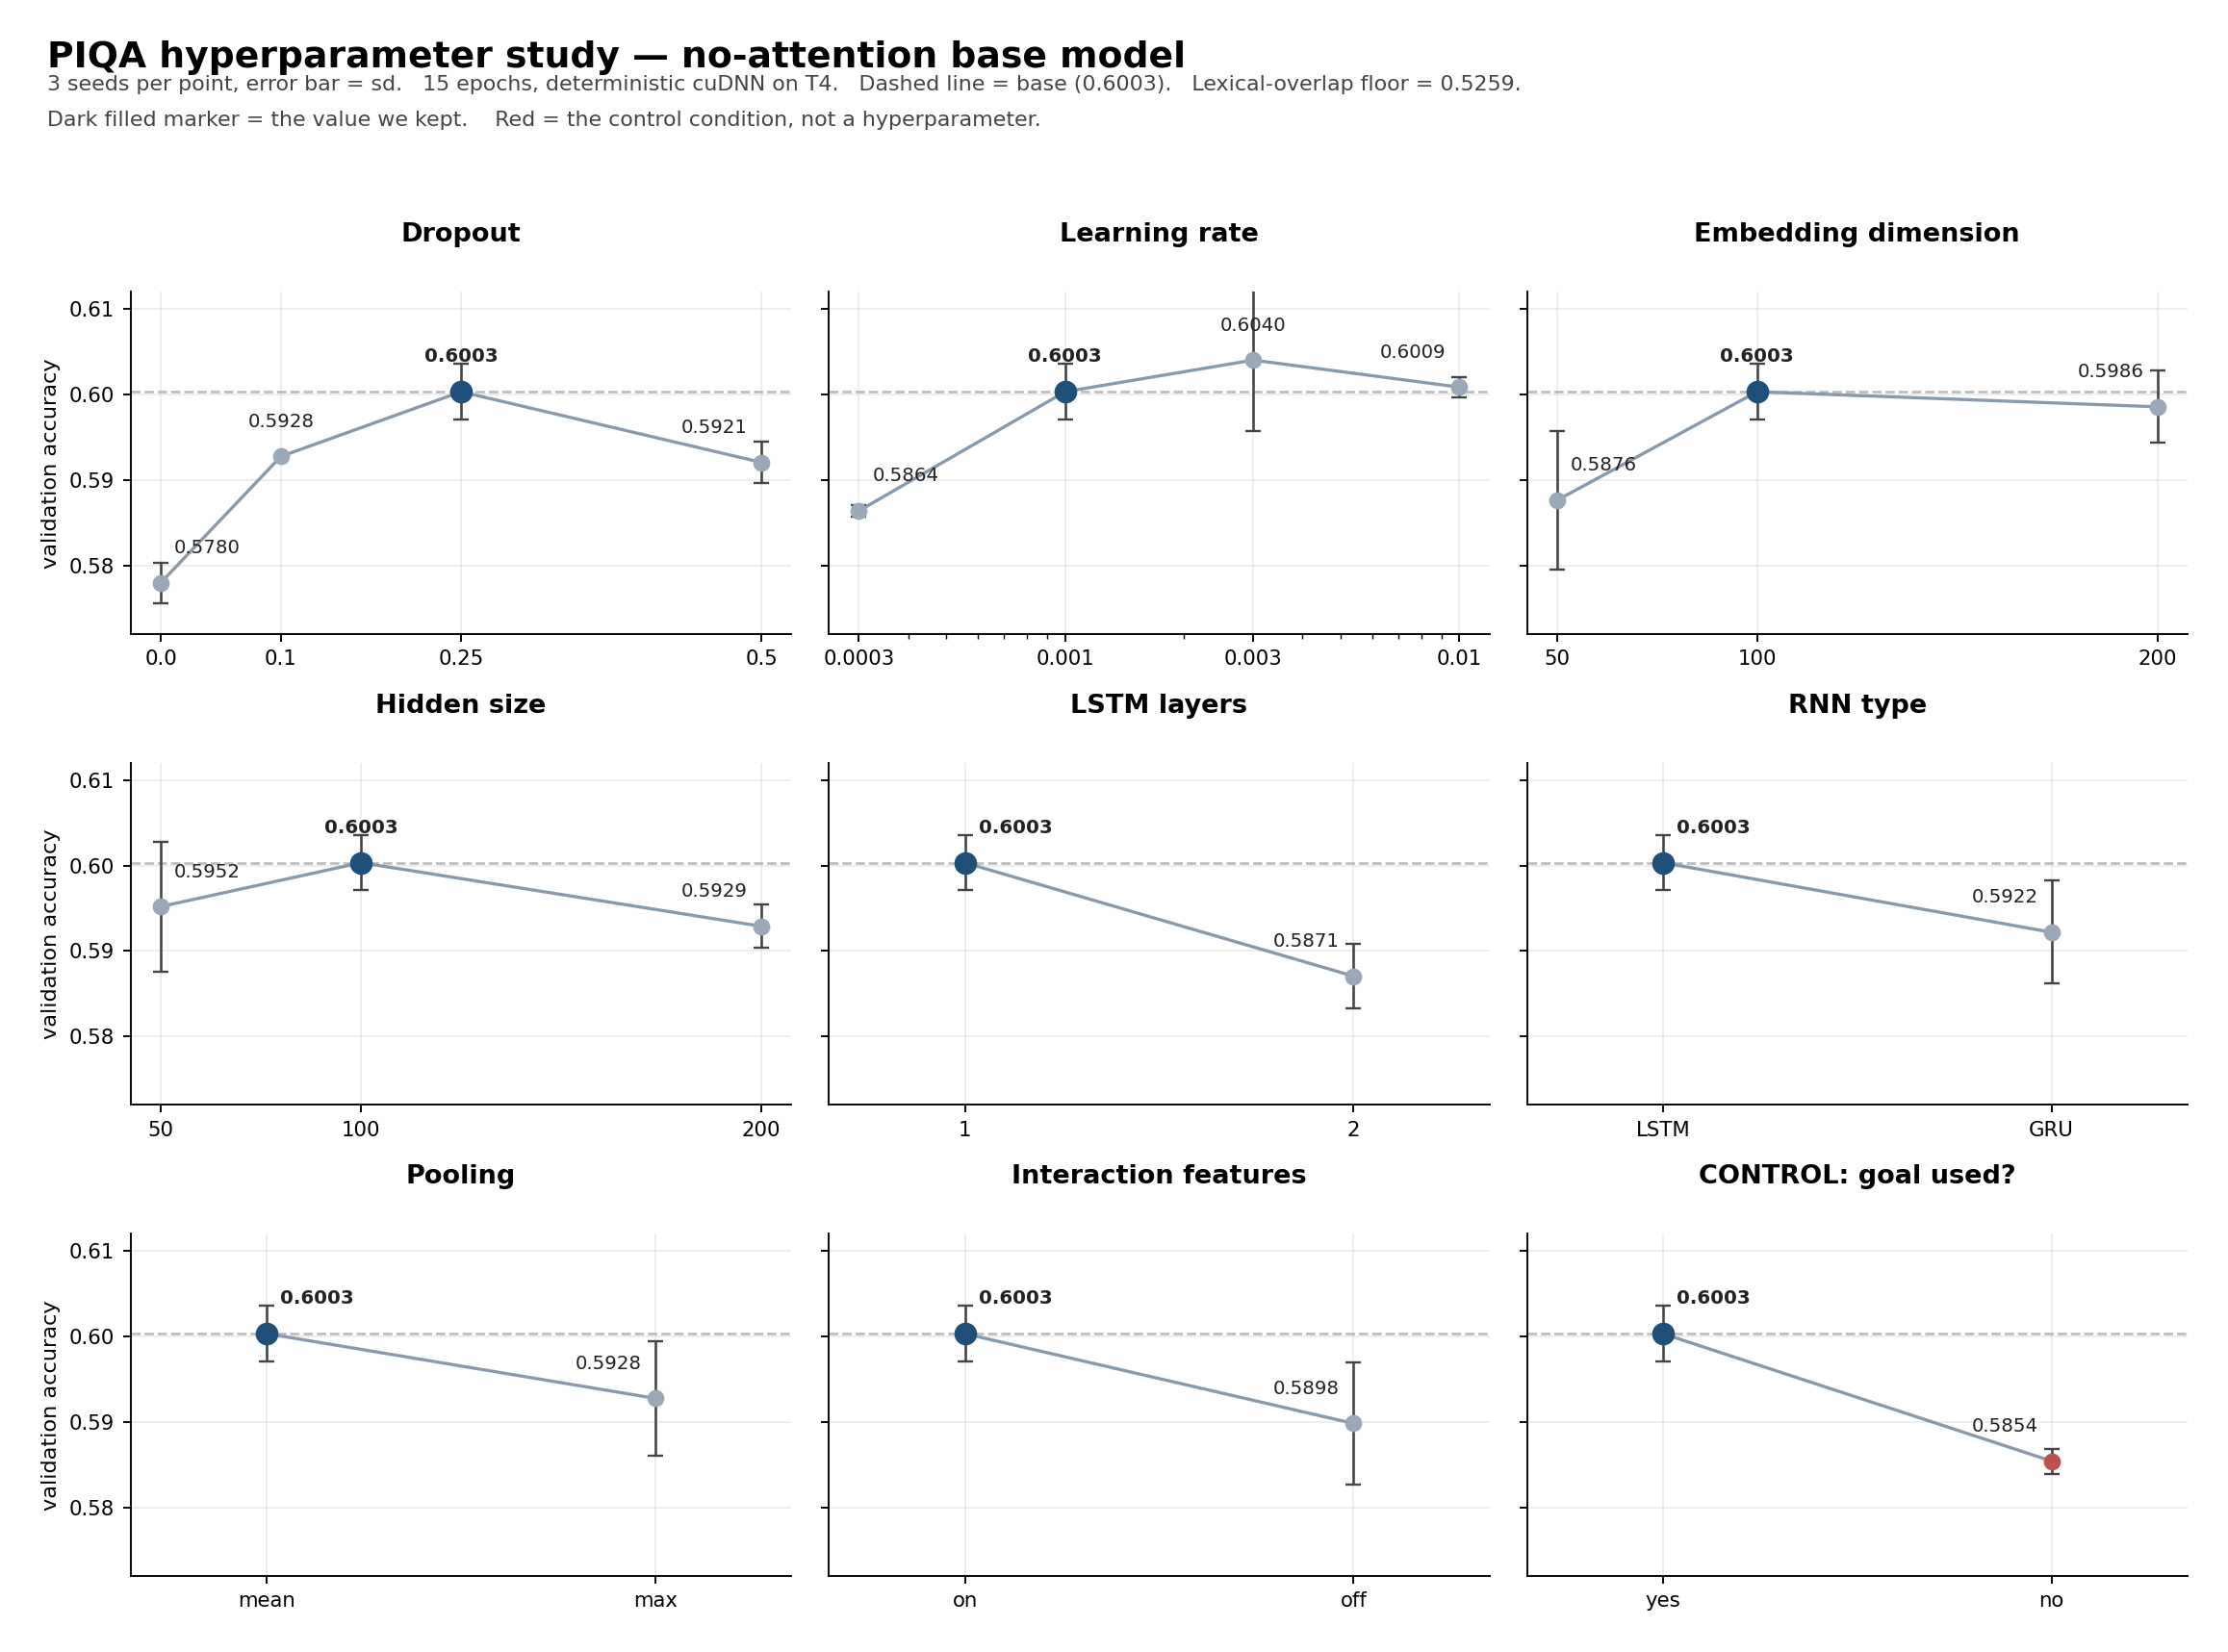

All runs: 3 seeds, 15 epochs, deterministic cuDNN on T4, same split.
Floor (lexical overlap) = 0.5259.  Base = **0.6003 ± 0.0032**, +0.0745 over floor.
Pooled seed sd across all configurations ≈ 0.005, so a gap below ~0.010 is not a real gap.

| hyperparameter | values tested | chosen | range | shape |
|---|---|---|---|---|
| **training** | | | | |
| dropout | 0 / 0.1 / **0.25** / 0.5 | 0.25 | 0.022 | inverted U, clear peak |
| learning rate | 0.0003 / **0.001** / 0.003 / 0.01 | 0.001 | 0.018 | floor below 0.001, flat above |
| epochs | 15, fixed | 15 | — | peak lands around epoch 12 |
| batch size | 32, not varied | 32 | — | — |
| **capacity** | | | | |
| embedding dim | 50 / **100** / 200 | 100 | 0.013 | elbow, 200 adds 86% params for nothing |
| hidden size | 50 / **100** / 200 | 100 | 0.007 | flat across the whole range |
| LSTM layers | **1** / 2 | 1 | 0.013 | monotone, 2 is worse (t = −3.78) |
| **structure** | | | | |
| RNN type | **LSTM** / GRU | LSTM | 0.008 | not distinguishable |
| pooling | **mean** / max | mean | 0.008 | not distinguishable |
| interaction features | **on** / off | on | 0.011 | favours on (t = −1.90, not significant) |

range = highest minus lowest mean across the values tested. It reflects how wide a range
we searched as much as how much the hyperparameter matters, so it is not an importance
ranking. 3 seeds per cell; pooled seed sd ≈ 0.005, so a gap below ~0.010 is not reliable.

### Control experiment (not a hyperparameter)

| | accuracy | vs base |
|---|---|---|
| goal used (base) | 0.6003 ± 0.0032 | — |
| **goal removed** | 0.5854 ± 0.0015 | **−0.0149, t = −5.93, significant** |

Decomposing the gain over the lexical floor: solution-only features contribute 0.0595,
the goal a further 0.0149, so about 20% of the model's advantage comes from reading the
goal. PIQA's known annotation artefacts are real but partial.

### What the study established

1. Four hyperparameters have measurable effects and four different shapes: dropout has a
   genuine optimum, learning rate has a floor, layers are monotone, embedding dimension
   has an elbow. Three (RNN type, pooling, hidden size) could not be distinguished from
   noise.
2. Configurations with reduced capacity (embedding 50, hidden 50) showed roughly twice the
   seed spread of the others (sd 0.008 vs 0.003), so the loss at small capacity comes
   partly from unstable optimisation, not only from the representational limit.
3. The model does use the goal, but most of its performance comes from the solutions alone.

### Methodological note

Fixing the random seed is not sufficient for reproducibility on GPU: cuDNN's LSTM backward
pass accumulates gradients non-deterministically, and identical seeds gave results
differing by up to 0.015. We enabled `cudnn.deterministic` and verified bit-identical
reproduction before collecting any number reported here. An earlier sweep run without it
reported a dropout effect in the opposite direction; that result was not reproducible and
is withdrawn.

---
# PART 6 — Handover notes for Ray

Everything below is settled. The attention section is yours.

---

## 1. Numbers you will need

| | |
|---|---|
| floor — best dumb baseline (word overlap with the goal) | **0.5259** |
| base — no-attention model, final settings | **0.6003 ± 0.0032** |
| base, the three seeds | `[0.6049, 0.5978, 0.5983]` |
| pooled seed sd across all 20+ configurations run so far | **≈ 0.005** |
| so: a gap below | **≈ 0.010 is not a real gap** |

```python
base_settings = {"attention_type"      : "none",
                 "use_cross_attention" : False,
                 "use_interaction"     : True,
                 "dropout_input"       : 0.25,
                 "dimension"           : 100,
                 "n_hidden_input"      : 100,
                 "num_layers_input"    : 1,
                 "pooling"             : "mean"}
# plus lr 0.001, batch 32, 15 epochs, seeds [0,1,2]
```

Every one of those values was chosen by a sweep — see PART 5. Please do not change them
while varying attention, or the comparison stops being controlled.

---

## 2. Protocol — do not change any of this

* **3 seeds** per configuration, report mean ± sd
* **15 epochs** for every run. The model peaks around epoch 12 and we keep the best epoch,
  so a different budget quietly inflates the score and the numbers stop being comparable.
* **same split**, `train_test_split(test_size=0.15, random_state=0, stratify=label)`
* **the test set is not touched until 13 October**, by anyone, for any reason
* **deterministic cuDNN stays on**. The two lines at the bottom of `set_seed` are not
  optional — see section 5.

---

## 3. The three attention functions — Step 6

All three live in one cell as plain functions, outside the model class, so you can edit
them without touching anything else. The class only calls them.

All three do the same three steps:


| | what gets scored | query | learnable params | switch |
|---|---|---|---|---|
| `attention_on_solution` | the 60 solution words | `W · goal_vector` (goal mode) or `pool_query` (self mode) | **40,000** / 200 | `attention_type` |
| `attention_on_goal` | the 20 goal words | `goal_query` | 200 | `goal_attention` |
| `cross_attention` | one solution against the other | none | **0** | `use_cross_attention` |

**Every function returns `(result, weights)`.** `forward` hands all the weights back in a
dict, so nothing in the model needs editing to plot anything:

```python
output, attention = model(goal, sol1, sol2)
attention["sol1_alpha"]   # (B, 60)        heat map over solution 1
attention["sol2_alpha"]   # (B, 60)
attention["goal_alpha"]   # (B, 20)  or None if goal_attention is off
attention["sol1_align"]   # (B, 60, 60)  or None if cross attention is off
attention["sol2_align"]   # (B, 60, 60)
```

---

## 4. How to run an experiment

```python
configuration_list = []

s = dict(base_settings); s["attention_type"] = "goal"
configuration_list.append(("goal attention", s))

s = dict(base_settings); s["attention_type"] = "self"
configuration_list.append(("self attention", s))

result = run_configurations(configuration_list)
```

To test against the base, add its seeds by hand and use `compare`:

```python
combined = {}
combined.update(result)
combined["base (no attention)"] = [0.6049, 0.5978, 0.5983]
compare(combined, "base (no attention)")
```

`compare` runs a Welch t-test. With 3 seeds the cutoff is **|t| > 4.3**, not 1.96.

---

## 5. Four things that will bite you

### a. Determinism is not automatic

cuDNN's LSTM backward pass accumulates gradients in a non-deterministic order, so the same
seed gives a different answer every run. We measured differences up to **0.015** — larger
than most of the effects in this study. The fix is already in `set_seed`:

```python
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
```

Verify it before trusting anything: train the same config twice and check the two numbers
are identical to six decimal places. Determinism holds only on the same GPU and the same
versions — ours is **Tesla T4, torch 2.11.0+cu130, cuDNN 92700**. If Colab gives you a
different card, your numbers will not line up with this file.

### b. `use_goal=False` is a master switch, not a normal ablation

When it is False the goal vector is zeroed, which makes the attention query zero, which
makes the attention weights uniform. So `use_goal=False` behaves exactly like
`attention_type="none"` no matter what the other switches say. Run that control once; do
not cross it with anything.

### c. The parameter count printed by `sum(p.numel())` is misleading

`W`, `pool_query` and `goal_query` are created every time, whichever switches are on. So
`attention_type="none"` and `attention_type="goal"` report the *same* total, even though
one of them is not using 40,000 of those parameters. Count only what is in use when you
report parameter counts in an ablation table — otherwise "which is better" gets confused
with "which is smaller", which is a real risk here (see 5d).

### d. Adding a parameter in the middle of `__init__` invalidates every earlier number

Initialisation consumes random numbers in order. Inserting a new `nn.Parameter` or
`nn.Linear` shifts the draw for every layer created after it, so the same seed produces a
different model. We lost a full batch of results to exactly this. **Add any new parameters
at the end of `__init__`.**

---

## 6. Results that are VOID — do not use them

An earlier batch of attention results (0.6039 / 0.6037 / 0.5994 / 0.5991 / 0.5988 /
0.5966 and friends) was collected before determinism was enabled, at 10 epochs, with a
different base. **None of it reproduces.** Ignore any table that quotes those numbers.

Also withdrawn: an early finding that "the goal contributes almost nothing". That was
measured on the void batch. The correct, reproducible measurement is in the next section.

---

## 7. One result you should know before you start

The control experiment has already been run properly:

| | accuracy | vs base |
|---|---|---|
| goal used (base) | 0.6003 ± 0.0032 | — |
| goal removed | 0.5854 ± 0.0015 | **−0.0149, t = −5.93, significant** |

**The goal carries real signal.** About 20% of the model's gain over the lexical floor
comes from reading it. That matters for you: goal-conditioned attention has something to
condition on, so it is a reasonable thing to build, not a dead end.

Please do not re-run this control — it costs 12 minutes and the answer is above.

---

## 8. For the attention analysis section of the report

The marking guide asks for visualisations plus analysis, with both successful and failed
predictions. A heat map on its own is the weak version of this. The strong version is a
number.

PIQA has no gold annotation of which words matter, so the stand-in is **the words that
differ between the two solutions** — on average only about 5 of them, often just one
(`weld` / `nail`, `butcher block oil` / `butcher knife oil`). Useful things to measure:

* how often the top-attended word is one of the differing words, against the chance rate
* whether that differs between correct and incorrect predictions
* `alpha.max()` per row, to show the attention is focused rather than collapsed to uniform
* how different `sol1_alpha` and `sol2_alpha` are from each other — the two solutions are
  near-duplicates, so this one is worth thinking about

Pick **short** examples for the figures. Solutions average 19 words but reach 88; a
heat map over a long one is unreadable.

---

## 9. Questions worth answering with your ablations

* Does any attention variant beat 0.6003 by more than 0.010?
* Does goal mode beat self mode? They differ by 40,000 parameters, so report both the
  accuracy and the parameter count.
* Does cross attention help, given that it has no parameters of its own and only widens
  the MLP input by 200?
* Under which variant, if any, does the goal become *more* useful than the 0.0149 above?

---

**Contact me before changing anything in PART 1–4.** The data pipeline, the metric and the
split have to stay fixed or none of our numbers can be put in the same table.

In [ ]:
# @title Step 13.1: Model and experiment configuration
# Runs four requested variants plus a cross-only reference, using the existing
# split, model class and train_model function. The reference makes the effect of
# adding goal-side attention to cross-attention measurable.

import datetime
import hashlib
import inspect
import io
import json
import os
import platform
import time
import uuid

# Colab VM 本地目录；runtime 重启/回收后其中的缓存和产物会消失。
ATTENTION_ABLATION_LOCAL_DIR = "/content/attention_ablation"
ATTENTION_ABLATION_SEEDS = (0, 1, 2)
ATTENTION_ABLATION_EPOCHS = 15
ATTENTION_ABLATION_LEARNING_RATE = 0.001
ATTENTION_ABLATION_BATCH_SIZE = 32



class PIQA_MeanMaxCross_Model(PIQA_Model):
    """Cross-attention experiment with masked-mean + masked-max residual pooling."""

    def __init__(self, vocabulary_size, cross_difference_pooling="masked_mean_max", **settings):
        if cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "cross_difference_pooling must be 'masked_mean_max'."
            )
        if not settings.get("use_cross_attention", False):
            raise ValueError("This experiment model requires use_cross_attention=True.")

        hidden_size = int(settings.get("n_hidden_input", 100))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling

        base_width = hidden_size * 2 * (4 if self.use_interaction else 2)
        # Mean and max each contribute one 2H vector.
        self.hidden_layer = torch.nn.Linear(base_width + hidden_size * 4, hidden_size)

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        if self.attention_type == "goal":
            query = self.W(goal_vector)
            context, alpha = attention_on_solution(
                current_sol_output, current_sol_index, query
            )
        elif self.attention_type == "self":
            context, alpha = attention_on_solution(
                current_sol_output, current_sol_index, self.pool_query
            )
        else:
            context = masked_pool(
                current_sol_output, current_sol_index, self.pooling
            )
            alpha = torch.zeros_like(current_sol_index).float()

        if self.use_interaction:
            combined = torch.cat(
                (
                    goal_vector,
                    context,
                    goal_vector * context,
                    torch.abs(goal_vector - context),
                ),
                dim=1,
            )
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        similarity = torch.bmm(
            current_sol_output, other_sol_output.transpose(1, 2)
        )
        similarity = similarity.masked_fill(
            (other_sol_index == 0).unsqueeze(1), -1e9
        )
        align = torch.softmax(similarity, dim=2)
        aligned_other = torch.bmm(align, other_sol_output)
        token_difference = current_sol_output - aligned_other

        current_mask = current_sol_index.ne(0).unsqueeze(2)
        masked_difference = token_difference.masked_fill(~current_mask, 0.0)
        valid_count = current_mask.sum(dim=1).clamp(min=1).to(token_difference.dtype)
        mean_difference = masked_difference.sum(dim=1) / valid_count

        max_difference = token_difference.masked_fill(
            ~current_mask, torch.finfo(token_difference.dtype).min
        ).max(dim=1).values
        has_valid_tokens = current_mask.any(dim=1)
        max_difference = torch.where(
            has_valid_tokens, max_difference, torch.zeros_like(max_difference)
        )

        combined = torch.cat(
            (combined, mean_difference, max_difference), dim=1
        )
        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_attention_experiment_model(vocabulary_size, settings):
    model_settings = dict(settings)
    pooling_mode = model_settings.pop("cross_difference_pooling", None)
    if model_settings.get("use_cross_attention", False):
        if pooling_mode != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must declare cross_difference_pooling='masked_mean_max'."
            )
        return PIQA_MeanMaxCross_Model(
            vocabulary_size,
            cross_difference_pooling=pooling_mode,
            **model_settings,
        )
    if pooling_mode is not None:
        raise ValueError(
            "cross_difference_pooling is only valid when cross-attention is enabled."
        )
    return PIQA_Model(vocabulary_size, **model_settings)


def build_attention_ablation_configs(base, model_class):
    # Start from the model's declared defaults and existing shared base settings.
    # Explicitly set all attention switches so a stale base flag cannot leak in.
    defaults = {
        name: parameter.default
        for name, parameter in inspect.signature(model_class.__init__).parameters.items()
        if name not in ("self", "vocabulary_size")
        and parameter.default is not inspect.Parameter.empty
    }
    variants = [
        ("no_attention", {
            "attention_type": "none",
            "goal_attention": False,
            "use_cross_attention": False,
        }),
        ("goal_attention_only", {
            "attention_type": "none",
            "goal_attention": True,
            "use_cross_attention": False,
        }),
        ("self_attention", {
            "attention_type": "self",
            "goal_attention": False,
            "use_cross_attention": False,
        }),
        ("cross_attention_plus_goal", {
            "attention_type": "none",
            "goal_attention": True,
            "use_cross_attention": True,
        }),
        ("cross_attention_only", {
            "attention_type": "none",
            "goal_attention": False,
            "use_cross_attention": True,
        }),
    ]
    configs = []
    for name, switches in variants:
        settings = dict(defaults)
        settings.update(base)
        settings.update(switches)
        if settings["use_cross_attention"]:
            settings["cross_difference_pooling"] = "masked_mean_max"
        configs.append((name, settings))
    return configs




In [ ]:
# @title Step 13.2: Fingerprinting and cache helpers

def _attention_hash_array(value):
    """Hash array values together with shape and dtype, without a giant bytes copy."""
    array = np.asarray(value)
    contiguous = np.ascontiguousarray(array)
    digest = hashlib.sha256()
    digest.update(str(contiguous.dtype).encode("utf-8"))
    digest.update(json.dumps(list(contiguous.shape)).encode("utf-8"))
    digest.update(memoryview(contiguous).cast("B"))
    return digest.hexdigest()


def _attention_hash_vocabulary(vocab):
    # Vocabulary IDs determine which embedding row each token uses.
    canonical = sorted(((str(token), int(index)) for token, index in vocab.items()), key=lambda item: (item[0], item[1]))
    payload = json.dumps(canonical, ensure_ascii=False, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def _attention_code_fingerprint():
    code_markers = {
        "PIQA_Model": "class PIQA_Model(",
        "PIQA_MeanMaxCross_Model": "class PIQA_MeanMaxCross_Model(",
        "attention_on_solution": "def attention_on_solution(",
        "attention_on_goal": "def attention_on_goal(",
        "cross_attention": "def cross_attention(",
        "masked_pool": "def masked_pool(",
        "train_model": "def train_model(",
        "predict_all": "def predict_all(",
        "set_seed": "def set_seed(",
    }

    history = globals().get("In", [])
    resolved_sources = {}

    for name, marker in code_markers.items():
        source = next(
            (
                cell_source
                for cell_source in reversed(history)
                if isinstance(cell_source, str) and marker in cell_source
            ),
            None,
        )
        if source is None:
            raise RuntimeError(
                f"找不到 {name} 的已执行源码；请先运行对应定义单元，再运行 Step 12。"
            )
        resolved_sources[name] = source

    digest = hashlib.sha256()
    source_hashes = {}

    for name, source in resolved_sources.items():
        source_hash = hashlib.sha256(source.encode("utf-8")).hexdigest()
        source_hashes[name] = source_hash
        digest.update(name.encode("utf-8"))
        digest.update(source.encode("utf-8"))

    return digest.hexdigest(), source_hashes


def _attention_data_fingerprint(vocab, train_input, val_input):
    return {
        "vocabulary_sha256": _attention_hash_vocabulary(vocab),
        "train_sha256": hashlib.sha256("".join(_attention_hash_array(part) for part in train_input).encode("ascii")).hexdigest(),
        "validation_sha256": hashlib.sha256("".join(_attention_hash_array(part) for part in val_input).encode("ascii")).hexdigest(),
    }


def _attention_cache_key(config_name, settings, seed, code_hash, data_hashes):
    runtime = {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "device": str(device),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
        "cudnn_benchmark": bool(torch.backends.cudnn.benchmark),
    }
    spec = {
        "configuration": config_name,
        "settings": settings,
        "seed": int(seed),
        "epochs": ATTENTION_ABLATION_EPOCHS,
        "learning_rate": ATTENTION_ABLATION_LEARNING_RATE,
        "batch_size": ATTENTION_ABLATION_BATCH_SIZE,
        "vocabulary_size": len(vocabulary),
        "data_hashes": data_hashes,
        "model_training_code_sha256": code_hash,
        "runtime": runtime,
    }
    canonical = json.dumps(spec, sort_keys=True, ensure_ascii=False, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest(), spec


def _attention_read_cache_entry(cache_dir, cache_filename, cache_key):
    """Read a matching local cache record and its existing checkpoint, if present."""
    cache_path = os.path.join(cache_dir, cache_filename)
    try:
        with open(cache_path, encoding="utf-8") as cache_file:
            entry = json.load(cache_file)
    except FileNotFoundError:
        return None
    except (json.JSONDecodeError, UnicodeDecodeError):
        return None

    if entry.get("cache_key") != cache_key:
        return None
    checkpoint_name = entry.get("checkpoint_filename")
    if not checkpoint_name or os.path.basename(checkpoint_name) != checkpoint_name:
        return None
    checkpoint_path = os.path.join(cache_dir, checkpoint_name)
    if not os.path.isfile(checkpoint_path):
        return None
    entry["_checkpoint_path"] = checkpoint_path
    return entry




In [ ]:
# @title Step 13.3: Attention ablation training function

def run_attention_ablation():
    required = (
        "base_settings", "PIQA_Model", "train_model", "set_seed", "vocabulary",
        "device", "train_part1_input", "train_part2_input",
    )
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Run the setup, data preparation, model and base-configuration cells first. "
            "Missing: " + ", ".join(missing)
        )

    configs = build_attention_ablation_configs(base_settings, PIQA_Model)
    config_names = [name for name, _ in configs]
    expected_switches = {
        "no_attention": ("none", False, False),
        "goal_attention_only": ("none", True, False),
        "self_attention": ("self", False, False),
        "cross_attention_plus_goal": ("none", True, True),
        "cross_attention_only": ("none", False, True),
    }
    actual_switches = {
        name: (
            settings["attention_type"],
            settings["goal_attention"],
            settings["use_cross_attention"],
        )
        for name, settings in configs
    }
    if actual_switches != expected_switches:
        raise RuntimeError("Attention ablation switches do not match the agreed experiment matrix.")
    if tuple(ATTENTION_ABLATION_SEEDS) != (0, 1, 2) or ATTENTION_ABLATION_EPOCHS != 15:
        raise RuntimeError("Seeds/epochs differ from the agreed experiment protocol.")

    run_id = (
        datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        + "_" + uuid.uuid4().hex[:8]
    )
    prefix = "attention_ablation_" + run_id

    # Create and verify a writable Colab-local output directory; no Drive authentication/API is used.
    local_output_dir = os.path.abspath(ATTENTION_ABLATION_LOCAL_DIR)
    os.makedirs(local_output_dir, exist_ok=True)
    write_probe = os.path.join(local_output_dir, ".step12_write_check_" + run_id)
    with open(write_probe, "w", encoding="utf-8") as probe_file:
        probe_file.write("ok")
    os.remove(write_probe)

    experiment_started = time.perf_counter()

    # Fingerprint exact inputs and executable model/training sources once per run.
    # If source inspection fails, stop rather than silently reusing an unverifiable cache.
    code_hash, _ = _attention_code_fingerprint()
    data_hashes = _attention_data_fingerprint(
        vocabulary, train_part1_input, train_part2_input
    )

    cache_plan = {}
    for config_name, settings in configs:
        for seed in ATTENTION_ABLATION_SEEDS:
            cache_key, cache_spec = _attention_cache_key(
                config_name, settings, seed, code_hash, data_hashes
            )
            cache_filename = f"attention_ablation_cache_{cache_key}.json"
            entry = _attention_read_cache_entry(
                local_output_dir, cache_filename, cache_key
            )
            cache_plan[(config_name, seed)] = {
                "cache_key": cache_key,
                "cache_filename": cache_filename,
                "cache_spec": cache_spec,
                "entry": entry,
            }



    metric_rows = []
    for config_name, settings in configs:
        for seed in ATTENTION_ABLATION_SEEDS:
            plan = cache_plan[(config_name, seed)]
            set_seed(seed)
            model = _build_attention_experiment_model(len(vocabulary), settings).to(device)
            local_checkpoint = os.path.join(
                local_output_dir, f"{prefix}_{config_name}_seed{seed}.pt"
            )
            cache_hit = False
            checkpoint_load_seconds = 0.0
            cached_training_seconds = 0.0
            training_seconds = 0.0
            best_accuracy = None
            checkpoint_name = None
            checkpoint_sha256 = None

            entry = plan["entry"]
            if entry is not None:
                load_started = time.perf_counter()
                try:
                    cached_checkpoint_path = entry["_checkpoint_path"]
                    with open(cached_checkpoint_path, "rb") as checkpoint_file:
                        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
                    if checkpoint_sha256 != entry.get("checkpoint_sha256"):
                        raise ValueError("Cached checkpoint SHA-256 does not match its JSON record.")
                    try:
                        state_dict = torch.load(
                            cached_checkpoint_path, map_location=device, weights_only=True
                        )
                    except TypeError:
                        state_dict = torch.load(cached_checkpoint_path, map_location=device)
                    model.load_state_dict(state_dict)
                    best_accuracy = float(entry["best_validation_accuracy"])
                    cached_training_seconds = float(entry.get("training_seconds", 0.0))
                    checkpoint_name = entry.get("checkpoint_filename")
                    cache_hit = True
                    checkpoint_load_seconds = time.perf_counter() - load_started
                except Exception as exc:
                    print(
                        f"{config_name} seed {seed}: cache entry invalid ({exc}); retraining."
                    )
                    set_seed(seed)
                    model = _build_attention_experiment_model(len(vocabulary), settings).to(device)
                    best_accuracy = None

            if not cache_hit:
                training_started = time.perf_counter()
                model, best_accuracy = train_model(
                    model,
                    train_part1_input,
                    train_part2_input,
                    learning_rate=ATTENTION_ABLATION_LEARNING_RATE,
                    batch_size=ATTENTION_ABLATION_BATCH_SIZE,
                    epochs=ATTENTION_ABLATION_EPOCHS,
                    model_name=local_checkpoint,
                    quiet=True,
                )
                training_seconds = time.perf_counter() - training_started
                with open(local_checkpoint, "rb") as checkpoint_file:
                    checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()

                checkpoint_name = os.path.basename(local_checkpoint)

                # Keep the cache record only after the local checkpoint is fully written.
                cache_record = {
                    "cache_key": plan["cache_key"],
                    "cache_spec": plan["cache_spec"],
                    "configuration": config_name,
                    "seed": int(seed),
                    "best_validation_accuracy": float(best_accuracy),
                    "training_seconds": float(training_seconds),
                    "checkpoint_filename": checkpoint_name,
                    "checkpoint_sha256": checkpoint_sha256,
                    "created_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
                }
                cache_path = os.path.join(local_output_dir, plan["cache_filename"])
                cache_tmp_path = cache_path + ".tmp"
                with open(cache_tmp_path, "w", encoding="utf-8") as cache_file:
                    json.dump(cache_record, cache_file, indent=2, ensure_ascii=False)
                os.replace(cache_tmp_path, cache_path)
                print(f"  local cache saved: {cache_path}")

            metric_rows.append({
                "configuration": config_name,
                "metric": "seed",
                "seed": seed,
                "best_validation_accuracy": float(best_accuracy),
                "training_seconds": float(training_seconds),
                "cache_hit": cache_hit,
                "checkpoint_load_seconds": float(checkpoint_load_seconds),
                "cached_training_seconds": float(cached_training_seconds),
            })
            print(
                f"{config_name:32s} seed {seed} -> {best_accuracy:.4f} "
                f"| train={training_seconds:.1f}s | cache_hit={cache_hit} "
                f"| load={checkpoint_load_seconds:.1f}s | checkpoint={checkpoint_name}"
            )
            del model
            torch.cuda.empty_cache()

    overall_elapsed_seconds = time.perf_counter() - experiment_started
    print("\nAttention ablation summary (validation accuracy and training time)")
    for config_name in config_names:
        rows = [
            row for row in metric_rows
            if row["configuration"] == config_name and row["metric"] == "seed"
        ]
        values = [row["best_validation_accuracy"] for row in rows]
        training_times = [row["training_seconds"] for row in rows]
        hit_count = sum(bool(row["cache_hit"]) for row in rows)
        print(
            f"{config_name:32s} mean={np.mean(values):.4f} "
            f"sd={np.std(values):.4f} "
            f"train_mean_this_run={np.mean(training_times):.1f}s "
            f"cache_hits={hit_count}/{len(rows)} "
            f"seeds={[round(value, 4) for value in values]}"
        )
    total_training_seconds = sum(
        row["training_seconds"] for row in metric_rows if row["metric"] == "seed"
    )
    print(
        f"\nTraining time executed this run: {total_training_seconds:.1f}s "
        f"| overall elapsed time: {overall_elapsed_seconds:.1f}s"
    )
    print("\nColab-local files saved in:", local_output_dir)
    return metric_rows




In [ ]:
# @title Step 13.4: Run attention ablation

attention_ablation_results = run_attention_ablation()


  local cache saved: /content/attention_ablation/attention_ablation_cache_ce38b487f4d43e7fa193df208d2168bf7218a3b663cdbbf224c991ebb13743e5.json
no_attention                     seed 0 -> 0.6049 | train=65.9s | cache_hit=False | load=0.0s | checkpoint=attention_ablation_20261010T084536Z_7101d70d_no_attention_seed0.pt
  local cache saved: /content/attention_ablation/attention_ablation_cache_f9604ee59598d809342805a9d362aeb114e3b1f5fbd64f61784727ee83e69e88.json
no_attention                     seed 1 -> 0.5978 | train=59.6s | cache_hit=False | load=0.0s | checkpoint=attention_ablation_20261010T084536Z_7101d70d_no_attention_seed1.pt
  local cache saved: /content/attention_ablation/attention_ablation_cache_17ecbb8523e3b4674ff5437adba16c269a3c0deedf87f2ae5d55d2ad367a1b17.json
no_attention                     seed 2 -> 0.5983 | train=61.1s | cache_hit=False | load=0.0s | checkpoint=attention_ablation_20261010T084536Z_7101d70d_no_attention_seed2.pt
  local cache saved: /content/attention_ablati

In [ ]:
# @title Step 13.5: Attention ablation comparison table

from IPython.display import display, Markdown
import numpy as np

if "attention_ablation_results" not in globals():
    raise RuntimeError("请先成功运行 Step 12。")
if "floor" not in globals():
    raise RuntimeError("找不到 floor；请先运行定义 floor 的基线单元。")

config_order = [
    "no_attention",
    "goal_attention_only",
    "self_attention",
    "cross_attention_only",
    "cross_attention_plus_goal",
]

display_names = {
    "no_attention": "NO ATTENTION",
    "goal_attention_only": "GOAL ATTENTION ONLY",
    "self_attention": "SELF ATTENTION",
    "cross_attention_only": "CROSS ATTENTION ONLY (control)",
    "cross_attention_plus_goal": "CROSS + GOAL ATTENTION",
}

seed_rows = [
    row for row in attention_ablation_results
    if row.get("metric") == "seed"
]

available_configs = {row["configuration"] for row in seed_rows}
table_rows = []

for config in config_order:
    if config not in available_configs:
        continue

    config_rows = [
        row for row in seed_rows
        if row["configuration"] == config
    ]
    config_rows.sort(key=lambda row: int(row["seed"]))

    if len(config_rows) != 3:
        raise ValueError(
            f"{config} 有 {len(config_rows)} 个 seed 结果，预期为 3 个；"
            "请确认 Step 12 是否完整运行。"
        )

    scores = [
        float(row["best_validation_accuracy"])
        for row in config_rows
    ]
    mean_score = float(np.mean(scores))
    sd_score = float(np.std(scores))  # population standard deviation

    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.4f} |".format(
            display_names.get(config, config),
            mean_score,
            sd_score,
            ", ".join(f"{score:.4f}" for score in scores),
            mean_score - float(floor),
        )
    )

if not table_rows:
    raise RuntimeError("没有找到 Step 12 的 seed 结果。")

markdown_table = "\n".join([
    "| configuration | mean | sd | seeds | over floor |",
    "|:---|---:|---:|:---|---:|",
    *table_rows,
])

display(Markdown(markdown_table))

| configuration | mean | sd | seeds | over floor |
|:---|---:|---:|:---|---:|
| NO ATTENTION | 0.6003 | 0.0032 | [0.6049, 0.5978, 0.5983] | 0.0745 |
| GOAL ATTENTION ONLY | 0.5919 | 0.0029 | [0.5954, 0.5883, 0.5921] | 0.0661 |
| SELF ATTENTION | 0.5901 | 0.0034 | [0.5854, 0.5916, 0.5933] | 0.0643 |
| CROSS ATTENTION ONLY (control) | 0.5999 | 0.0053 | [0.5954, 0.5970, 0.6074] | 0.0741 |
| CROSS + GOAL ATTENTION | 0.6042 | 0.0069 | [0.6061, 0.5950, 0.6115] | 0.0783 |

In [11]:
# @title [RUN] Step 15A: Attention Type: Goal;  Training settings and local metrics
# Step 15 完全本地运行，无需 Google Drive 认证或缓存。
# checkpoint / 配置 / CSV 保存在当前运行环境；Colab 重置后请自行保留所需文件。

import csv

STEP15_SEEDS = (0, 1, 2)
STEP15_EPOCHS = 15
STEP15_LEARNING_RATE = 0.001
STEP15_BATCH_SIZE = 32
STEP15_OUTPUT_ROOT = "step15_outputs"

In [ ]:
# @title Step 15B.1: Model, configurations, and smoke checks

import inspect
import time

# Step 15A provides the training protocol; results remain in memory.
_step15b_required = [
    "base_settings", "PIQA_Model", "train_model", "set_seed", "vocabulary",
    "device", "np", "torch", "train_part1_input", "train_part2_input",
    "STEP15_SEEDS", "STEP15_EPOCHS", "STEP15_LEARNING_RATE",
    "STEP15_BATCH_SIZE",
]
_step15b_missing = [name for name in _step15b_required if name not in globals()]
if _step15b_missing:
    raise RuntimeError(
        "请先运行环境、数据、模型/训练函数、base_settings 和 Step 15A。缺少："
        + ", ".join(_step15b_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15B 使用 seeds 0, 1, 2。"
assert STEP15_EPOCHS == 15, "Step 15B 使用 15 epochs。"


class PIQA_Step15B_MeanMix_Model(PIQA_Model):
    """Step 15B model: mix goal-guided and masked-mean solution contexts."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15B requires attention_type='goal'.")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Mean and max each add one 2H vector to the original score features.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        # sigmoid(0) = 0.5. One scalar is shared by both solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, goal_attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * goal_attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        query = self.W(goal_vector)
        goal_attention_context, alpha = attention_on_solution(
            current_sol_output, current_sol_index, query
        )
        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(goal_attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count

            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_step15b_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15B_MeanMix_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# Four A2/A3 combinations. A1=goal and the learned mean/goal mix are fixed.
STEP15_VARIANTS = [
    ("goal_guided_solution_attention_mean_mix", {
        "attention_type": "goal",
        "goal_attention": False,
        "use_cross_attention": False,
    }),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention", {
        "attention_type": "goal",
        "goal_attention": False,
        "use_cross_attention": True,
    }),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention", {
        "attention_type": "goal",
        "goal_attention": True,
        "use_cross_attention": False,
    }),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention", {
        "attention_type": "goal",
        "goal_attention": True,
        "use_cross_attention": True,
    }),
]

_step15b_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
STEP15_CONFIGS = []
for _name, _switches in STEP15_VARIANTS:
    _settings = dict(_step15b_defaults)
    _settings.update(base_settings)
    _settings.update(_switches)
    if _settings["use_cross_attention"]:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15_CONFIGS.append((_name, _settings))

_expected_step15b_switches = {
    "goal_guided_solution_attention_mean_mix": ("goal", False, False),
    "goal_guided_solution_attention_mean_mix_with_cross_attention": ("goal", False, True),
    "goal_guided_solution_attention_mean_mix_with_goal_attention": ("goal", True, False),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention": ("goal", True, True),
}
_actual_step15b_switches = {
    name: (
        settings["attention_type"],
        settings["goal_attention"],
        settings["use_cross_attention"],
    )
    for name, settings in STEP15_CONFIGS
}
assert _actual_step15b_switches == _expected_step15b_switches
assert len(STEP15_CONFIGS) == 4
assert all(
    settings.get("cross_difference_pooling") == (
        "masked_mean_max" if settings["use_cross_attention"] else None
    )
    for _, settings in STEP15_CONFIGS
)

# Smoke checks for each switch combination run before output setup or any training.
assert len(vocabulary) > 10, "词表太小，不能构造 Step 15B smoke-test 输入。"
set_seed(0)
_step15b_goal_probe = torch.tensor([[1, 2, 3, 0], [4, 5, 6, 7]], device=device)
_step15b_sol1_probe = torch.tensor([[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device)
_step15b_sol2_probe = torch.tensor([[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device)
_step15b_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15b_hidden = int(base_settings.get("n_hidden_input", 100))
_step15b_base_width = _step15b_hidden * 2 * (
    4 if base_settings.get("use_interaction", True) else 2
)

_step15b_mask_probe = torch.randn(2, 5, _step15b_hidden * 2, device=device)
_step15b_mask_index = torch.tensor(
    [[1, 2, 0, 0, 0], [3, 4, 5, 0, 0]], device=device
)
_step15b_masked_mean = masked_pool(
    _step15b_mask_probe, _step15b_mask_index, pooling="mean"
)
_step15b_changed_padding = _step15b_mask_probe.clone()
_step15b_changed_padding[_step15b_mask_index == 0] = 10000.0
assert torch.allclose(
    _step15b_masked_mean,
    masked_pool(_step15b_changed_padding, _step15b_mask_index, pooling="mean"),
    atol=1e-6,
), "Masked mean pooling changed when only padding vectors changed."

for _config_name, _settings in STEP15_CONFIGS:
    _probe_model = _build_step15b_model(len(vocabulary), _settings).to(device)
    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15b_goal_probe, _step15b_sol1_probe, _step15b_sol2_probe
        )
    assert _probe_logits.shape == (2, 2), f"Bad output dimensions: {_config_name}"
    _expected_width = _step15b_base_width + (
        _step15b_hidden * 4 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_config_name}"
    )
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15b_sol1_probe),
        ("sol2_alpha", _step15b_sol2_probe),
    ):
        _weights = _probe_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_config_name}/{_alpha_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_config_name}."
    if _settings["goal_attention"]:
        _goal_alpha = _probe_attention["goal_alpha"]
        assert torch.all(_goal_alpha[_step15b_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_config_name}."
        )

    _lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _lambda,
        torch.tensor(0.5, device=device, dtype=_lambda.dtype),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_config_name}."
    assert 0.0 < float(_lambda.cpu()) < 1.0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.mix_solution_context(
        torch.ones((2, _step15b_hidden * 2), device=device),
        torch.zeros((2, _step15b_hidden * 2), device=device),
    ).sum().backward()
    _lambda_grad = _probe_model.goal_mean_mix_logit.grad
    assert _lambda_grad is not None and torch.isfinite(_lambda_grad).all()
    assert _lambda_grad.abs().item() > 0, f"Lambda has no gradient in {_config_name}."
    assert 0.0 < float(_probe_model.goal_attention_lambda.detach().cpu()) < 1.0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15b_goal_probe, _step15b_sol1_probe, _step15b_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15b_label_probe
    ).backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    assert torch.isfinite(_probe_model.goal_mean_mix_logit.grad).all()
    if _settings["use_cross_attention"]:
        assert _probe_attention["sol1_align"] is not None
        assert _probe_attention["sol1_align"].shape == (2, 5, 5)
    else:
        assert _probe_attention["sol1_align"] is None
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()



In [ ]:
# @title Step 15B.2: Training setup and result initialization

STEP15B_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)
_step15b_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}
_step15b_config_names = [name for name, _ in STEP15_CONFIGS]

_step15b_metric_rows = []
step15_results = _step15b_metric_rows
_step15b_experiment_started = time.perf_counter()

_step15b_train_goal, _step15b_train_sol1, _step15b_train_sol2, _step15b_train_labels = train_part1_input
_step15b_val_labels = train_part2_input[3]
_step15b_criterion = torch.nn.CrossEntropyLoss()



In [ ]:
# @title Step 15B.3: Train all configurations and seeds

for _config_name, _settings in STEP15_CONFIGS:
    for _seed in STEP15_SEEDS:
        set_seed(_seed)
        _model = _build_step15b_model(len(vocabulary), _settings).to(device)
        _optimizer = torch.optim.Adam(
            _model.parameters(), lr=STEP15_LEARNING_RATE
        )
        _best_accuracy = 0.0
        _best_state_dict = None
        _train_started = time.perf_counter()

        for _epoch in range(STEP15_EPOCHS):
            _model.train()
            _shuffled = np.random.permutation(len(_step15b_train_labels))
            for _batch_start in range(0, len(_shuffled), STEP15_BATCH_SIZE):
                _batch_indices = _shuffled[
                    _batch_start:_batch_start + STEP15_BATCH_SIZE
                ]
                _batch_goal = torch.from_numpy(
                    _step15b_train_goal[_batch_indices]
                ).to(device)
                _batch_sol1 = torch.from_numpy(
                    _step15b_train_sol1[_batch_indices]
                ).to(device)
                _batch_sol2 = torch.from_numpy(
                    _step15b_train_sol2[_batch_indices]
                ).to(device)
                _batch_labels = torch.from_numpy(
                    _step15b_train_labels[_batch_indices]
                ).to(device)

                _optimizer.zero_grad()
                _logits, _ = _model(_batch_goal, _batch_sol1, _batch_sol2)
                _loss = _step15b_criterion(_logits, _batch_labels)
                _loss.backward()
                _optimizer.step()

            _predicted, _, _ = predict_all(_model, train_part2_input)
            _validation_accuracy = float(
                np.mean(_predicted == _step15b_val_labels)
            )
            if _validation_accuracy > _best_accuracy:
                _best_accuracy = _validation_accuracy
                _best_state_dict = {
                    name: value.detach().cpu().clone()
                    for name, value in _model.state_dict().items()
                }

        if _best_state_dict is None:
            raise RuntimeError(
                f"Step 15B did not produce a best epoch for {_config_name}, seed={_seed}."
            )
        _model.load_state_dict(_best_state_dict)
        del _best_state_dict
        _training_seconds = time.perf_counter() - _train_started
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )

        _row = {
            "configuration": _config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "goal_attention_lambda": _learned_lambda,
            "attention_mix": STEP15B_MIX_FORMULA,
        }
        _step15b_metric_rows.append(_row)
        print(
            f"{_config_name:82s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



goal_guided_solution_attention_mean_mix                                            seed=0 accuracy=0.5900 train=77.2s 
goal_guided_solution_attention_mean_mix                                            seed=1 accuracy=0.5805 train=77.5s 
goal_guided_solution_attention_mean_mix                                            seed=2 accuracy=0.5904 train=76.8s 
goal_guided_solution_attention_mean_mix_with_cross_attention                       seed=0 accuracy=0.5933 train=96.9s 
goal_guided_solution_attention_mean_mix_with_cross_attention                       seed=1 accuracy=0.6003 train=97.0s 
goal_guided_solution_attention_mean_mix_with_cross_attention                       seed=2 accuracy=0.6020 train=96.9s 
goal_guided_solution_attention_mean_mix_with_goal_attention                        seed=0 accuracy=0.5730 train=91.7s 
goal_guided_solution_attention_mean_mix_with_goal_attention                        seed=1 accuracy=0.5809 train=82.0s 
goal_guided_solution_attention_mean_mix_with_goa

In [ ]:
# @title Step 15B.4: Accuracy and lambda comparison table

from IPython.display import display, Markdown

_step15b_overall_seconds = time.perf_counter() - _step15b_experiment_started

config_order = [name for name, _ in STEP15_CONFIGS]

display_names = {
    "goal_guided_solution_attention_mean_mix":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention":
        "GOAL + SOLUTION + CROSS ATTENTION",
}

seed_rows = [
    row for row in _step15b_metric_rows
    if row.get("metric") == "seed"
]

available_configs = {row["configuration"] for row in seed_rows}
table_rows = []

for config in config_order:
    if config not in available_configs:
        continue

    config_rows = [
        row for row in seed_rows
        if row["configuration"] == config
    ]
    config_rows.sort(key=lambda row: int(row["seed"]))

    if len(config_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{config} 有 {len(config_rows)} 个 seed 结果，"
            f"预期为 {len(STEP15_SEEDS)} 个；请确认 Step 15B.3 是否完整运行。"
        )

    seeds = [int(row["seed"]) for row in config_rows]
    accuracies = [
        float(row["best_validation_accuracy"])
        for row in config_rows
    ]
    training_times = [
        float(row["training_seconds"])
        for row in config_rows
    ]
    lambdas = [
        float(row["goal_attention_lambda"])
        for row in config_rows
    ]

    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.6f} | [{}] |".format(
            display_names.get(config, config),
            float(np.mean(accuracies)),
            float(np.std(accuracies)),
            ", ".join(
                f"{seed}: {accuracy:.4f}"
                for seed, accuracy in zip(seeds, accuracies)
            ),
            float(np.mean(training_times)),
            float(np.mean(lambdas)),
            ", ".join(
                f"{seed}: {value:.6f}"
                for seed, value in zip(seeds, lambdas)
            ),
        )
    )

if not table_rows:
    raise RuntimeError("没有找到 Step 15B 的 seed 结果。")

markdown_table = "\n".join([
    "| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |",
    "|:---|---:|---:|:---|---:|---:|:---|",
    *table_rows,
])

display(Markdown(markdown_table))
print(f"Overall elapsed time: {_step15b_overall_seconds:.1f}s")

| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |
|:---|---:|---:|:---|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 77.2s | 0.759439 | [0: 0.809570, 1: 0.683504, 2: 0.785244] |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 96.9s | 0.745879 | [0: 0.783226, 1: 0.744422, 2: 0.709990] |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 85.1s | 0.784169 | [0: 0.756825, 1: 0.776702, 2: 0.818980] |
| GOAL + SOLUTION + CROSS ATTENTION | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 104.5s | 0.647675 | [0: 0.650757, 1: 0.616243, 2: 0.676024] |

Overall elapsed time: 1318.2s


In [14]:
# @title [RUN] Step 15C.1: Configurations, model, and smoke checks (local)

import csv
import datetime
import inspect
import json
import math
import os
import platform
import time
import uuid

_step15c_required = [
    "PIQA_Model", "masked_pool", "train_model", "predict_all", "set_seed",
    "vocabulary", "device", "np", "torch", "train_part1_input",
    "train_part2_input", "base_settings", "STEP15_SEEDS", "STEP15_EPOCHS",
    "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE", "STEP15_OUTPUT_ROOT",
]
_step15c_missing = [name for name in _step15c_required if name not in globals()]
if _step15c_missing:
    raise RuntimeError(
        "请先运行数据准备、Steps 6-8、base_settings 和 Step 15A。缺少："
        + ", ".join(_step15c_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15C 使用 seeds 0, 1, 2。"
assert STEP15_EPOCHS == 15, "Step 15C 使用 15 epochs。"

# These switches mirror the four Step 15B A2/A3 configurations.
STEP15C_CONFIGURATION_SWITCHES = [
    ("goal_guided_solution_attention_mean_mix", False, False),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention", False, True),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention", True, False),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention", True, True),
]
STEP15C_TEMPERATURE_MODES = [
    ("unscaled", "unscaled"),
    ("fixed_sqrt_d", "fixed_sqrt_d"),
    ("learned_temperature", "learned_temperature"),
]
assert len(STEP15C_CONFIGURATION_SWITCHES) == 4
assert len(STEP15C_TEMPERATURE_MODES) == 3
assert len({name for name, _, _ in STEP15C_CONFIGURATION_SWITCHES}) == 4
assert len({name for name, _ in STEP15C_TEMPERATURE_MODES}) == 3

_step15c_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
STEP15C_BASE_CONFIGS = []
for _name, _goal_attention, _cross_attention in STEP15C_CONFIGURATION_SWITCHES:
    _settings = dict(_step15c_defaults)
    _settings.update(base_settings)
    _settings.update({
        "attention_type": "goal",
        "goal_attention": _goal_attention,
        "use_cross_attention": _cross_attention,
        "pooling": "mean",
        "use_goal": True,
    })
    if _cross_attention:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15C_BASE_CONFIGS.append((_name, _settings))

STEP15C_VARIANTS = [
    (
        f"{_base_name}__{_mode_name}",
        _base_name,
        _mode_name,
        _mode,
        dict(_settings),
    )
    for _base_name, _settings in STEP15C_BASE_CONFIGS
    for _mode_name, _mode in STEP15C_TEMPERATURE_MODES
]
assert len(STEP15C_VARIANTS) == 12
assert len({variant[0] for variant in STEP15C_VARIANTS}) == 12
assert len(STEP15C_VARIANTS) * len(STEP15_SEEDS) == 36


class PIQA_Step15C_Temperature_Model(PIQA_Model):
    """Step 15B mean-mix model with selectable A1 solution-attention temperature."""

    VALID_TEMPERATURE_MODES = {
        "unscaled", "fixed_sqrt_d", "learned_temperature"
    }

    def __init__(
        self,
        vocabulary_size,
        temperature_mode,
        cross_difference_pooling=None,
        **settings,
    ):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15C requires attention_type='goal'.")
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15C uses masked mean as the mix fallback.")
        if temperature_mode not in self.VALID_TEMPERATURE_MODES:
            raise ValueError(f"Unknown temperature mode: {temperature_mode}")

        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_mode = temperature_mode
        self.temperature_epsilon = 1e-6

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Match Step 15B: append masked mean and max token-difference vectors.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        attention_dim = self.W.out_features
        sqrt_d = math.sqrt(attention_dim)
        initial_temperature = 1.0 if temperature_mode == "unscaled" else sqrt_d

        if temperature_mode == "learned_temperature":
            initial_raw = math.log(math.expm1(initial_temperature))
            self.raw_attention_temperature = torch.nn.Parameter(
                torch.tensor(initial_raw, dtype=self.W.weight.dtype)
            )
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )
        else:
            self.register_parameter("raw_attention_temperature", None)
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )

        # One learned lambda is shared by the two solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        if self.temperature_mode == "learned_temperature":
            return (
                torch.nn.functional.softplus(self.raw_attention_temperature)
                + self.temperature_epsilon
            )
        return self.fixed_attention_temperature

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        # Temperature changes A1 solution attention only.
        query = self.W(goal_vector)
        score = torch.bmm(
            current_sol_output, query.unsqueeze(2)
        ).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        attention_context = torch.bmm(
            alpha.unsqueeze(1), current_sol_output
        ).squeeze(1)
        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat(
                (
                    goal_vector,
                    context,
                    goal_vector * context,
                    torch.abs(goal_vector - context),
                ),
                dim=1,
            )
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # Keep A3 alignment unscaled, matching Step 15B's cross-attention path.
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens,
                max_difference,
                torch.zeros_like(max_difference),
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        solution_score = self.score_layer(hidden).squeeze(1)
        return solution_score, alpha, align


def _build_step15c_model(
    vocabulary_size, temperature_mode, settings
):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15C_Temperature_Model(
        vocabulary_size,
        temperature_mode=temperature_mode,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


_step15c_attention_dim = 2 * int(base_settings.get("n_hidden_input", 100))
_step15c_sqrt_d = math.sqrt(_step15c_attention_dim)
_step15c_base_width = _step15c_attention_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)
_step15c_mode_expected_initial = {
    "unscaled": 1.0,
    "fixed_sqrt_d": _step15c_sqrt_d,
    "learned_temperature": _step15c_sqrt_d,
}

# Run all 12 model combinations through smoke checks before creating outputs.
assert len(vocabulary) > 10, "词表太小，不能构造 Step 15C smoke-test 输入。"
set_seed(0)
_step15c_goal_probe = torch.tensor(
    [[1, 2, 3, 0], [4, 5, 6, 7]], device=device
)
_step15c_sol1_probe = torch.tensor(
    [[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device
)
_step15c_sol2_probe = torch.tensor(
    [[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device
)
_step15c_label_probe = torch.tensor(
    [0, 1], dtype=torch.long, device=device
)

for (
    _variant_name,
    _base_name,
    _mode_name,
    _mode,
    _settings,
) in STEP15C_VARIANTS:
    set_seed(0)
    _probe_model = _build_step15c_model(
        len(vocabulary), _mode, _settings
    ).to(device)
    _expected_width = _step15c_base_width + (
        _step15c_attention_dim * 2 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.W.out_features == _step15c_attention_dim
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_variant_name}"
    )

    _initial_temperature = _probe_model.attention_temperature.detach()
    assert torch.allclose(
        _initial_temperature,
        torch.tensor(
            _step15c_mode_expected_initial[_mode],
            dtype=_initial_temperature.dtype,
            device=device,
        ),
        atol=1e-5,
    ), f"Unexpected initial temperature in {_variant_name}."
    _initial_lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _initial_lambda,
        torch.tensor(0.5, dtype=_initial_lambda.dtype, device=device),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_variant_name}."

    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15c_goal_probe, _step15c_sol1_probe, _step15c_sol2_probe
        )
    assert _probe_logits.shape == (2, 2)
    for _key, _indices in (
        ("sol1_alpha", _step15c_sol1_probe),
        ("sol2_alpha", _step15c_sol2_probe),
    ):
        _weights = _probe_attention[_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_variant_name}/{_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_variant_name}."

    if _settings["goal_attention"]:
        _goal_weights = _probe_attention["goal_alpha"]
        assert _goal_weights is not None
        assert torch.all(_goal_weights[_step15c_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_variant_name}."
        )
        assert torch.allclose(
            _goal_weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    else:
        assert _probe_attention["goal_alpha"] is None

    if _settings["use_cross_attention"]:
        _align = _probe_attention["sol1_align"]
        assert _align is not None
        assert _align.shape == (2, 5, 5)
        _padded_keys = (_step15c_sol2_probe == 0).unsqueeze(1).expand_as(_align)
        assert torch.all(_align[_padded_keys] == 0), (
            f"Padding received cross-attention in {_variant_name}."
        )
    else:
        assert _probe_attention["sol1_align"] is None

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.mix_solution_context(
        torch.ones((2, _step15c_attention_dim), device=device),
        torch.zeros((2, _step15c_attention_dim), device=device),
    ).sum().backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    assert torch.isfinite(_probe_model.goal_mean_mix_logit.grad).all()
    assert _probe_model.goal_mean_mix_logit.grad.abs().item() > 0

    if _mode == "learned_temperature":
        _probe_model.zero_grad(set_to_none=True)
        _probe_model.attention_temperature.backward()
        _temperature_grad = _probe_model.raw_attention_temperature.grad
        assert _temperature_grad is not None
        assert torch.isfinite(_temperature_grad).all()
        assert _temperature_grad.abs().item() > 0
        assert float(_probe_model.attention_temperature.detach().cpu()) > 0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15c_goal_probe, _step15c_sol1_probe, _step15c_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15c_label_probe
    ).backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    if _mode == "learned_temperature":
        assert _probe_model.raw_attention_temperature.grad is not None
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Step 15C smoke checks passed: 4 configurations × 3 temperature modes, "
    "goal/cross attention, padding masks, dimensions, lambda, and gradients."
)



Step 15C smoke checks passed: 4 configurations × 3 temperature modes, goal/cross attention, padding masks, dimensions, lambda, and gradients.


In [15]:
# @title Step 15C.2: Metrics and local output setup

STEP15C_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)


def _step15c_attention_stats(alpha, token_indices):
    """Return sequence-averaged entropy and peak weight, ignoring padding."""
    alpha = np.asarray(alpha, dtype=np.float64)
    token_mask = np.asarray(token_indices) != 0
    if alpha.shape != token_mask.shape:
        raise ValueError(
            f"Attention/index shape mismatch: {alpha.shape} != {token_mask.shape}"
        )
    entropies = []
    normalized_entropies = []
    max_weights = []
    for _weights, _valid in zip(alpha, token_mask):
        _valid_weights = _weights[_valid]
        if len(_valid_weights) == 0:
            continue
        _total = _valid_weights.sum()
        if not np.isfinite(_total) or _total <= 0:
            raise ValueError("Attention weights must sum to a positive finite value.")
        _valid_weights = _valid_weights / _total
        _entropy = -float(np.sum(
            _valid_weights * np.log(np.clip(_valid_weights, 1e-12, 1.0))
        ))
        _normalized_entropy = (
            _entropy / math.log(len(_valid_weights))
            if len(_valid_weights) > 1 else 0.0
        )
        entropies.append(_entropy)
        normalized_entropies.append(_normalized_entropy)
        max_weights.append(float(np.max(_valid_weights)))
    if not entropies:
        raise ValueError("No non-padding attention sequences were available.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15c_collect_attention_stats(model, validation_input):
    _, _sol1_alpha, _sol2_alpha = predict_all(model, validation_input)
    _sol1_stats = _step15c_attention_stats(_sol1_alpha, validation_input[1])
    _sol2_stats = _step15c_attention_stats(_sol2_alpha, validation_input[2])
    _combined_stats = _step15c_attention_stats(
        np.concatenate((_sol1_alpha, _sol2_alpha), axis=0),
        np.concatenate((validation_input[1], validation_input[2]), axis=0),
    )
    return {
        "sol1": _sol1_stats,
        "sol2": _sol2_stats,
        "both_solutions": _combined_stats,
    }


_step15c_csv_fields = [
    "configuration", "base_configuration", "metric", "seed",
    "best_validation_accuracy", "training_seconds", "temperature_mode",
    "temperature_parameterization", "attention_type", "goal_attention",
    "use_cross_attention", "attention_dim", "initial_temperature",
    "learned_temperature", "attention_scale", "goal_attention_lambda",
    "sol1_mean_entropy", "sol1_mean_normalized_entropy",
    "sol1_mean_max_attention_weight", "sol2_mean_entropy",
    "sol2_mean_normalized_entropy", "sol2_mean_max_attention_weight",
    "mean_entropy", "mean_normalized_entropy",
    "mean_max_attention_weight", "comparison_baseline",
    "paired_accuracy_delta", "checkpoint",
]
_step15c_seed_rows = []
_step15c_delta_rows = []
_step15c_summary_rows = []


def _step15c_write_csv(path, include_overall_seconds=None):
    with open(path, "w", newline="", encoding="utf-8") as _file:
        _writer = csv.DictWriter(_file, fieldnames=_step15c_csv_fields)
        _writer.writeheader()
        _writer.writerows(_step15c_seed_rows)
        _writer.writerows(_step15c_delta_rows)
        _writer.writerows(_step15c_summary_rows)
        if include_overall_seconds is not None:
            _writer.writerow({
                "configuration": "__all__",
                "metric": "overall_wall_time",
                "training_seconds": float(include_overall_seconds),
            })


def load_step15c_temperature_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15C checkpoint into a constructed model."""
    _checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(_checkpoint, dict) or "model_state_dict" not in _checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15C temperature checkpoint.")
    model.load_state_dict(_checkpoint["model_state_dict"])
    return _checkpoint.get("experiment_metadata", {})


_step15c_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15c_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15c_temperature_" + _step15c_run_id
))
os.makedirs(_step15c_output_dir, exist_ok=False)
step15c_output_dir = _step15c_output_dir
_step15c_config_path = os.path.join(_step15c_output_dir, "step15c_config.json")
_step15c_metrics_path = os.path.join(_step15c_output_dir, "step15c_metrics.csv")
_step15c_training_settings = {
    "epochs": STEP15_EPOCHS,
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
}
_step15c_manifest = {
    "run_id": _step15c_run_id,
    "experiment": "step15b_configurations_with_solution_attention_temperature",
    "output_directory": _step15c_output_dir,
    "attention": {
        "score": "dot(solution_word_vector, W(goal_vector))",
        "formula": "softmax(score / temperature)",
        "temperature_applies_to": "A1 solution attention only",
        "attention_dimension": _step15c_attention_dim,
        "sqrt_dimension": _step15c_sqrt_d,
        "temperature_scope": "one scalar per model, shared by both solution branches",
        "cross_attention": (
            "unscaled alignment; append masked mean and max token differences"
        ),
        "padding": "masked before softmax; statistics exclude token index 0",
    },
    "context_mix": {
        "formula": STEP15C_MIX_FORMULA,
        "lambda_scope": "one learned scalar per model, shared by both solutions",
        "lambda_initial": 0.5,
        "lambda_parameterization": "sigmoid(logit), logit initialized to 0",
    },
    "seeds": list(STEP15_SEEDS),
    "training": _step15c_training_settings,
    "base_configurations": {
        _name: {
            "attention_type": _settings["attention_type"],
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "cross_difference_pooling": _settings.get(
                "cross_difference_pooling"
            ),
            "settings": _settings,
        }
        for _name, _settings in STEP15C_BASE_CONFIGS
    },
    "temperature_modes": {
        _mode_name: {
            "mode": _mode,
            "initial_temperature": _step15c_mode_expected_initial[_mode],
            "initial_attention_scale": (
                1.0 / _step15c_mode_expected_initial[_mode]
            ),
        }
        for _mode_name, _mode in STEP15C_TEMPERATURE_MODES
    },
    "configurations": {
        _variant_name: {
            "base_configuration": _base_name,
            "temperature_mode": _mode_name,
            "initial_temperature": _step15c_mode_expected_initial[_mode],
            "initial_attention_scale": (
                1.0 / _step15c_mode_expected_initial[_mode]
            ),
            "settings": _settings,
        }
        for (
            _variant_name,
            _base_name,
            _mode_name,
            _mode,
            _settings,
        ) in STEP15C_VARIANTS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15C_VARIANTS) * len(STEP15_SEEDS),
    "paired_comparison_baseline": "unscaled within each base configuration",
    "checkpoint_format": (
        "dict with model_state_dict and experiment_metadata"
    ),
    "results": [],
}
assert _step15c_manifest["planned_runs"] == 36
with open(_step15c_config_path, "w", encoding="utf-8") as _file:
    json.dump(_step15c_manifest, _file, indent=2, ensure_ascii=False)

_step15c_by_config_mode_seed = {}
_step15c_started = time.perf_counter()



In [16]:
# @title [RUN] Step 15C.3: Train all configuration-temperature-seed combinations

# Reset all random sources before every run; the same seed is paired across
# temperature modes within each Step 15B configuration.
for _seed in STEP15_SEEDS:
    for (
        _variant_name,
        _base_config_name,
        _mode_name,
        _temperature_mode,
        _settings,
    ) in STEP15C_VARIANTS:
        set_seed(_seed)
        _model = _build_step15c_model(
            len(vocabulary), _temperature_mode, _settings
        ).to(device)
        _initial_temperature = float(
            _step15c_mode_expected_initial[_temperature_mode]
        )
        _checkpoint_path = os.path.join(
            _step15c_output_dir,
            f"{_variant_name}_seed{_seed}.pt",
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started

        # train_model restores the best validation-accuracy epoch before returning.
        _attention_stats = _step15c_collect_attention_stats(
            _model, train_part2_input
        )
        _learned_temperature = float(
            _model.attention_temperature.detach().cpu().item()
        )
        _attention_scale = 1.0 / _learned_temperature
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )
        _stats_both = _attention_stats["both_solutions"]
        _row = {
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "temperature_mode": _mode_name,
            "temperature_parameterization": (
                "softplus(raw_temperature) + epsilon"
                if _temperature_mode == "learned_temperature"
                else "fixed"
            ),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15c_attention_dim),
            "initial_temperature": _initial_temperature,
            "learned_temperature": _learned_temperature,
            "attention_scale": _attention_scale,
            "goal_attention_lambda": _learned_lambda,
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": (
                _attention_stats["sol1"]["mean_normalized_entropy"]
            ),
            "sol1_mean_max_attention_weight": (
                _attention_stats["sol1"]["mean_max_attention_weight"]
            ),
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": (
                _attention_stats["sol2"]["mean_normalized_entropy"]
            ),
            "sol2_mean_max_attention_weight": (
                _attention_stats["sol2"]["mean_max_attention_weight"]
            ),
            "mean_entropy": _stats_both["mean_entropy"],
            "mean_normalized_entropy": _stats_both["mean_normalized_entropy"],
            "mean_max_attention_weight": (
                _stats_both["mean_max_attention_weight"]
            ),
            "comparison_baseline": None,
            "paired_accuracy_delta": None,
            "checkpoint": _checkpoint_path,
        }
        _step15c_seed_rows.append(_row)
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ] = _row

        _checkpoint_payload = {
            "format": "step15c_configuration_temperature_v2",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "mix_formula": STEP15C_MIX_FORMULA,
                "temperature_formula": "softmax(solution_score / temperature)",
                "temperature_applies_to": "A1 solution attention only",
                "cross_difference_pooling": _settings.get(
                    "cross_difference_pooling"
                ),
                "training": _step15c_training_settings,
            },
        }
        torch.save(_checkpoint_payload, _checkpoint_path)
        _step15c_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
        })
        _step15c_write_csv(_step15c_metrics_path)
        with open(_step15c_config_path, "w", encoding="utf-8") as _file:
            json.dump(_step15c_manifest, _file, indent=2, ensure_ascii=False)

        print(
            f"{_base_config_name} | {_mode_name:20s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
            f"T={_learned_temperature:.4f} lambda={_learned_lambda:.4f} "
            f"H_norm={_stats_both['mean_normalized_entropy']:.4f} "
            f"max_alpha={_stats_both['mean_max_attention_weight']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



goal_guided_solution_attention_mean_mix | unscaled             seed=0 accuracy=0.5900 train=93.3s T=1.0000 lambda=0.8096 H_norm=0.5946 max_alpha=0.4951
goal_guided_solution_attention_mean_mix | fixed_sqrt_d         seed=0 accuracy=0.5933 train=85.1s T=14.1421 lambda=0.8299 H_norm=0.9868 max_alpha=0.1410
goal_guided_solution_attention_mean_mix | learned_temperature  seed=0 accuracy=0.5983 train=86.8s T=12.3781 lambda=0.8327 H_norm=0.9818 max_alpha=0.1496
goal_guided_solution_attention_mean_mix_with_cross_attention | unscaled             seed=0 accuracy=0.5933 train=105.5s T=1.0000 lambda=0.7832 H_norm=0.5867 max_alpha=0.5026
goal_guided_solution_attention_mean_mix_with_cross_attention | fixed_sqrt_d         seed=0 accuracy=0.5991 train=106.5s T=14.1421 lambda=0.7616 H_norm=0.9887 max_alpha=0.1361
goal_guided_solution_attention_mean_mix_with_cross_attention | learned_temperature  seed=0 accuracy=0.6041 train=108.8s T=13.0127 lambda=0.7452 H_norm=0.9881 max_alpha=0.1367
goal_guided_soluti

In [19]:
# @title Step 15C.4: Paired comparison and summary

# Compare the two scaled modes with unscaled within the same base configuration.
_step15c_delta_values = {}
for _base_config_name, _ in STEP15C_BASE_CONFIGS:
    for _mode_name, _ in STEP15C_TEMPERATURE_MODES[1:]:
        _values = []
        for _seed in STEP15_SEEDS:
            _row = _step15c_by_config_mode_seed[
                (_base_config_name, _mode_name, int(_seed))
            ]
            _baseline_row = _step15c_by_config_mode_seed[
                (_base_config_name, "unscaled", int(_seed))
            ]
            _delta = float(
                _row["best_validation_accuracy"]
                - _baseline_row["best_validation_accuracy"]
            )
            _row["comparison_baseline"] = "unscaled"
            _row["paired_accuracy_delta"] = _delta
            _values.append(_delta)
            _step15c_delta_rows.append({
                "configuration": _row["configuration"],
                "base_configuration": _base_config_name,
                "metric": "paired_seed_delta",
                "seed": int(_seed),
                "temperature_mode": _mode_name,
                "comparison_baseline": "unscaled",
                "paired_accuracy_delta": _delta,
            })
        _step15c_delta_values[(_base_config_name, _mode_name)] = _values

for (
    _variant_name,
    _base_config_name,
    _mode_name,
    _temperature_mode,
    _settings,
) in STEP15C_VARIANTS:
    _rows = [
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ]
        for _seed in STEP15_SEEDS
    ]
    for _metric, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": _metric,
            "temperature_mode": _mode_name,
        }
        for _field in (
            "best_validation_accuracy",
            "training_seconds",
            "learned_temperature",
            "attention_scale",
            "goal_attention_lambda",
            "sol1_mean_entropy",
            "sol1_mean_normalized_entropy",
            "sol1_mean_max_attention_weight",
            "sol2_mean_entropy",
            "sol2_mean_normalized_entropy",
            "sol2_mean_max_attention_weight",
            "mean_entropy",
            "mean_normalized_entropy",
            "mean_max_attention_weight",
        ):
            _summary[_field] = float(
                _stat_fn([_row[_field] for _row in _rows])
            )
        _step15c_summary_rows.append(_summary)

for (_base_config_name, _mode_name), _values in _step15c_delta_values.items():
    _variant_name = f"{_base_config_name}__{_mode_name}"
    for _metric, _value in (
        ("paired_delta_mean", float(np.mean(_values))),
        ("paired_delta_std_population", float(np.std(_values))),
    ):
        _step15c_summary_rows.append({
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": _metric,
            "temperature_mode": _mode_name,
            "comparison_baseline": "unscaled",
            "paired_accuracy_delta": _value,
        })

_step15c_overall_seconds = time.perf_counter() - _step15c_started
for _result in _step15c_manifest["results"]:
    if _result.get("metric") != "seed":
        continue
    if _result.get("temperature_mode") == "unscaled":
        continue
    _result["comparison_baseline"] = "unscaled"
    _result["paired_accuracy_delta"] = _step15c_by_config_mode_seed[
        (
            _result["base_configuration"],
            _result["temperature_mode"],
            int(_result["seed"]),
        )
    ]["paired_accuracy_delta"]
_step15c_manifest["results_summary"] = list(_step15c_summary_rows)
_step15c_manifest["paired_accuracy_delta_by_seed"] = {
    _base_config_name: {
        _mode_name: {
            str(_seed): float(
                _step15c_by_config_mode_seed[
                    (_base_config_name, _mode_name, int(_seed))
                ]["paired_accuracy_delta"]
            )
            for _seed in STEP15_SEEDS
        }
        for _mode_name, _ in STEP15C_TEMPERATURE_MODES[1:]
    }
    for _base_config_name, _ in STEP15C_BASE_CONFIGS
}
_step15c_manifest["overall_elapsed_seconds"] = float(
    _step15c_overall_seconds
)

from IPython.display import display, Markdown

_step15c_display_names = {
    "goal_guided_solution_attention_mean_mix":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention":
        "GOAL + SOLUTION + CROSS ATTENTION",
}
_step15c_accuracy_table_rows = []
_step15c_attention_table_rows = []

for (
    _variant_name,
    _base_config_name,
    _mode_name,
    _temperature_mode,
    _settings,
) in STEP15C_VARIANTS:
    _rows = [
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ]
        for _seed in STEP15_SEEDS
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))
    if len(_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{_base_config_name} / {_mode_name} 有 {len(_rows)} 个 seed 结果，"
            f"预期为 {len(STEP15_SEEDS)} 个；请确认 Step 15C.3 是否完整运行。"
        )

    _accuracies = [float(_row["best_validation_accuracy"]) for _row in _rows]
    _accuracy_by_seed = ", ".join(
        f"{int(_row['seed'])}: {float(_row['best_validation_accuracy']):.4f}"
        for _row in _rows
    )
    if _mode_name == "unscaled":
        _paired_delta_text = "baseline"
    else:
        _deltas = _step15c_delta_values[(_base_config_name, _mode_name)]
        _delta_by_seed = ", ".join(f"{_delta:+.4f}" for _delta in _deltas)
        _paired_delta_text = (
            f"[{_delta_by_seed}]; mean={np.mean(_deltas):+.4f}, "
            f"sd={np.std(_deltas):.4f}"
        )

    _display_config = _step15c_display_names.get(
        _base_config_name, _base_config_name
    )
    _step15c_accuracy_table_rows.append(
        "| {} | {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.4f} | {:.6f} | {} |".format(
            _display_config,
            _mode_name,
            float(np.mean(_accuracies)),
            float(np.std(_accuracies)),
            _accuracy_by_seed,
            float(np.mean([_row["training_seconds"] for _row in _rows])),
            float(np.mean([_row["learned_temperature"] for _row in _rows])),
            float(np.mean([_row["goal_attention_lambda"] for _row in _rows])),
            _paired_delta_text,
        )
    )

    _step15c_attention_table_rows.append(
        "| {} | {} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} |".format(
            _display_config,
            _mode_name,
            float(np.mean([_row["sol1_mean_entropy"] for _row in _rows])),
            float(np.mean([_row["sol1_mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["sol1_mean_max_attention_weight"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_entropy"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_max_attention_weight"] for _row in _rows])),
            float(np.mean([_row["mean_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_max_attention_weight"] for _row in _rows])),
        )
    )

display(Markdown("\n".join([
    "### Step 15C.4: Accuracy and temperature comparison",
    "",
    "| configuration | temperature mode | mean accuracy | sd | accuracy by seed | mean train time | mean T | mean λ | paired Δ vs unscaled (seed; mean, sd) |",
    "|:---|:---|---:|---:|:---|---:|---:|---:|:---|",
    *_step15c_accuracy_table_rows,
])))
display(Markdown("\n".join([
    "### Attention diagnostics",
    "",
    "| configuration | temperature mode | sol1 entropy | sol1 norm. entropy | sol1 max α | sol2 entropy | sol2 norm. entropy | sol2 max α | overall entropy | overall norm. entropy | overall max α |",
    "|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
    *_step15c_attention_table_rows,
])))
print(f"Checkpoints and outputs: {_step15c_output_dir}")
print(f"Overall elapsed time: {_step15c_overall_seconds:.1f}s")


### Step 15C.4: Accuracy and temperature comparison

| configuration | temperature mode | mean accuracy | sd | accuracy by seed | mean train time | mean T | mean λ | paired Δ vs unscaled (seed; mean, sd) |
|:---|:---|---:|---:|:---|---:|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 88.2s | 1.0000 | 0.759439 | baseline |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5938 | 0.0011 | [0: 0.5933, 1: 0.5954, 2: 0.5929] | 85.1s | 14.1421 | 0.858319 | [+0.0033, +0.0149, +0.0025]; mean=+0.0069, sd=0.0057 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5959 | 0.0025 | [0: 0.5983, 1: 0.5970, 2: 0.5925] | 87.2s | 12.4080 | 0.831258 | [+0.0083, +0.0165, +0.0021]; mean=+0.0090, sd=0.0059 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 106.4s | 1.0000 | 0.745879 | baseline |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 0.6021 | 0.0025 | [0: 0.5991, 1: 0.6053, 2: 0.6020] | 106.6s | 14.1421 | 0.813386 | [+0.0058, +0.0050, +0.0000]; mean=+0.0036, sd=0.0026 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 0.5998 | 0.0035 | [0: 0.6041, 1: 0.5954, 2: 0.5999] | 109.1s | 12.7237 | 0.780128 | [+0.0108, -0.0050, -0.0021]; mean=+0.0012, sd=0.0068 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 88.9s | 1.0000 | 0.784169 | baseline |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5870 | 0.0111 | [0: 0.6024, 1: 0.5817, 2: 0.5767] | 88.7s | 14.1421 | 0.866758 | [+0.0294, +0.0008, -0.0165]; mean=+0.0046, sd=0.0189 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5933 | 0.0019 | [0: 0.5954, 1: 0.5908, 2: 0.5937] | 91.2s | 12.2415 | 0.828430 | [+0.0223, +0.0099, +0.0004]; mean=+0.0109, sd=0.0090 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 111.2s | 1.0000 | 0.647675 | baseline |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 0.6018 | 0.0022 | [0: 0.6020, 1: 0.5991, 2: 0.6045] | 110.6s | 14.1421 | 0.828889 | [+0.0054, -0.0025, +0.0021]; mean=+0.0017, sd=0.0032 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 0.5985 | 0.0039 | [0: 0.5954, 1: 0.5962, 2: 0.6041] | 113.1s | 12.5375 | 0.794329 | [-0.0012, -0.0054, +0.0017]; mean=-0.0017, sd=0.0029 |

### Attention diagnostics

| configuration | temperature mode | sol1 entropy | sol1 norm. entropy | sol1 max α | sol2 entropy | sol2 norm. entropy | sol2 max α | overall entropy | overall norm. entropy | overall max α |
|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5698 | 0.6095 | 0.4853 | 1.5681 | 0.6081 | 0.4859 | 1.5689 | 0.6088 | 0.4856 |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5200 | 0.9739 | 0.1588 | 2.5186 | 0.9738 | 0.1590 | 2.5193 | 0.9739 | 0.1589 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5203 | 0.9742 | 0.1593 | 2.5179 | 0.9736 | 0.1597 | 2.5191 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 1.4800 | 0.5713 | 0.5153 | 1.4810 | 0.5718 | 0.5140 | 1.4805 | 0.5716 | 0.5146 |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 2.5482 | 0.9832 | 0.1460 | 2.5470 | 0.9833 | 0.1459 | 2.5476 | 0.9833 | 0.1459 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 2.5456 | 0.9826 | 0.1452 | 2.5442 | 0.9827 | 0.1451 | 2.5449 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5959 | 0.6193 | 0.4787 | 1.6006 | 0.6210 | 0.4752 | 1.5982 | 0.6201 | 0.4769 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5163 | 0.9728 | 0.1610 | 2.5150 | 0.9728 | 0.1612 | 2.5157 | 0.9728 | 0.1611 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5047 | 0.9678 | 0.1668 | 2.5024 | 0.9673 | 0.1675 | 2.5036 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 1.7567 | 0.6761 | 0.4331 | 1.7559 | 0.6771 | 0.4325 | 1.7563 | 0.6766 | 0.4328 |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 2.5470 | 0.9824 | 0.1465 | 2.5456 | 0.9824 | 0.1462 | 2.5463 | 0.9824 | 0.1463 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 2.5361 | 0.9786 | 0.1514 | 2.5347 | 0.9787 | 0.1514 | 2.5354 | 0.9787 | 0.1514 |

Checkpoints and outputs: /content/step15_outputs/step15c_temperature_20261011T020138Z_30f121a1
Overall elapsed time: 3900.6s


In [20]:
# @title Step 15D.1: Configurations, model, and smoke checks
# Run after data preparation, Steps 6-8, base_settings, and Step 15A.
# Step 15D is independent of Steps 15B/15C and uses local output only.

import datetime
import inspect
import math
import os
import platform
import time
import uuid

_step15d_required = [
    "PIQA_Model", "masked_pool", "train_model", "set_seed",
    "vocabulary", "device", "np", "torch", "train_part1_input",
    "train_part2_input", "base_settings", "STEP15_SEEDS", "STEP15_EPOCHS",
    "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE", "STEP15_OUTPUT_ROOT",
]
_step15d_missing = [name for name in _step15d_required if name not in globals()]
if _step15d_missing:
    raise RuntimeError(
        "请先运行数据准备、Steps 6-8、base_settings 和 Step 15A。缺少："
        + ", ".join(_step15d_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15D 使用 seeds 0, 1, 2。"
assert STEP15_EPOCHS == 15, "Step 15D 使用 15 epochs。"

_step15d_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
_step15d_switch_matrix = [
    ("goal_guided_solution_attention_mean_mix_learned_temperature", False, False),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature", False, True),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature", True, False),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature", True, True),
]
STEP15D_CONFIGS = []
for _name, _goal_attention, _cross_attention in _step15d_switch_matrix:
    _settings = dict(_step15d_defaults)
    _settings.update(base_settings)
    _settings.update({
        "attention_type": "goal",
        "goal_attention": _goal_attention,
        "use_cross_attention": _cross_attention,
        "pooling": "mean",
        "use_goal": True,
    })
    if _cross_attention:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15D_CONFIGS.append((_name, _settings))

_step15d_expected_switches = {
    "goal_guided_solution_attention_mean_mix_learned_temperature": ("goal", False, False),
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature": ("goal", False, True),
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature": ("goal", True, False),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature": ("goal", True, True),
}
_step15d_actual_switches = {
    _name: (
        _settings["attention_type"],
        _settings["goal_attention"],
        _settings["use_cross_attention"],
    )
    for _name, _settings in STEP15D_CONFIGS
}
assert _step15d_actual_switches == _step15d_expected_switches
assert len(STEP15D_CONFIGS) == 4
assert len(STEP15D_CONFIGS) * len(STEP15_SEEDS) == 12
assert all(
    _settings.get("cross_difference_pooling") == (
        "masked_mean_max" if _settings["use_cross_attention"] else None
    )
    for _, _settings in STEP15D_CONFIGS
)


class PIQA_Step15D_LearnedTemperature_Model(PIQA_Model):
    """Step 15B mean-mix model with learned temperature on A1 solution attention."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15D requires attention_type='goal'.")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15D uses masked mean as the mix fallback.")

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_epsilon = 1e-6

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Cross-attention retains Step 15B's concatenated masked mean and max.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        attention_dim = self.W.out_features
        initial_temperature = math.sqrt(attention_dim)
        initial_raw = math.log(math.expm1(initial_temperature))
        self.raw_attention_temperature = torch.nn.Parameter(
            torch.tensor(initial_raw, dtype=self.W.weight.dtype)
        )

        # sigmoid(0) = 0.5. One scalar is shared by both solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        return (
            torch.nn.functional.softplus(self.raw_attention_temperature)
            + self.temperature_epsilon
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, goal_attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * goal_attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        # A1 only: learned positive T is shared by solution 1 and solution 2.
        query = self.W(goal_vector)
        score = torch.bmm(
            current_sol_output, query.unsqueeze(2)
        ).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        goal_attention_context = torch.bmm(
            alpha.unsqueeze(1), current_sol_output
        ).squeeze(1)

        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(
            goal_attention_context, mean_context
        )

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # A3 remains the Step 15B unscaled cross-attention alignment.
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count

            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_step15d_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15D_LearnedTemperature_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# Run all smoke checks before creating the output directory or starting training.
assert len(vocabulary) > 10, "词表太小，不能构造 Step 15D smoke-test 输入。"
set_seed(0)
_step15d_goal_probe = torch.tensor([[1, 2, 3, 0], [4, 5, 6, 7]], device=device)
_step15d_sol1_probe = torch.tensor([[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device)
_step15d_sol2_probe = torch.tensor([[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device)
_step15d_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15d_hidden = int(base_settings.get("n_hidden_input", 100))
_step15d_attention_dim = 2 * _step15d_hidden
_step15d_sqrt_d = math.sqrt(_step15d_attention_dim)
_step15d_base_width = _step15d_attention_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)

_step15d_mask_probe = torch.randn(
    2, 5, _step15d_attention_dim, device=device
)
_step15d_mask_index = torch.tensor(
    [[1, 2, 0, 0, 0], [3, 4, 5, 0, 0]], device=device
)
_step15d_masked_mean = masked_pool(
    _step15d_mask_probe, _step15d_mask_index, pooling="mean"
)
_step15d_changed_padding = _step15d_mask_probe.clone()
_step15d_changed_padding[_step15d_mask_index == 0] = 10000.0
assert torch.allclose(
    _step15d_masked_mean,
    masked_pool(_step15d_changed_padding, _step15d_mask_index, pooling="mean"),
    atol=1e-6,
), "Masked mean pooling changed when only padding vectors changed."

for _config_name, _settings in STEP15D_CONFIGS:
    set_seed(0)
    _probe_model = _build_step15d_model(
        len(vocabulary), _settings
    ).to(device)
    assert _probe_model.W.out_features == _step15d_attention_dim
    _expected_width = _step15d_base_width + (
        _step15d_hidden * 4 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_config_name}"
    )
    _initial_temperature = _probe_model.attention_temperature.detach()
    assert torch.allclose(
        _initial_temperature,
        torch.tensor(
            _step15d_sqrt_d,
            dtype=_initial_temperature.dtype,
            device=device,
        ),
        atol=1e-5,
    ), f"Temperature must start at sqrt(d) in {_config_name}."
    assert float(_initial_temperature.cpu()) > 0
    _initial_lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _initial_lambda,
        torch.tensor(0.5, dtype=_initial_lambda.dtype, device=device),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_config_name}."

    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15d_goal_probe, _step15d_sol1_probe, _step15d_sol2_probe
        )
    assert _probe_logits.shape == (2, 2)
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15d_sol1_probe),
        ("sol2_alpha", _step15d_sol2_probe),
    ):
        _weights = _probe_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_config_name}/{_alpha_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_config_name}."
    if _settings["goal_attention"]:
        _goal_weights = _probe_attention["goal_alpha"]
        assert torch.all(_goal_weights[_step15d_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_config_name}."
        )
        assert torch.allclose(
            _goal_weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    if _settings["use_cross_attention"]:
        assert _probe_attention["sol1_align"] is not None
        assert _probe_attention["sol1_align"].shape == (2, 5, 5)
        assert _probe_model.cross_difference_pooling == "masked_mean_max"
        assert _probe_model.hidden_layer.in_features == (
            _step15d_base_width + _step15d_hidden * 4
        )
    else:
        assert _probe_attention["sol1_align"] is None

    _probe_model.zero_grad(set_to_none=True)
    # cuDNN RNN backward requires the differentiable forward pass in training mode.
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15d_goal_probe, _step15d_sol1_probe, _step15d_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15d_label_probe
    ).backward()
    _temperature_grad = _probe_model.raw_attention_temperature.grad
    _lambda_grad = _probe_model.goal_mean_mix_logit.grad
    assert _temperature_grad is not None and torch.isfinite(_temperature_grad).all()
    assert _temperature_grad.abs().item() > 0, (
        f"Temperature receives no training gradient in {_config_name}."
    )
    assert _lambda_grad is not None and torch.isfinite(_lambda_grad).all()
    assert _lambda_grad.abs().item() > 0, (
        f"Lambda receives no training gradient in {_config_name}."
    )
    assert float(_probe_model.attention_temperature.detach().cpu()) > 0
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(
    "Step 15D smoke checks passed: four A2/A3 combinations, score dimensions, "
    "padding masks, lambda/temperature initialization and gradients, and "
    "cross mean+max difference pooling."
)



Step 15D smoke checks passed: four A2/A3 combinations, score dimensions, padding masks, lambda/temperature initialization and gradients, and cross mean+max difference pooling.


In [23]:
# @title Step 15D.2: Diagnostics and local checkpoint setup

STEP15D_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)
STEP15D_TEMPERATURE_FORMULA = (
    "softmax(dot(solution_word_vector, W(goal_vector)) / T), "
    "T = softplus(raw_temperature) + epsilon"
)
_step15d_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}
_step15d_attention_dim = 2 * int(base_settings.get("n_hidden_input", 100))
_step15d_initial_temperature = math.sqrt(_step15d_attention_dim)


def _step15d_attention_stats(alpha, token_indices):
    """Average entropy and peak attention, excluding padding token index 0."""
    alpha = np.asarray(alpha, dtype=np.float64)
    token_mask = np.asarray(token_indices) != 0
    if alpha.shape != token_mask.shape:
        raise ValueError(
            f"Attention/index shape mismatch: {alpha.shape} != {token_mask.shape}"
        )
    entropies = []
    normalized_entropies = []
    max_weights = []
    for _weights, _valid in zip(alpha, token_mask):
        _valid_weights = _weights[_valid]
        if len(_valid_weights) == 0:
            continue
        _total = _valid_weights.sum()
        if not np.isfinite(_total) or _total <= 0:
            raise ValueError("Attention weights must sum to a positive finite value.")
        _valid_weights = _valid_weights / _total
        _entropy = -float(np.sum(
            _valid_weights * np.log(np.clip(_valid_weights, 1e-12, 1.0))
        ))
        _normalized_entropy = (
            _entropy / math.log(len(_valid_weights))
            if len(_valid_weights) > 1 else 0.0
        )
        entropies.append(_entropy)
        normalized_entropies.append(_normalized_entropy)
        max_weights.append(float(np.max(_valid_weights)))
    if not entropies:
        raise ValueError("No non-padding attention sequences were available.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15d_collect_attention_stats(model, validation_input):
    """Collect A1 solution attention and optional A2 goal attention on validation."""
    model.eval()
    goal, sol1, sol2, labels = validation_input
    _sol1_weights = []
    _sol2_weights = []
    _goal_weights = []
    _batch_size = 128
    with torch.no_grad():
        for _start in range(0, len(labels), _batch_size):
            _stop = _start + _batch_size
            _batch_goal = torch.from_numpy(goal[_start:_stop]).to(device)
            _batch_sol1 = torch.from_numpy(sol1[_start:_stop]).to(device)
            _batch_sol2 = torch.from_numpy(sol2[_start:_stop]).to(device)
            _, _attention = model(_batch_goal, _batch_sol1, _batch_sol2)
            _sol1_weights.append(_attention["sol1_alpha"].cpu().numpy())
            _sol2_weights.append(_attention["sol2_alpha"].cpu().numpy())
            if _attention["goal_alpha"] is not None:
                _goal_weights.append(_attention["goal_alpha"].cpu().numpy())

    _sol1_alpha = np.concatenate(_sol1_weights, axis=0)
    _sol2_alpha = np.concatenate(_sol2_weights, axis=0)
    _stats = {
        "sol1": _step15d_attention_stats(_sol1_alpha, sol1),
        "sol2": _step15d_attention_stats(_sol2_alpha, sol2),
        "both_solutions": _step15d_attention_stats(
            np.concatenate((_sol1_alpha, _sol2_alpha), axis=0),
            np.concatenate((sol1, sol2), axis=0),
        ),
        "goal": None,
    }
    if _goal_weights:
        _goal_alpha = np.concatenate(_goal_weights, axis=0)
        _stats["goal"] = _step15d_attention_stats(_goal_alpha, goal)
    return _stats


def load_step15d_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15D checkpoint into a constructed model."""
    _checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(_checkpoint, dict) or "model_state_dict" not in _checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15D checkpoint.")
    model.load_state_dict(_checkpoint["model_state_dict"])
    return _checkpoint.get("experiment_metadata", {})


_step15d_seed_rows = []
_step15d_summary_rows = []

_step15d_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15d_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15d_learned_temperature_" + _step15d_run_id
))
os.makedirs(_step15d_output_dir, exist_ok=False)
step15d_output_dir = _step15d_output_dir
_step15d_manifest = {
    "run_id": _step15d_run_id,
    "experiment": "Step 15D: learned goal-conditioned solution-attention temperature for the Step 15B A2/A3 matrix",
    "output_directory": _step15d_output_dir,
    "attention": {
        "type": "goal-conditioned attention over solution words (A1)",
        "score_formula": STEP15D_TEMPERATURE_FORMULA,
        "dimension": _step15d_attention_dim,
        "initial_temperature": _step15d_initial_temperature,
        "temperature_scope": "one learned positive scalar per model, shared by both solution branches",
        "temperature_parameterization": "softplus(raw_temperature) + epsilon",
        "temperature_applies_to": "A1 solution attention only",
        "A2": "goal-side attention unchanged from PIQA_Model",
        "A3": "unscaled cross-attention alignment unchanged from Step 15B",
        "padding": "masked before softmax; diagnostic statistics exclude token index 0",
    },
    "context_mix": {
        "formula": STEP15D_MIX_FORMULA,
        "lambda_scope": "one learned scalar per model, shared by both solutions",
        "lambda_initial": 0.5,
        "lambda_parameterization": "sigmoid(logit), logit initialized to 0",
    },
    "cross_difference_pooling": (
        "concatenate masked mean and masked max when cross-attention is enabled"
    ),
    "seeds": list(STEP15_SEEDS),
    "training": _step15d_training_settings,
    "configurations": {
        _name: {
            "model_class": "PIQA_Step15D_LearnedTemperature_Model",
            "attention_type": _settings["attention_type"],
            "goal_attention": _settings["goal_attention"],
            "use_cross_attention": _settings["use_cross_attention"],
            "cross_difference_pooling": _settings.get("cross_difference_pooling"),
            "attention_mix": STEP15D_MIX_FORMULA,
            "temperature_mode": "learned_temperature",
            "initial_temperature": _step15d_initial_temperature,
            "settings": {
                _key: _value
                for _key, _value in _settings.items()
                if _key != "cross_difference_pooling"
            },
        }
        for _name, _settings in STEP15D_CONFIGS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15D_CONFIGS) * len(STEP15_SEEDS),
    "checkpoint_format": "dict with model_state_dict and experiment_metadata",
    "attention_diagnostic_guide": (
        "normalized entropy near 0 indicates concentrated weights; near 1 indicates diffuse weights; "
        "max attention weight near 1 indicates a dominant token"
    ),
    "results": [],
}
assert _step15d_manifest["planned_runs"] == 12




In [24]:
# @title [RUN] Step 15D.3: Train all configuration-seed combinations

_step15d_started = time.perf_counter()
for _config_name, _settings in STEP15D_CONFIGS:
    for _seed in STEP15_SEEDS:
        set_seed(_seed)
        _model = _build_step15d_model(len(vocabulary), _settings).to(device)
        _checkpoint_path = os.path.join(
            _step15d_output_dir,
            f"{_config_name}_seed{_seed}.pt",
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started

        # train_model reloads the best validation-accuracy epoch before returning.
        _attention_stats = _step15d_collect_attention_stats(
            _model, train_part2_input
        )
        _learned_temperature = float(
            _model.attention_temperature.detach().cpu().item()
        )
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )
        _attention_scale = 1.0 / _learned_temperature
        _both_stats = _attention_stats["both_solutions"]
        _goal_stats = _attention_stats["goal"]
        _row = {
            "configuration": _config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15d_attention_dim),
            "temperature_parameterization": "softplus(raw_temperature) + epsilon",
            "initial_temperature": float(_step15d_initial_temperature),
            "learned_temperature": _learned_temperature,
            "attention_scale": _attention_scale,
            "goal_attention_lambda": _learned_lambda,
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": _attention_stats["sol1"]["mean_normalized_entropy"],
            "sol1_mean_max_attention_weight": _attention_stats["sol1"]["mean_max_attention_weight"],
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": _attention_stats["sol2"]["mean_normalized_entropy"],
            "sol2_mean_max_attention_weight": _attention_stats["sol2"]["mean_max_attention_weight"],
            "mean_entropy": _both_stats["mean_entropy"],
            "mean_normalized_entropy": _both_stats["mean_normalized_entropy"],
            "mean_max_attention_weight": _both_stats["mean_max_attention_weight"],
            "goal_mean_entropy": (
                _goal_stats["mean_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_normalized_entropy": (
                _goal_stats["mean_normalized_entropy"]
                if _goal_stats is not None else None
            ),
            "goal_mean_max_attention_weight": (
                _goal_stats["mean_max_attention_weight"]
                if _goal_stats is not None else None
            ),
            "checkpoint": _checkpoint_path,
        }
        _step15d_seed_rows.append(_row)

        _checkpoint_payload = {
            "format": "step15d_goal_attention_learned_temperature_v1",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "mix_formula": STEP15D_MIX_FORMULA,
                "temperature_formula": STEP15D_TEMPERATURE_FORMULA,
                "temperature_scope": (
                    "one learned scalar shared by both solution branches"
                ),
                "temperature_applies_to": "A1 solution attention only",
                "cross_difference_pooling": _settings.get(
                    "cross_difference_pooling"
                ),
                "training": _step15d_training_settings,
            },
        }
        torch.save(_checkpoint_payload, _checkpoint_path)
        _step15d_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
        })

        print(
            f"{_config_name:88s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
            f"T={_learned_temperature:.4f} lambda={_learned_lambda:.4f} "
            f"H_norm={_both_stats['mean_normalized_entropy']:.4f} "
            f"max_alpha={_both_stats['mean_max_attention_weight']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

assert len(_step15d_seed_rows) == 12, (
    f"Expected 12 seed results, found {len(_step15d_seed_rows)}."
)
_step15d_overall_seconds = time.perf_counter() - _step15d_started



goal_guided_solution_attention_mean_mix_learned_temperature                              seed=0 accuracy=0.5983 train=90.9s T=12.3781 lambda=0.8327 H_norm=0.9818 max_alpha=0.1496
goal_guided_solution_attention_mean_mix_learned_temperature                              seed=1 accuracy=0.5970 train=88.5s T=12.1371 lambda=0.8677 H_norm=0.9637 max_alpha=0.1731
goal_guided_solution_attention_mean_mix_learned_temperature                              seed=2 accuracy=0.5925 train=87.9s T=12.7088 lambda=0.7934 H_norm=0.9762 max_alpha=0.1558
goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature         seed=0 accuracy=0.6041 train=110.9s T=13.0127 lambda=0.7452 H_norm=0.9881 max_alpha=0.1367
goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature         seed=1 accuracy=0.5954 train=112.3s T=13.1901 lambda=0.7135 H_norm=0.9934 max_alpha=0.1298
goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature         seed=2 accurac

In [25]:
# @title Step 15D.4: Summary and comparison

from IPython.display import display, Markdown
import numpy as np

for _config_name, _ in STEP15D_CONFIGS:
    _rows = [
        _row for _row in _step15d_seed_rows
        if _row["configuration"] == _config_name
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))
    assert len(_rows) == len(STEP15_SEEDS)
    for _metric_name, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _config_name,
            "metric": _metric_name,
        }
        for _field in (
            "best_validation_accuracy", "training_seconds",
            "initial_temperature", "learned_temperature", "attention_scale",
            "goal_attention_lambda", "sol1_mean_entropy",
            "sol1_mean_normalized_entropy", "sol1_mean_max_attention_weight",
            "sol2_mean_entropy", "sol2_mean_normalized_entropy",
            "sol2_mean_max_attention_weight", "mean_entropy",
            "mean_normalized_entropy", "mean_max_attention_weight",
        ):
            _summary[_field] = float(_stat_fn([_row[_field] for _row in _rows]))
        for _field in (
            "goal_mean_entropy", "goal_mean_normalized_entropy",
            "goal_mean_max_attention_weight",
        ):
            _values = [_row[_field] for _row in _rows if _row[_field] is not None]
            _summary[_field] = (
                float(_stat_fn(_values)) if _values else None
            )
        _step15d_summary_rows.append(_summary)

_step15d_manifest["results_summary"] = _step15d_summary_rows
_step15d_manifest["overall_elapsed_seconds"] = float(_step15d_overall_seconds)

display_names = {
    "goal_guided_solution_attention_mean_mix_learned_temperature":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature":
        "GOAL + SOLUTION + CROSS ATTENTION",
}

table_rows = []
for _config_name, _ in STEP15D_CONFIGS:
    _rows = [
        _row for _row in _step15d_seed_rows
        if _row["configuration"] == _config_name
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))

    _accuracies = [float(_row["best_validation_accuracy"]) for _row in _rows]
    _seed_scores = ", ".join(f"{_score:.4f}" for _score in _accuracies)
    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.4f} | {:.4f} | {:.4f} | {:.4f} |".format(
            display_names.get(_config_name, _config_name),
            float(np.mean(_accuracies)),
            float(np.std(_accuracies)),
            _seed_scores,
            float(np.mean([_row["training_seconds"] for _row in _rows])),
            float(np.mean([_row["learned_temperature"] for _row in _rows])),
            float(np.mean([_row["goal_attention_lambda"] for _row in _rows])),
            float(np.mean([_row["mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_max_attention_weight"] for _row in _rows])),
        )
    )

markdown_table = "\n".join([
    "| configuration | mean | sd | seeds | train time | T | λ | H_norm | max α |",
    "|:---|---:|---:|:---|---:|---:|---:|---:|---:|",
    *table_rows,
])
display(Markdown(markdown_table))

print(f"Checkpoints and outputs: {_step15d_output_dir}")
print(f"Overall elapsed time: {_step15d_overall_seconds:.1f}s")


| configuration | mean | sd | seeds | train time | T | λ | H_norm | max α |
|:---|---:|---:|:---|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | 0.5959 | 0.0025 | [0.5983, 0.5970, 0.5925] | 89.1s | 12.4080 | 0.8313 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5998 | 0.0035 | [0.6041, 0.5954, 0.5999] | 111.0s | 12.7237 | 0.7801 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5933 | 0.0019 | [0.5954, 0.5908, 0.5937] | 91.8s | 12.2415 | 0.8284 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | 0.5985 | 0.0039 | [0.5954, 0.5962, 0.6041] | 115.0s | 12.5375 | 0.7943 | 0.9787 | 0.1514 |

Checkpoints and outputs: /content/step15_outputs/step15d_learned_temperature_20261011T032224Z_60b00d01
Overall elapsed time: 1226.1s


In [26]:
# @title [RUN] Step 15E.1: Configurations, model, and smoke checks (local)
#
# Step 15E adds exactly one low-rank, bias-free goal-token cross-attention
# residual before A1 pools a solution.  A2, A3 and mean pooling remain on the
# original shared-BiLSTM states.

if (
    "PIQA_Step15D_LearnedTemperature_Model" not in globals()
    or "STEP15D_CONFIGS" not in globals()
):
    raise RuntimeError(
        "Run the complete Step 15D cell before Step 15E. Step 15E extends "
        "the Step 15D model and deliberately preserves its A1/A2/A3 behavior."
    )

STEP15E_GOAL_CROSS_DIM = 64
STEP15E_GOAL_CROSS_FORMULA = (
    "softmax((H_sol W_Q)(H_goal W_K)^T / sqrt(64)) (H_goal W_V), "
    "with goal padding masked before softmax"
)
STEP15E_A1_RESIDUAL_FORMULA = (
    "H_A1 = H_sol + tanh(beta) W_O C; beta is one shared scalar initialized to 0"
)

# These values are an immutable transcription of the saved Step 15B validation
# results. Step 15E never re-runs or rewrites Step 15B to obtain its baseline.
STEP15E_STEP15B_REFERENCE = {
    "goal_guided_solution_attention_mean_mix": {
        0: 0.5900, 1: 0.5805, 2: 0.5904,
    },
    "goal_guided_solution_attention_mean_mix_with_cross_attention": {
        0: 0.5933, 1: 0.6003, 2: 0.6020,
    },
    "goal_guided_solution_attention_mean_mix_with_goal_attention": {
        0: 0.5730, 1: 0.5809, 2: 0.5933,
    },
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention": {
        0: 0.5966, 1: 0.6016, 2: 0.6024,
    },
}


class PIQA_Step15E_FullGoalAttention_Model(
    PIQA_Step15D_LearnedTemperature_Model
):
    """Step 15D with one gated, low-rank full-goal residual for A1 only."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        # Construct every inherited parameter first, so its initialization is
        # byte-for-byte the Step 15D initialization under the same seed.
        super().__init__(
            vocabulary_size,
            cross_difference_pooling=cross_difference_pooling,
            **settings,
        )
        attention_dim = self.W.out_features
        if attention_dim != 200:
            raise ValueError(
                "Step 15E is specified for the shared BiLSTM's 200-dimensional states."
            )

        self.full_goal_attention_dim = STEP15E_GOAL_CROSS_DIM
        # Linear initialization normally advances CPU RNG. Preserve both RNG
        # streams so the extra parameters cannot alter later dropout or batch
        # ordering relative to Step 15B/15D.
        _cpu_rng_state = torch.get_rng_state()
        _cuda_rng_states = (
            torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
        )
        try:
            self.full_goal_query = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_key = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_value = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_output = torch.nn.Linear(
                self.full_goal_attention_dim, attention_dim, bias=False
            )
        finally:
            torch.set_rng_state(_cpu_rng_state)
            if _cuda_rng_states is not None:
                torch.cuda.set_rng_state_all(_cuda_rng_states)

        # tanh(0) is exactly zero, preserving Step 15D logits at initialization.
        # Its derivative is nonzero, allowing beta to learn from the first batch.
        self.goal_token_residual = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_token_residual_scale(self):
        return torch.tanh(self.goal_token_residual)

    def _enhance_solution_with_goal(
        self, raw_solution_output, solution_index, goal_output, goal_index
    ):
        """Return A1-only states, goal-token alignment, and the gated residual."""
        if raw_solution_output.shape[:2] != solution_index.shape:
            raise ValueError("Solution-state and solution-index shapes must agree.")
        if goal_output.shape[:2] != goal_index.shape:
            raise ValueError("Goal-state and goal-index shapes must agree.")

        query = self.full_goal_query(raw_solution_output)
        key = self.full_goal_key(goal_output)
        value = self.full_goal_value(goal_output)
        scores = torch.bmm(query, key.transpose(1, 2)) / math.sqrt(
            self.full_goal_attention_dim
        )

        goal_mask = goal_index.ne(0)
        solution_mask = solution_index.ne(0)
        scores = scores.masked_fill(
            ~goal_mask.unsqueeze(1), torch.finfo(scores.dtype).min
        )
        goal_alignment = torch.softmax(scores, dim=2)
        # Explicitly zero masked keys and padded query rows. Valid goal examples
        # always contain at least one token; the multiplication also makes an
        # all-padding defensive case return an all-zero context rather than NaNs.
        goal_alignment = goal_alignment * goal_mask.unsqueeze(1).to(
            goal_alignment.dtype
        )
        goal_alignment = goal_alignment * solution_mask.unsqueeze(2).to(
            goal_alignment.dtype
        )

        goal_context = torch.bmm(goal_alignment, value)
        projected_context = self.full_goal_output(goal_context)
        residual = self.goal_token_residual_scale * projected_context
        residual = residual.masked_fill(~solution_mask.unsqueeze(2), 0.0)
        enhanced_for_a1 = raw_solution_output + residual
        return enhanced_for_a1, goal_alignment, residual

    def _score_one_solution_with_a1_states(
        self,
        goal_vector,
        a1_solution_output,
        raw_solution_output,
        current_sol_index,
        other_raw_solution_output,
        other_sol_index,
    ):
        # A1 reads only the enhanced states.
        query = self.W(goal_vector)
        score = torch.bmm(a1_solution_output, query.unsqueeze(2)).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        goal_attention_context = torch.bmm(
            alpha.unsqueeze(1), a1_solution_output
        ).squeeze(1)

        # The Step 15D mean fallback intentionally stays on raw H_sol.
        mean_context = masked_pool(
            raw_solution_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(goal_attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # A3 deliberately sees raw shared-BiLSTM solution states.
            similarity = torch.bmm(
                raw_solution_output, other_raw_solution_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_raw_solution_output)
            token_difference = raw_solution_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align

    def forward(self, goal, solution1, solution2):
        # Keep the shared encoder and A2 calculation identical to Step 15D.
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))

        goal_alpha = None
        if self.goal_attention:
            goal_vector, goal_alpha = attention_on_goal(
                goal_output, goal, self.goal_query
            )
        else:
            goal_vector = masked_pool(goal_output, goal, self.pooling)
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)

        if self.use_goal:
            sol1_a1_output, sol1_goal_alignment, _ = self._enhance_solution_with_goal(
                sol1_output, solution1, goal_output, goal
            )
            sol2_a1_output, sol2_goal_alignment, _ = self._enhance_solution_with_goal(
                sol2_output, solution2, goal_output, goal
            )
        else:
            # Preserve the original no-goal control: the new branch must not
            # leak token-level goal information when the goal is ablated.
            sol1_a1_output = sol1_output
            sol2_a1_output = sol2_output
            sol1_goal_alignment = sol1_output.new_zeros(
                sol1_output.shape[0], sol1_output.shape[1], goal_output.shape[1]
            )
            sol2_goal_alignment = sol2_output.new_zeros(
                sol2_output.shape[0], sol2_output.shape[1], goal_output.shape[1]
            )
        score1, alpha1, align1 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol1_a1_output,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol2_a1_output,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        output = torch.stack((score1, score2), dim=1)
        attention = {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
            "sol1_goal_cross_alpha": sol1_goal_alignment,
            "sol2_goal_cross_alpha": sol2_goal_alignment,
        }
        return output, attention


def _build_step15e_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15E_FullGoalAttention_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


_step15e_baseline_for_d_name = {
    "goal_guided_solution_attention_mean_mix_learned_temperature": (
        "goal_guided_solution_attention_mean_mix"
    ),
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_cross_attention"
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_goal_attention"
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention"
    ),
}
_step15e_d_settings = {name: settings for name, settings in STEP15D_CONFIGS}
assert set(_step15e_d_settings) == set(_step15e_baseline_for_d_name)
assert set(_step15e_baseline_for_d_name.values()) == set(STEP15E_STEP15B_REFERENCE)
STEP15E_CONFIGS = [
    (
        d_name + "_full_goal_attention",
        _step15e_baseline_for_d_name[d_name],
        dict(_step15e_d_settings[d_name]),
    )
    for d_name in _step15e_baseline_for_d_name
]
assert len(STEP15E_CONFIGS) == 4


# --- Step 15E runtime smoke checks ---
_step15e_required = (
    "vocabulary", "device", "base_settings", "train_model", "set_seed",
    "train_part1_input", "train_part2_input", "STEP15_OUTPUT_ROOT",
    "STEP15_SEEDS", "STEP15_EPOCHS", "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE",
)
_step15e_missing = [name for name in _step15e_required if name not in globals()]
if _step15e_missing:
    raise RuntimeError(
        "Run the Step 15 setup/data cells before Step 15E. Missing: "
        + ", ".join(_step15e_missing)
    )
if tuple(STEP15_SEEDS) != (0, 1, 2):
    raise RuntimeError("Step 15E is fixed to the requested seeds (0, 1, 2).")
if STEP15_EPOCHS != 15 or STEP15_LEARNING_RATE != 0.001 or STEP15_BATCH_SIZE != 32:
    raise RuntimeError("Step 15E must use 15 epochs, Adam lr=0.001, batch size=32.")
if len(vocabulary) <= 10:
    raise RuntimeError("Vocabulary is too small for the Step 15E smoke test.")

_step15e_goal_probe = torch.tensor(
    [[1, 2, 3, 0], [4, 5, 6, 7]], device=device
)
_step15e_sol1_probe = torch.tensor(
    [[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device
)
_step15e_sol2_probe = torch.tensor(
    [[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device
)
_step15e_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15e_hidden = int(base_settings.get("n_hidden_input", 100))
_step15e_state_dim = 2 * _step15e_hidden
_step15e_base_width = _step15e_state_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)

for _step15e_config_name, _, _step15e_settings in STEP15E_CONFIGS:
    set_seed(0)
    _step15e_model = _build_step15e_model(
        len(vocabulary), _step15e_settings
    ).to(device)
    _expected_width = _step15e_base_width + (
        _step15e_hidden * 4 if _step15e_settings["use_cross_attention"] else 0
    )
    assert _step15e_model.hidden_layer.in_features == _expected_width, (
        f"Unchanged score feature width failed for {_step15e_config_name}."
    )
    assert _step15e_model.full_goal_query.weight.shape == (64, 200)
    assert _step15e_model.full_goal_key.weight.shape == (64, 200)
    assert _step15e_model.full_goal_value.weight.shape == (64, 200)
    assert _step15e_model.full_goal_output.weight.shape == (200, 64)
    assert sum(
        parameter.numel()
        for projection in (
            _step15e_model.full_goal_query,
            _step15e_model.full_goal_key,
            _step15e_model.full_goal_value,
            _step15e_model.full_goal_output,
        )
        for parameter in projection.parameters()
    ) == 51200
    _step15e_model.eval()
    with torch.no_grad():
        _step15e_logits, _step15e_attention = _step15e_model(
            _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
        )
    assert _step15e_logits.shape == (2, 2)
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15e_sol1_probe),
        ("sol2_alpha", _step15e_sol2_probe),
    ):
        _weights = _step15e_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0)
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    for _cross_key, _indices in (
        ("sol1_goal_cross_alpha", _step15e_sol1_probe),
        ("sol2_goal_cross_alpha", _step15e_sol2_probe),
    ):
        _weights = _step15e_attention[_cross_key]
        assert _weights.shape == (2, 5, 4)
        assert torch.all(_weights[:, :, _step15e_goal_probe[0] == 0][0] == 0)
        assert torch.all(_weights[:, :, _step15e_goal_probe[1] == 0][1] == 0)
        _valid_rows = _indices.ne(0)
        assert torch.all(_weights[~_valid_rows] == 0)
        assert torch.allclose(
            _weights.sum(dim=2)[_valid_rows],
            torch.ones_like(_weights.sum(dim=2)[_valid_rows]),
            atol=1e-6,
        )
    if _step15e_settings["use_cross_attention"]:
        assert _step15e_attention["sol1_align"].shape == (2, 5, 5)
    else:
        assert _step15e_attention["sol1_align"] is None
    del _step15e_model

# At beta=0, all inherited weights and logits must be exactly Step 15D.
_step15e_identity_settings = STEP15E_CONFIGS[-1][2]
set_seed(17)
_step15d_identity_model = _build_step15d_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
set_seed(17)
_step15e_identity_model = _build_step15e_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
for _key, _value in _step15d_identity_model.state_dict().items():
    assert torch.equal(_value, _step15e_identity_model.state_dict()[_key]), (
        f"Inherited parameter changed under identical seed: {_key}"
    )
_step15d_identity_model.eval()
_step15e_identity_model.eval()
with torch.no_grad():
    _step15d_logits, _step15d_attention = _step15d_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
    _step15e_logits, _step15e_attention = _step15e_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
assert torch.equal(_step15d_logits, _step15e_logits)
assert torch.equal(_step15d_attention["sol1_alpha"], _step15e_attention["sol1_alpha"])
assert torch.equal(_step15d_attention["sol2_alpha"], _step15e_attention["sol2_alpha"])
assert torch.equal(_step15d_attention["goal_alpha"], _step15e_attention["goal_alpha"])
assert torch.equal(_step15d_attention["sol1_align"], _step15e_attention["sol1_align"])
assert torch.equal(_step15d_attention["sol2_align"], _step15e_attention["sol2_align"])
with torch.no_grad():
    _step15e_goal_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_goal_probe)
    )
    _step15e_raw_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_sol1_probe)
    )
    _step15e_zero_enhanced, _, _step15e_zero_residual = (
        _step15e_identity_model._enhance_solution_with_goal(
            _step15e_raw_output,
            _step15e_sol1_probe,
            _step15e_goal_output,
            _step15e_goal_probe,
        )
    )
assert torch.equal(_step15e_zero_enhanced, _step15e_raw_output)
assert torch.equal(_step15e_zero_residual, torch.zeros_like(_step15e_zero_residual))
set_seed(17)
_step15e_rebuilt_model = _build_step15e_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
for _key, _value in _step15e_identity_model.state_dict().items():
    # The comparison occurs before any optimizer update, so rebuilding under
    # the same seed must reproduce all inherited and new weights exactly.
    assert torch.equal(_value, _step15e_rebuilt_model.state_dict()[_key])
del _step15e_rebuilt_model

# When lambda=0, changing the E residual cannot affect raw mean pooling or A3.
with torch.no_grad():
    _step15d_identity_model.goal_mean_mix_logit.fill_(float("-inf"))
    _step15e_identity_model.goal_mean_mix_logit.fill_(float("-inf"))
    _step15e_identity_model.goal_token_residual.fill_(0.25)
    _step15d_mean_logits, _step15d_mean_attention = _step15d_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
    _step15e_mean_logits, _step15e_mean_attention = _step15e_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
assert torch.equal(_step15d_mean_logits, _step15e_mean_logits)
assert torch.equal(_step15d_mean_attention["goal_alpha"], _step15e_mean_attention["goal_alpha"])
assert torch.equal(_step15d_mean_attention["sol1_align"], _step15e_mean_attention["sol1_align"])
assert torch.equal(_step15d_mean_attention["sol2_align"], _step15e_mean_attention["sol2_align"])

# Padding mutation cannot affect the new alignment/context; padded residuals are zero.
with torch.no_grad():
    _goal_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_goal_probe)
    )
    _sol_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_sol1_probe)
    )
    _enhanced, _goal_align, _residual = (
        _step15e_identity_model._enhance_solution_with_goal(
            _sol_output, _step15e_sol1_probe, _goal_output, _step15e_goal_probe
        )
    )
    _mutated_goal_output = _goal_output.clone()
    _mutated_goal_output[_step15e_goal_probe == 0] = 10000.0
    _enhanced_mutated, _goal_align_mutated, _residual_mutated = (
        _step15e_identity_model._enhance_solution_with_goal(
            _sol_output,
            _step15e_sol1_probe,
            _mutated_goal_output,
            _step15e_goal_probe,
        )
    )
assert torch.equal(_goal_align, _goal_align_mutated)
assert torch.equal(_residual, _residual_mutated)
assert torch.equal(_enhanced, _enhanced_mutated)
assert _residual[_step15e_sol1_probe.ne(0)].abs().sum().item() > 0
assert torch.all(_goal_align[_step15e_goal_probe.eq(0).unsqueeze(1).expand_as(_goal_align)] == 0)
assert torch.all(_goal_align[_step15e_sol1_probe.eq(0).unsqueeze(2).expand_as(_goal_align)] == 0)
assert torch.all(_residual[_step15e_sol1_probe.eq(0).unsqueeze(2).expand_as(_residual)] == 0)
assert torch.equal(
    _enhanced[_step15e_sol1_probe.eq(0)], _sol_output[_step15e_sol1_probe.eq(0)]
)

# beta must train at zero; Q/K/V/O must train once beta is nonzero.
_step15e_identity_model.train()
with torch.no_grad():
    _step15e_identity_model.goal_mean_mix_logit.zero_()
    _step15e_identity_model.goal_token_residual.zero_()
_step15e_identity_model.zero_grad(set_to_none=True)
_gradient_logits, _ = _step15e_identity_model(
    _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
)
torch.nn.functional.cross_entropy(_gradient_logits, _step15e_label_probe).backward()
_beta_grad = _step15e_identity_model.goal_token_residual.grad
assert _beta_grad is not None and torch.isfinite(_beta_grad).all()
assert _beta_grad.abs().item() > 0
with torch.no_grad():
    _step15e_identity_model.goal_token_residual.fill_(0.25)
_step15e_identity_model.zero_grad(set_to_none=True)
_gradient_logits, _ = _step15e_identity_model(
    _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
)
torch.nn.functional.cross_entropy(_gradient_logits, _step15e_label_probe).backward()
for _projection in (
    _step15e_identity_model.full_goal_query,
    _step15e_identity_model.full_goal_key,
    _step15e_identity_model.full_goal_value,
    _step15e_identity_model.full_goal_output,
):
    _gradient = _projection.weight.grad
    assert _gradient is not None and torch.isfinite(_gradient).all()
    assert _gradient.abs().sum().item() > 0
del _step15d_identity_model, _step15e_identity_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(
    "Step 15E smoke checks passed: dimensions, masks, raw A2/A3/mean paths, "
    "beta-zero Step 15D identity, and finite gradients."
)

Step 15E smoke checks passed: dimensions, masks, raw A2/A3/mean paths, beta-zero Step 15D identity, and finite gradients.


In [27]:
# @title Step 15E.2: Diagnostics and local checkpoint setup
def _step15e_attention_stats(alpha, query_indices, key_indices=None):
    """Entropy/peak diagnostics; cross attention excludes padded queries and keys."""
    alpha = np.asarray(alpha, dtype=np.float64)
    query_mask = np.asarray(query_indices) != 0
    if key_indices is None:
        if alpha.shape != query_mask.shape:
            raise ValueError("Attention and query-index shapes must agree.")
        sequences = [
            weights[valid]
            for weights, valid in zip(alpha, query_mask)
            if np.any(valid)
        ]
    else:
        key_mask = np.asarray(key_indices) != 0
        if alpha.shape != (query_mask.shape[0], query_mask.shape[1], key_mask.shape[1]):
            raise ValueError("Cross-attention, query-index and key-index shapes disagree.")
        sequences = [
            alpha[row, token, key_mask[row]]
            for row in range(alpha.shape[0])
            for token in range(alpha.shape[1])
            if query_mask[row, token] and np.any(key_mask[row])
        ]
    entropies = []
    normalized_entropies = []
    max_weights = []
    for weights in sequences:
        total = weights.sum()
        if not np.isfinite(total) or total <= 0:
            raise ValueError("Valid attention weights must sum to a finite positive value.")
        weights = weights / total
        entropy = -float(np.sum(weights * np.log(np.clip(weights, 1e-12, 1.0))))
        entropies.append(entropy)
        normalized_entropies.append(
            entropy / math.log(len(weights)) if len(weights) > 1 else 0.0
        )
        max_weights.append(float(np.max(weights)))
    if not entropies:
        raise ValueError("No valid attention rows were available for diagnostics.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15e_branch_context_diagnostics(alpha, enhanced, raw, indices):
    a1_context = torch.bmm(alpha.unsqueeze(1), enhanced).squeeze(1)
    raw_mean = masked_pool(raw, indices, pooling="mean")
    cosine = torch.nn.functional.cosine_similarity(
        a1_context, raw_mean, dim=1, eps=1e-12
    )
    relative_distance = torch.linalg.vector_norm(
        a1_context - raw_mean, dim=1
    ) / torch.linalg.vector_norm(raw_mean, dim=1).clamp_min(1e-12)
    mask = indices.ne(0).unsqueeze(2)
    residual = enhanced - raw
    residual_ratio = torch.linalg.vector_norm(
        residual.masked_fill(~mask, 0.0), dim=(1, 2)
    ) / torch.linalg.vector_norm(raw.masked_fill(~mask, 0.0), dim=(1, 2)).clamp_min(1e-12)
    return (
        residual_ratio.detach().cpu().numpy(),
        cosine.detach().cpu().numpy(),
        relative_distance.detach().cpu().numpy(),
    )


def _step15e_collect_attention_stats(model, validation_input):
    """Collect requested A1/A2 and full-goal diagnostics without using test data."""
    model.eval()
    goal, sol1, sol2, labels = validation_input
    sol1_alpha, sol2_alpha, goal_alpha = [], [], []
    sol1_cross, sol2_cross = [], []
    sol1_ratios, sol2_ratios = [], []
    sol1_cosines, sol2_cosines = [], []
    sol1_distances, sol2_distances = [], []
    with torch.no_grad():
        for start in range(0, len(labels), 128):
            stop = start + 128
            batch_goal = torch.from_numpy(goal[start:stop]).to(device)
            batch_sol1 = torch.from_numpy(sol1[start:stop]).to(device)
            batch_sol2 = torch.from_numpy(sol2[start:stop]).to(device)
            _, attention = model(batch_goal, batch_sol1, batch_sol2)
            sol1_alpha.append(attention["sol1_alpha"].cpu().numpy())
            sol2_alpha.append(attention["sol2_alpha"].cpu().numpy())
            sol1_cross.append(attention["sol1_goal_cross_alpha"].cpu().numpy())
            sol2_cross.append(attention["sol2_goal_cross_alpha"].cpu().numpy())
            if attention["goal_alpha"] is not None:
                goal_alpha.append(attention["goal_alpha"].cpu().numpy())

            goal_output, _ = model.encoder(model.embedding(batch_goal))
            sol1_raw, _ = model.encoder(model.embedding(batch_sol1))
            sol2_raw, _ = model.encoder(model.embedding(batch_sol2))
            sol1_enhanced, _, _ = model._enhance_solution_with_goal(
                sol1_raw, batch_sol1, goal_output, batch_goal
            )
            sol2_enhanced, _, _ = model._enhance_solution_with_goal(
                sol2_raw, batch_sol2, goal_output, batch_goal
            )
            ratio, cosine, distance = _step15e_branch_context_diagnostics(
                attention["sol1_alpha"], sol1_enhanced, sol1_raw, batch_sol1
            )
            sol1_ratios.append(ratio)
            sol1_cosines.append(cosine)
            sol1_distances.append(distance)
            ratio, cosine, distance = _step15e_branch_context_diagnostics(
                attention["sol2_alpha"], sol2_enhanced, sol2_raw, batch_sol2
            )
            sol2_ratios.append(ratio)
            sol2_cosines.append(cosine)
            sol2_distances.append(distance)

    sol1_alpha = np.concatenate(sol1_alpha, axis=0)
    sol2_alpha = np.concatenate(sol2_alpha, axis=0)
    sol1_cross = np.concatenate(sol1_cross, axis=0)
    sol2_cross = np.concatenate(sol2_cross, axis=0)
    result = {
        "sol1": _step15e_attention_stats(sol1_alpha, sol1),
        "sol2": _step15e_attention_stats(sol2_alpha, sol2),
        "both_solutions": _step15e_attention_stats(
            np.concatenate((sol1_alpha, sol2_alpha), axis=0),
            np.concatenate((sol1, sol2), axis=0),
        ),
        "goal": (
            _step15e_attention_stats(np.concatenate(goal_alpha, axis=0), goal)
            if goal_alpha else None
        ),
        "goal_cross_sol1": _step15e_attention_stats(sol1_cross, sol1, goal),
        "goal_cross_sol2": _step15e_attention_stats(sol2_cross, sol2, goal),
        "goal_cross_both": _step15e_attention_stats(
            np.concatenate((sol1_cross, sol2_cross), axis=0),
            np.concatenate((sol1, sol2), axis=0),
            np.concatenate((goal, goal), axis=0),
        ),
        "sol1_residual_ratio": float(np.mean(np.concatenate(sol1_ratios))),
        "sol2_residual_ratio": float(np.mean(np.concatenate(sol2_ratios))),
        "mean_residual_ratio": float(np.mean(np.concatenate((
            np.concatenate(sol1_ratios), np.concatenate(sol2_ratios)
        )))),
        "sol1_a1_context_cosine": float(np.mean(np.concatenate(sol1_cosines))),
        "sol2_a1_context_cosine": float(np.mean(np.concatenate(sol2_cosines))),
        "mean_a1_context_cosine": float(np.mean(np.concatenate((
            np.concatenate(sol1_cosines), np.concatenate(sol2_cosines)
        )))),
        "sol1_a1_context_relative_distance": float(
            np.mean(np.concatenate(sol1_distances))
        ),
        "sol2_a1_context_relative_distance": float(
            np.mean(np.concatenate(sol2_distances))
        ),
        "mean_a1_context_relative_distance": float(np.mean(np.concatenate((
            np.concatenate(sol1_distances), np.concatenate(sol2_distances)
        )))),
    }
    return result


_step15e_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}
_step15e_seed_rows = []
_step15e_summary_rows = []


def load_step15e_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15E checkpoint into a constructed model."""
    checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15E checkpoint.")
    model.load_state_dict(checkpoint["model_state_dict"])
    return checkpoint.get("experiment_metadata", {})


_step15e_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15e_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15e_full_goal_attention_" + _step15e_run_id
))
os.makedirs(_step15e_output_dir, exist_ok=False)
step15e_output_dir = _step15e_output_dir
_step15e_manifest = {
    "run_id": _step15e_run_id,
    "experiment": "Step 15E: solution-token to full-goal-token low-rank attention for A1 only",
    "output_directory": _step15e_output_dir,
    "step15d_prerequisite": "The completed Step 15D cell defines the inherited model class; Step 15E does not edit or re-run Step 15D.",
    "attention": {
        "goal_cross_formula": STEP15E_GOAL_CROSS_FORMULA,
        "a1_residual_formula": STEP15E_A1_RESIDUAL_FORMULA,
        "projections": {
            "W_Q": "200 -> 64, bias=False",
            "W_K": "200 -> 64, bias=False",
            "W_V": "200 -> 64, bias=False",
            "W_O": "64 -> 200, bias=False",
            "parameter_count": 51200,
        },
        "scope": "one shared projection set and beta for both solution branches",
        "beta_initial": 0.0,
        "A1": "uses H_A1",
        "mean_pooling": "uses raw H_sol",
        "A2": "uses raw H_goal and remains unchanged from Step 15D",
        "A3": "uses raw H_sol and remains unscaled/unchanged from Step 15D",
        "omitted": [
            "LayerNorm", "positional encoding", "attention dropout",
            "A3 scaling", "additional heads",
        ],
        "rng": "Q/K/V/O initialization saves and restores PyTorch CPU/CUDA RNG state.",
    },
    "step15b_immutable_references": {
        name: {
            "per_seed_validation_accuracy": {
                str(seed): float(value) for seed, value in values.items()
            },
            "mean_validation_accuracy": float(np.mean(list(values.values()))),
        }
        for name, values in STEP15E_STEP15B_REFERENCE.items()
    },
    "seeds": list(STEP15_SEEDS),
    "training": _step15e_training_settings,
    "configurations": {
        config_name: {
            "step15b_configuration": baseline_name,
            "model_class": "PIQA_Step15E_FullGoalAttention_Model",
            "attention_type": settings["attention_type"],
            "goal_attention": settings["goal_attention"],
            "use_cross_attention": settings["use_cross_attention"],
            "cross_difference_pooling": settings.get("cross_difference_pooling"),
            "settings": {
                key: value for key, value in settings.items()
                if key != "cross_difference_pooling"
            },
        }
        for config_name, baseline_name, settings in STEP15E_CONFIGS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15E_CONFIGS) * len(STEP15_SEEDS),
    "checkpoint_format": "dict with model_state_dict and experiment_metadata",
    "test_set": "not used by this cell",
    "performance_target": "Each Step 15E mean validation accuracy must exceed its paired saved Step 15B mean.",
    "results": [],
}

assert _step15e_manifest["planned_runs"] == 12


In [28]:
# @title [RUN] Step 15E.3: Train all configuration-seed combinations (local)
_step15e_started = time.perf_counter()
for _config_name, _baseline_name, _settings in STEP15E_CONFIGS:
    for _seed in STEP15_SEEDS:
        # No reseed follows construction. The model saves/restores the RNG while
        # initializing Q/K/V/O, so subsequent dropout and batch-order draws stay
        # aligned with the matched baseline random stream.
        set_seed(_seed)
        _model = _build_step15e_model(len(vocabulary), _settings).to(device)
        _checkpoint_path = os.path.join(
            _step15e_output_dir, f"{_config_name}_seed{_seed}.pt"
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started
        _attention_stats = _step15e_collect_attention_stats(
            _model, train_part2_input
        )
        _both_stats = _attention_stats["both_solutions"]
        _goal_stats = _attention_stats["goal"]
        _goal_cross = _attention_stats["goal_cross_both"]
        _sol1_goal_cross = _attention_stats["goal_cross_sol1"]
        _sol2_goal_cross = _attention_stats["goal_cross_sol2"]
        _reference = float(STEP15E_STEP15B_REFERENCE[_baseline_name][_seed])
        _delta = float(_best_accuracy) - _reference
        _row = {
            "configuration": _config_name,
            "step15b_configuration": _baseline_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "step15b_reference_accuracy": _reference,
            "step15e_minus_step15b": _delta,
            "training_seconds": float(_training_seconds),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15e_state_dim),
            "goal_cross_attention_dim": STEP15E_GOAL_CROSS_DIM,
            "goal_token_residual_beta": float(_model.goal_token_residual.detach().cpu()),
            "goal_token_residual_scale": float(
                _model.goal_token_residual_scale.detach().cpu()
            ),
            "learned_temperature": float(
                _model.attention_temperature.detach().cpu()
            ),
            "attention_scale": float(
                1.0 / _model.attention_temperature.detach().cpu()
            ),
            "goal_attention_lambda": float(
                _model.goal_attention_lambda.detach().cpu()
            ),
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": _attention_stats["sol1"]["mean_normalized_entropy"],
            "sol1_mean_max_attention_weight": _attention_stats["sol1"]["mean_max_attention_weight"],
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": _attention_stats["sol2"]["mean_normalized_entropy"],
            "sol2_mean_max_attention_weight": _attention_stats["sol2"]["mean_max_attention_weight"],
            "mean_entropy": _both_stats["mean_entropy"],
            "mean_normalized_entropy": _both_stats["mean_normalized_entropy"],
            "mean_max_attention_weight": _both_stats["mean_max_attention_weight"],
            "goal_mean_entropy": (
                _goal_stats["mean_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_normalized_entropy": (
                _goal_stats["mean_normalized_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_max_attention_weight": (
                _goal_stats["mean_max_attention_weight"] if _goal_stats is not None else None
            ),
            "goal_cross_mean_entropy": _goal_cross["mean_entropy"],
            "goal_cross_mean_normalized_entropy": _goal_cross["mean_normalized_entropy"],
            "goal_cross_mean_max_attention_weight": _goal_cross["mean_max_attention_weight"],
            "sol1_goal_cross_mean_entropy": _sol1_goal_cross["mean_entropy"],
            "sol1_goal_cross_mean_normalized_entropy": _sol1_goal_cross["mean_normalized_entropy"],
            "sol1_goal_cross_mean_max_attention_weight": _sol1_goal_cross["mean_max_attention_weight"],
            "sol2_goal_cross_mean_entropy": _sol2_goal_cross["mean_entropy"],
            "sol2_goal_cross_mean_normalized_entropy": _sol2_goal_cross["mean_normalized_entropy"],
            "sol2_goal_cross_mean_max_attention_weight": _sol2_goal_cross["mean_max_attention_weight"],
            "sol1_residual_ratio": _attention_stats["sol1_residual_ratio"],
            "sol2_residual_ratio": _attention_stats["sol2_residual_ratio"],
            "mean_residual_ratio": _attention_stats["mean_residual_ratio"],
            "sol1_a1_context_cosine": _attention_stats["sol1_a1_context_cosine"],
            "sol2_a1_context_cosine": _attention_stats["sol2_a1_context_cosine"],
            "mean_a1_context_cosine": _attention_stats["mean_a1_context_cosine"],
            "sol1_a1_context_relative_distance": _attention_stats["sol1_a1_context_relative_distance"],
            "sol2_a1_context_relative_distance": _attention_stats["sol2_a1_context_relative_distance"],
            "mean_a1_context_relative_distance": _attention_stats["mean_a1_context_relative_distance"],
            "checkpoint": _checkpoint_path,
            "performance_target_met": None,
        }
        _step15e_seed_rows.append(_row)
        _checkpoint_payload = {
            "format": "step15e_full_goal_attention_v1",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "step15b_reference": {
                    "configuration": _baseline_name,
                    "seed": int(_seed),
                    "validation_accuracy": _reference,
                    "step15e_minus_step15b": _delta,
                },
                "goal_cross_formula": STEP15E_GOAL_CROSS_FORMULA,
                "a1_residual_formula": STEP15E_A1_RESIDUAL_FORMULA,
                "training": _step15e_training_settings,
            },
        }
        torch.save(_checkpoint_payload, _checkpoint_path)
        _step15e_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
        })
        print(
            f"{_config_name:108s} seed={_seed} accuracy={_best_accuracy:.4f} "
            f"delta_vs_15B={_delta:+.4f} train={_training_seconds:.1f}s "
            f"beta={_row['goal_token_residual_beta']:.4f} "
            f"T={_row['learned_temperature']:.4f} "
            f"goal_H={_goal_cross['mean_normalized_entropy']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

assert len(_step15e_seed_rows) == 12, (
    f"Expected 12 Step 15E seed results, found {len(_step15e_seed_rows)}."
)
_step15e_overall_seconds = time.perf_counter() - _step15e_started

goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention                              seed=0 accuracy=0.6012 delta_vs_15B=+0.0112 train=139.1s beta=-0.0548 T=12.4907 goal_H=0.6092
goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention                              seed=1 accuracy=0.5941 delta_vs_15B=+0.0136 train=131.5s beta=0.0529 T=12.5765 goal_H=0.5836
goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention                              seed=2 accuracy=0.5937 delta_vs_15B=+0.0033 train=128.2s beta=-0.0554 T=12.3453 goal_H=0.6007
goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention         seed=0 accuracy=0.5987 delta_vs_15B=+0.0054 train=152.1s beta=0.0388 T=13.4351 goal_H=0.9181
goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention         seed=1 accuracy=0.5970 delta_vs_15B=-0.0033 train=153.1s beta=-0.0050 T=13.5252 g

In [32]:
# @title Step 15E.4: Summary and comparison
for _config_name, _baseline_name, _ in STEP15E_CONFIGS:
    _rows = [
        row for row in _step15e_seed_rows if row["configuration"] == _config_name
    ]
    assert len(_rows) == len(STEP15_SEEDS)
    _reference_values = [
        STEP15E_STEP15B_REFERENCE[_baseline_name][seed] for seed in STEP15_SEEDS
    ]
    _reference_mean = float(np.mean(_reference_values))
    _mean_accuracy = float(np.mean([
        row["best_validation_accuracy"] for row in _rows
    ]))
    _target_met = _mean_accuracy > _reference_mean
    for row in _rows:
        row["performance_target_met"] = _target_met
    for result in _step15e_manifest["results"]:
        if result["configuration"] == _config_name:
            result["performance_target_met"] = _target_met
    for _metric_name, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _config_name,
            "step15b_configuration": _baseline_name,
            "metric": _metric_name,
            "performance_target_met": _target_met if _metric_name == "mean" else None,
        }
        for _field in (
            "best_validation_accuracy", "step15b_reference_accuracy",
            "step15e_minus_step15b", "training_seconds",
            "goal_token_residual_beta", "goal_token_residual_scale",
            "learned_temperature", "attention_scale", "goal_attention_lambda",
            "sol1_mean_entropy", "sol1_mean_normalized_entropy",
            "sol1_mean_max_attention_weight", "sol2_mean_entropy",
            "sol2_mean_normalized_entropy", "sol2_mean_max_attention_weight",
            "mean_entropy", "mean_normalized_entropy", "mean_max_attention_weight",
            "goal_cross_mean_entropy", "goal_cross_mean_normalized_entropy",
            "goal_cross_mean_max_attention_weight", "sol1_goal_cross_mean_entropy",
            "sol1_goal_cross_mean_normalized_entropy",
            "sol1_goal_cross_mean_max_attention_weight",
            "sol2_goal_cross_mean_entropy",
            "sol2_goal_cross_mean_normalized_entropy",
            "sol2_goal_cross_mean_max_attention_weight", "sol1_residual_ratio",
            "sol2_residual_ratio", "mean_residual_ratio", "sol1_a1_context_cosine",
            "sol2_a1_context_cosine", "mean_a1_context_cosine",
            "sol1_a1_context_relative_distance",
            "sol2_a1_context_relative_distance",
            "mean_a1_context_relative_distance",
        ):
            _summary[_field] = float(_stat_fn([row[_field] for row in _rows]))
        for _field in (
            "goal_mean_entropy", "goal_mean_normalized_entropy",
            "goal_mean_max_attention_weight",
        ):
            _values = [row[_field] for row in _rows if row[_field] is not None]
            _summary[_field] = float(_stat_fn(_values)) if _values else None
        _step15e_summary_rows.append(_summary)

_step15e_manifest["results_summary"] = _step15e_summary_rows
_step15e_manifest["overall_elapsed_seconds"] = float(_step15e_overall_seconds)
_step15e_manifest["performance_target_results"] = {
    config_name: {
        "step15b_configuration": baseline_name,
        "step15b_mean_validation_accuracy": float(np.mean(list(
            STEP15E_STEP15B_REFERENCE[baseline_name].values()
        ))),
        "step15e_mean_validation_accuracy": float(np.mean([
            row["best_validation_accuracy"] for row in _step15e_seed_rows
            if row["configuration"] == config_name
        ])),
        "target_met": bool(next(
            row["performance_target_met"] for row in _step15e_summary_rows
            if row["configuration"] == config_name and row["metric"] == "mean"
        )),
    }
    for config_name, baseline_name, _ in STEP15E_CONFIGS
}

from IPython.display import display, Markdown

_step15e_table_rows = []
for _config_name, _baseline_name, _ in STEP15E_CONFIGS:
    _config_seed_rows = [
        row for row in _step15e_seed_rows
        if row["configuration"] == _config_name
    ]
    _config_seed_rows.sort(key=lambda row: int(row["seed"]))
    if len(_config_seed_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{_config_name} 有 {len(_config_seed_rows)} 个 seed 结果，"
            f"预期为 {len(STEP15_SEEDS)} 个。"
        )

    _mean_summary = next(
        row for row in _step15e_summary_rows
        if row["configuration"] == _config_name and row["metric"] == "mean"
    )
    _std_summary = next(
        row for row in _step15e_summary_rows
        if row["configuration"] == _config_name
        and row["metric"] == "std_population"
    )
    _step15e_mean = float(_mean_summary["best_validation_accuracy"])
    _step15b_mean = float(_mean_summary["step15b_reference_accuracy"])
    _delta_vs_step15b = _step15e_mean - _step15b_mean

    # 已按 seed 升序排列，因此列表顺序为 seed 0、1、2。
    _seed_accuracies = "[{}]".format(", ".join(
        f"{float(row['best_validation_accuracy']):.4f}"
        for row in _config_seed_rows
    ))

    _step15e_table_rows.append(
        "| {} | {:.4f} | {:.4f} | {} | {:.4f} | {:+.4f} |".format(
            _config_name,
            _step15e_mean,
            float(_std_summary["best_validation_accuracy"]),
            _seed_accuracies,
            _step15b_mean,
            _delta_vs_step15b,
        )
    )

if len(_step15e_table_rows) != len(STEP15E_CONFIGS):
    raise RuntimeError("Step 15E comparison table does not contain all configurations.")

markdown_table = "\n".join([
    "| configuration | Step 15E mean | sd | seed accuracies | Step 15B mean | delta vs 15B |",
    "|:---|---:|---:|:---|---:|---:|",
    *_step15e_table_rows,
])
display(Markdown(markdown_table))
print("\nTotal elapsed: {:.1f}s".format(_step15e_overall_seconds))
print("Step 15E checkpoint output directory:", _step15e_output_dir)

| configuration | Step 15E mean | sd | seed accuracies | Step 15B mean | delta vs 15B |
|:---|---:|---:|:---|---:|---:|
| goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention | 0.5963 | 0.0034 | [0.6012, 0.5941, 0.5937] | 0.5870 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention | 0.5999 | 0.0030 | [0.5987, 0.5970, 0.6041] | 0.5985 | +0.0014 |
| goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature_full_goal_attention | 0.5918 | 0.0054 | [0.5987, 0.5912, 0.5854] | 0.5824 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention | 0.6042 | 0.0032 | [0.6012, 0.6086, 0.6028] | 0.6002 | +0.0040 |


Total elapsed: 1808.3s
Step 15E checkpoint output directory: /content/step15_outputs/step15e_full_goal_attention_20261011T035132Z_24a4b3e4


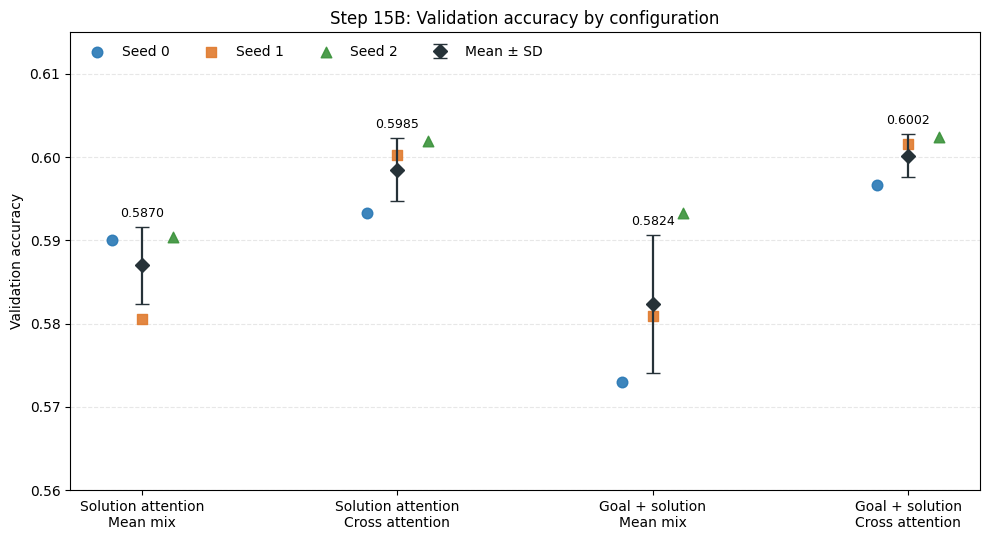

In [33]:
# @title Step 16: Chart from Step 15B.4 output

import re
import numpy as np
import matplotlib.pyplot as plt

# Snapshot copied from the currently saved Step 15B.4 Markdown output.
# If that output changes later, replace this text with the updated table.
STEP15B4_MARKDOWN_OUTPUT = r"""| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |
|:---|---:|---:|:---|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 77.2s | 0.759439 | [0: 0.809570, 1: 0.683504, 2: 0.785244] |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 96.9s | 0.745879 | [0: 0.783226, 1: 0.744422, 2: 0.709990] |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 85.1s | 0.784169 | [0: 0.756825, 1: 0.776702, 2: 0.818980] |
| GOAL + SOLUTION + CROSS ATTENTION | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 104.5s | 0.647675 | [0: 0.650757, 1: 0.616243, 2: 0.676024] |"""

_step16_rows = []
for _line in STEP15B4_MARKDOWN_OUTPUT.splitlines():
    _line = _line.strip()
    if not _line.startswith("|"):
        continue
    _columns = [part.strip() for part in _line.strip("|").split("|")]
    if not _columns or _columns[0].lower() == "configuration":
        continue
    if _columns[0].startswith(":---"):
        continue
    if len(_columns) < 4:
        raise ValueError(f"Unexpected Step 15B.4 table row: {_line}")

    _seed_pairs = re.findall(r"(\d+):\s*([0-9]+\.[0-9]+)", _columns[3])
    _seed_accuracies = {int(seed): float(value) for seed, value in _seed_pairs}
    if set(_seed_accuracies) != {0, 1, 2}:
        raise ValueError(
            f"Expected seed accuracies for seeds 0, 1, and 2; got {_seed_accuracies}"
        )
    _step16_rows.append({
        "configuration": _columns[0],
        "mean_accuracy": float(_columns[1]),
        "sd": float(_columns[2]),
        "seed_accuracies": _seed_accuracies,
    })

if len(_step16_rows) != 4:
    raise ValueError(
        f"Expected four Step 15B configurations, found {len(_step16_rows)}. "
        "Check the embedded Step 15B.4 output snapshot."
    )

_step16_labels = {
    "SOLUTION ATTENTION + MEAN MIX": "Solution attention\nMean mix",
    "SOLUTION ATTENTION + CROSS ATTENTION": "Solution attention\nCross attention",
    "GOAL + SOLUTION ATTENTION + MEAN MIX": "Goal + solution\nMean mix",
    "GOAL + SOLUTION + CROSS ATTENTION": "Goal + solution\nCross attention",
}
_step16_x = np.arange(len(_step16_rows), dtype=float)
_step16_means = [row["mean_accuracy"] for row in _step16_rows]
_step16_sds = [row["sd"] for row in _step16_rows]
_step16_seed_colors = {0: "#2878B5", 1: "#E07A2D", 2: "#3A923A"}
_step16_seed_markers = {0: "o", 1: "s", 2: "^"}
_step16_jitter = {0: -0.12, 1: 0.0, 2: 0.12}

fig, ax = plt.subplots(figsize=(10, 5.5))
for _seed in (0, 1, 2):
    ax.scatter(
        _step16_x + _step16_jitter[_seed],
        [row["seed_accuracies"][_seed] for row in _step16_rows],
        color=_step16_seed_colors[_seed],
        marker=_step16_seed_markers[_seed],
        s=58,
        alpha=0.9,
        label=f"Seed {_seed}",
        zorder=3,
    )
ax.errorbar(
    _step16_x,
    _step16_means,
    yerr=_step16_sds,
    fmt="D",
    color="#263238",
    ecolor="#263238",
    markersize=7,
    capsize=5,
    linewidth=1.6,
    label="Mean ± SD",
    zorder=4,
)
for _x, _mean, _sd in zip(_step16_x, _step16_means, _step16_sds):
    ax.annotate(
        f"{_mean:.4f}",
        (_x, _mean + _sd),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_xticks(_step16_x)
ax.set_xticklabels([
    _step16_labels.get(row["configuration"], row["configuration"])
    for row in _step16_rows
])
ax.set_ylabel("Validation accuracy")
ax.set_title("Step 15B: Validation accuracy by configuration")
ax.set_ylim(0.56, 0.615)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=4, frameon=False, loc="upper left")
fig.tight_layout()
plt.show()


## Step 17: Visualizing saved experiment outputs

These cells reproduce six figures and result summaries from **embedded snapshots of the saved Markdown outputs**
in Steps 13.5, 15B.4, 15C.4, 15D.4 and 15E.4. They require NumPy, pandas, Matplotlib and IPython,
which are available in Colab. They do not require training variables, checkpoints, data files or the notebook path.

Run **Step 17.1 first**, then any of Steps 17.2–17.8. To use newer results, replace the complete corresponding
strings in `STEP17_OUTPUT_SNAPSHOTS` and rerun these cells. The snapshots do not automatically update when an
upstream cell is rerun. All accuracy values refer to the validation split; n = 3 seeds per configuration.

Step 18 is an independent input interface for future **real** success/failure attention cases. It explains what
is missing from the saved aggregate outputs; it does not manufacture qualitative examples.


In [1]:
# @title Step 17.1: Output snapshots and experiment mapping
# Run this cell first. It is independent of every training cell and Step 16.
import re as step17_re
import numpy as step17_np
import pandas as step17_pd
import matplotlib.pyplot as step17_plt
from matplotlib.lines import Line2D as Step17Line2D
from IPython.display import Markdown as Step17Markdown, display as step17_display

# These are literal copies of SAVED cell outputs, not live notebook reads.
# After new experiments, replace the relevant table strings here and rerun
# Step 17.1–17.8. Update related tables together (including E's B comparison).
STEP17_OUTPUT_SNAPSHOTS = {
    '13.5': r"""| configuration | mean | sd | seeds | over floor |
|:---|---:|---:|:---|---:|
| NO ATTENTION | 0.6003 | 0.0032 | [0.6049, 0.5978, 0.5983] | 0.0745 |
| GOAL ATTENTION ONLY | 0.5919 | 0.0029 | [0.5954, 0.5883, 0.5921] | 0.0661 |
| SELF ATTENTION | 0.5901 | 0.0034 | [0.5854, 0.5916, 0.5933] | 0.0643 |
| CROSS ATTENTION ONLY (control) | 0.5999 | 0.0053 | [0.5954, 0.5970, 0.6074] | 0.0741 |
| CROSS + GOAL ATTENTION | 0.6042 | 0.0069 | [0.6061, 0.5950, 0.6115] | 0.0783 |""",
    '15B': r"""| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |
|:---|---:|---:|:---|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 77.2s | 0.759439 | [0: 0.809570, 1: 0.683504, 2: 0.785244] |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 96.9s | 0.745879 | [0: 0.783226, 1: 0.744422, 2: 0.709990] |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 85.1s | 0.784169 | [0: 0.756825, 1: 0.776702, 2: 0.818980] |
| GOAL + SOLUTION + CROSS ATTENTION | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 104.5s | 0.647675 | [0: 0.650757, 1: 0.616243, 2: 0.676024] |""",
    '15C': r"""### Step 15C.4: Accuracy and temperature comparison

| configuration | temperature mode | mean accuracy | sd | accuracy by seed | mean train time | mean T | mean λ | paired Δ vs unscaled (seed; mean, sd) |
|:---|:---|---:|---:|:---|---:|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 88.2s | 1.0000 | 0.759439 | baseline |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5938 | 0.0011 | [0: 0.5933, 1: 0.5954, 2: 0.5929] | 85.1s | 14.1421 | 0.858319 | [+0.0033, +0.0149, +0.0025]; mean=+0.0069, sd=0.0057 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5959 | 0.0025 | [0: 0.5983, 1: 0.5970, 2: 0.5925] | 87.2s | 12.4080 | 0.831258 | [+0.0083, +0.0165, +0.0021]; mean=+0.0090, sd=0.0059 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 106.4s | 1.0000 | 0.745879 | baseline |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 0.6021 | 0.0025 | [0: 0.5991, 1: 0.6053, 2: 0.6020] | 106.6s | 14.1421 | 0.813386 | [+0.0058, +0.0050, +0.0000]; mean=+0.0036, sd=0.0026 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 0.5998 | 0.0035 | [0: 0.6041, 1: 0.5954, 2: 0.5999] | 109.1s | 12.7237 | 0.780128 | [+0.0108, -0.0050, -0.0021]; mean=+0.0012, sd=0.0068 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 88.9s | 1.0000 | 0.784169 | baseline |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5870 | 0.0111 | [0: 0.6024, 1: 0.5817, 2: 0.5767] | 88.7s | 14.1421 | 0.866758 | [+0.0294, +0.0008, -0.0165]; mean=+0.0046, sd=0.0189 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5933 | 0.0019 | [0: 0.5954, 1: 0.5908, 2: 0.5937] | 91.2s | 12.2415 | 0.828430 | [+0.0223, +0.0099, +0.0004]; mean=+0.0109, sd=0.0090 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 111.2s | 1.0000 | 0.647675 | baseline |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 0.6018 | 0.0022 | [0: 0.6020, 1: 0.5991, 2: 0.6045] | 110.6s | 14.1421 | 0.828889 | [+0.0054, -0.0025, +0.0021]; mean=+0.0017, sd=0.0032 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 0.5985 | 0.0039 | [0: 0.5954, 1: 0.5962, 2: 0.6041] | 113.1s | 12.5375 | 0.794329 | [-0.0012, -0.0054, +0.0017]; mean=-0.0017, sd=0.0029 |""",
    '15C_diagnostics': r"""### Attention diagnostics

| configuration | temperature mode | sol1 entropy | sol1 norm. entropy | sol1 max α | sol2 entropy | sol2 norm. entropy | sol2 max α | overall entropy | overall norm. entropy | overall max α |
|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5698 | 0.6095 | 0.4853 | 1.5681 | 0.6081 | 0.4859 | 1.5689 | 0.6088 | 0.4856 |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5200 | 0.9739 | 0.1588 | 2.5186 | 0.9738 | 0.1590 | 2.5193 | 0.9739 | 0.1589 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5203 | 0.9742 | 0.1593 | 2.5179 | 0.9736 | 0.1597 | 2.5191 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 1.4800 | 0.5713 | 0.5153 | 1.4810 | 0.5718 | 0.5140 | 1.4805 | 0.5716 | 0.5146 |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 2.5482 | 0.9832 | 0.1460 | 2.5470 | 0.9833 | 0.1459 | 2.5476 | 0.9833 | 0.1459 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 2.5456 | 0.9826 | 0.1452 | 2.5442 | 0.9827 | 0.1451 | 2.5449 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5959 | 0.6193 | 0.4787 | 1.6006 | 0.6210 | 0.4752 | 1.5982 | 0.6201 | 0.4769 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5163 | 0.9728 | 0.1610 | 2.5150 | 0.9728 | 0.1612 | 2.5157 | 0.9728 | 0.1611 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5047 | 0.9678 | 0.1668 | 2.5024 | 0.9673 | 0.1675 | 2.5036 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 1.7567 | 0.6761 | 0.4331 | 1.7559 | 0.6771 | 0.4325 | 1.7563 | 0.6766 | 0.4328 |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 2.5470 | 0.9824 | 0.1465 | 2.5456 | 0.9824 | 0.1462 | 2.5463 | 0.9824 | 0.1463 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 2.5361 | 0.9786 | 0.1514 | 2.5347 | 0.9787 | 0.1514 | 2.5354 | 0.9787 | 0.1514 |""",
    '15D': r"""| configuration | mean | sd | seeds | train time | T | λ | H_norm | max α |
|:---|---:|---:|:---|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | 0.5959 | 0.0025 | [0.5983, 0.5970, 0.5925] | 89.1s | 12.4080 | 0.8313 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5998 | 0.0035 | [0.6041, 0.5954, 0.5999] | 111.0s | 12.7237 | 0.7801 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5933 | 0.0019 | [0.5954, 0.5908, 0.5937] | 91.8s | 12.2415 | 0.8284 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | 0.5985 | 0.0039 | [0.5954, 0.5962, 0.6041] | 115.0s | 12.5375 | 0.7943 | 0.9787 | 0.1514 |""",
    '15E': r"""| configuration | Step 15E mean | sd | seed accuracies | Step 15B mean | delta vs 15B |
|:---|---:|---:|:---|---:|---:|
| goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention | 0.5963 | 0.0034 | [0.6012, 0.5941, 0.5937] | 0.5870 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention | 0.5999 | 0.0030 | [0.5987, 0.5970, 0.6041] | 0.5985 | +0.0014 |
| goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature_full_goal_attention | 0.5918 | 0.0054 | [0.5987, 0.5912, 0.5854] | 0.5824 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention | 0.6042 | 0.0032 | [0.6012, 0.6086, 0.6028] | 0.6002 | +0.0040 |""",
}


STEP17_SWITCHES = {
    '00': {'a2': False, 'a3': False, 'label': 'A2 off / A3 off', 'color': '#0072B2'},
    '01': {'a2': False, 'a3': True,  'label': 'A2 off / A3 on',  'color': '#D55E00'},
    '10': {'a2': True,  'a3': False, 'label': 'A2 on / A3 off',  'color': '#009E73'},
    '11': {'a2': True,  'a3': True,  'label': 'A2 on / A3 on',   'color': '#AA4499'},
}
STEP17_BASE_NAMES = {
    '00': 'goal_guided_solution_attention_mean_mix',
    '01': 'goal_guided_solution_attention_mean_mix_with_cross_attention',
    '10': 'goal_guided_solution_attention_mean_mix_with_goal_attention',
    '11': 'goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention',
}
STEP17_DISPLAY_NAMES = {
    'SOLUTION ATTENTION + MEAN MIX': '00',
    'SOLUTION ATTENTION + CROSS ATTENTION': '01',
    'GOAL + SOLUTION ATTENTION + MEAN MIX': '10',
    'GOAL + SOLUTION + CROSS ATTENTION': '11',
}
STEP17_E_NAMES = {
    name + '_learned_temperature_full_goal_attention': switch
    for switch, name in STEP17_BASE_NAMES.items()
}
STEP17_BASELINES = {
    'NO ATTENTION': ('no_attention', 'none', '00', 'No attention'),
    'GOAL ATTENTION ONLY': ('goal_attention_only', 'none', '10', 'Goal attention only'),
    'SELF ATTENTION': ('self_attention', 'self', '00', 'Self attention'),
    'CROSS ATTENTION ONLY (control)': ('cross_attention_only', 'none', '01', 'Cross attention only'),
    'CROSS + GOAL ATTENTION': ('cross_attention_plus_goal', 'none', '11', 'Cross + goal attention'),
}
STEP17_MODES = ('unscaled', 'fixed_sqrt_d', 'learned_temperature')
STEP17_MODE_LABELS = ('Unscaled', 'Fixed √d', 'Learned T')
STEP17_ROUNDING_ATOL = 1.000001e-4  # Both seed values and summaries are rounded.
STEP17_SEED_MARKERS = {0: 'o', 1: 's', 2: '^'}
STEP17_STYLE = {
    'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 10,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlepad': 12, 'savefig.facecolor': 'white',
}


def step17_parse_table(text, source):
    """Parse one complete Markdown table; never silently skip malformed rows."""
    lines = [line.strip() for line in text.splitlines() if line.strip().startswith('|')]
    if len(lines) < 3:
        raise ValueError(f'{source}: expected a Markdown header, separator and data rows.')
    cells = [[part.strip() for part in line.strip('|').split('|')] for line in lines]
    header = cells[0]
    if len(set(header)) != len(header) or header[0] != 'configuration':
        raise ValueError(f'{source}: invalid or duplicate column names: {header}')
    if len(cells[1]) != len(header) or not all(step17_re.fullmatch(r':?-{3,}:?', v) for v in cells[1]):
        raise ValueError(f'{source}: invalid Markdown separator row.')
    rows = []
    for i, values in enumerate(cells[2:], 1):
        if len(values) != len(header) or any(v == '' for v in values):
            raise ValueError(f'{source}, row {i}: missing values or wrong number of columns.')
        rows.append(dict(zip(header, values)))
    return rows


def step17_number(text, context, low=None, high=None):
    try:
        value = float(text)
    except (ValueError, TypeError) as error:
        raise ValueError(f'{context}: expected a finite number, got {text!r}.') from error
    if not step17_np.isfinite(value) or (low is not None and value < low) or (high is not None and value > high):
        raise ValueError(f'{context}: value {text!r} is outside the allowed range.')
    return value


def step17_parse_seeds(text, context):
    """Unlabelled lists follow the source cells' sorted seed order: 0, 1, 2."""
    if not (text.startswith('[') and text.endswith(']')):
        raise ValueError(f'{context}: expected a bracketed seed list.')
    parts = [part.strip() for part in text[1:-1].split(',')]
    if len(parts) != 3:
        raise ValueError(f'{context}: expected exactly three seeds (0, 1, 2).')
    labelled = any(':' in part for part in parts)
    values = {}
    for index, part in enumerate(parts):
        if labelled:
            match = step17_re.fullmatch(r'(\d+)\s*:\s*(.+)', part)
            if not match:
                raise ValueError(f'{context}: malformed labelled seed: {part!r}.')
            seed, value = int(match[1]), match[2]
        else:
            seed, value = index, part
        if seed in values:
            raise ValueError(f'{context}: duplicate seed {seed}.')
        values[seed] = step17_number(value, f'{context}, seed {seed}', 0, 1)
    if set(values) != {0, 1, 2}:
        raise ValueError(f'{context}: seed identities must be 0, 1, 2.')
    return {seed: values[seed] for seed in (0, 1, 2)}


def step17_load_snapshots(snapshots):
    """Return summary, seed, C-diagnostic and overlap tables using only strings."""
    required = {'13.5', '15B', '15C', '15C_diagnostics', '15D', '15E'}
    if set(snapshots) != required:
        raise ValueError(f'Snapshot keys must be exactly {sorted(required)}; got {sorted(snapshots)}.')
    # Explicit source schemas prevent accidentally parsing a different metric.
    schemas = {
        '13.5': ('mean', 'seeds', 5),
        '15B': ('mean accuracy', 'seed accuracies', 4),
        '15C': ('mean accuracy', 'accuracy by seed', 12),
        '15D': ('mean', 'seeds', 4),
        '15E': ('Step 15E mean', 'seed accuracies', 4),
    }
    metrics = {
        'mean train time': 'training_seconds', 'train time': 'training_seconds',
        'mean T': 'mean_temperature', 'T': 'mean_temperature',
        'mean λ': 'mean_lambda', 'λ': 'mean_lambda',
        'H_norm': 'normalized_entropy', 'max α': 'maximum_attention_weight',
        'Step 15B mean': 'reported_15b_mean', 'delta vs 15B': 'reported_delta_vs_15b',
    }
    summary_rows, seed_rows = [], []
    for stage, (mean_col, seed_col, count) in schemas.items():
        parsed = step17_parse_table(snapshots[stage], stage)
        if len(parsed) != count:
            raise ValueError(f'{stage}: expected {count} configurations, found {len(parsed)}.')
        needed = {'configuration', mean_col, 'sd', seed_col}
        if stage == '15C':
            needed |= {'temperature mode', 'mean T', 'mean λ'}
        if stage == '15E':
            needed |= {'Step 15B mean', 'delta vs 15B'}
        for row in parsed:
            if not needed.issubset(row):
                raise ValueError(f'{stage}: missing columns {sorted(needed - row.keys())}.')
            name = row['configuration']
            if stage == '13.5':
                if name not in STEP17_BASELINES:
                    raise ValueError(f'{stage}: unknown configuration {name!r}.')
                config, a1, switch, short = STEP17_BASELINES[name]
                mode = 'not_applicable'
            else:
                aliases = STEP17_E_NAMES if stage == '15E' else STEP17_DISPLAY_NAMES
                if name not in aliases:
                    raise ValueError(f'{stage}: unknown configuration {name!r}.')
                switch = aliases[name]
                config, a1, short = STEP17_BASE_NAMES[switch], 'goal', STEP17_SWITCHES[switch]['label']
                mode = row['temperature mode'] if stage == '15C' else ('unscaled' if stage == '15B' else 'learned_temperature')
                if mode not in STEP17_MODES:
                    raise ValueError(f'{stage}: unknown temperature mode {mode!r}.')
            identity = f'{stage}:{config}:{mode}'
            values = step17_parse_seeds(row[seed_col], identity)
            mean = step17_number(row[mean_col], identity + ' mean', 0, 1)
            sd = step17_number(row['sd'], identity + ' SD', 0, 1)
            rounded_values = list(values.values())
            if abs(mean - step17_np.mean(rounded_values)) > STEP17_ROUNDING_ATOL or abs(sd - step17_np.std(rounded_values, ddof=0)) > STEP17_ROUNDING_ATOL:
                raise ValueError(f'{identity}: mean/SD disagree with the displayed seeds beyond rounding tolerance.')
            record = dict(record_id=identity, stage=stage, source_cell=f'Step {stage}.4' if stage != '13.5' else 'Step 13.5',
                          source_configuration=name, configuration=config, short_label=short,
                          switch_id=switch, a1=a1, a2=STEP17_SWITCHES[switch]['a2'], a3=STEP17_SWITCHES[switch]['a3'],
                          mean_mix=stage != '13.5', temperature_mode=mode, full_goal_residual=stage == '15E',
                          mean_accuracy=mean, sd=sd, seed_accuracies=values,
                          reported_paired_delta=row.get('paired Δ vs unscaled (seed; mean, sd)'))
            record.update({metric: step17_np.nan for metric in set(metrics.values())})
            for source, metric in metrics.items():
                if source in row:
                    value = row[source].removesuffix('s') if metric == 'training_seconds' else row[source]
                    low = None if metric == 'reported_delta_vs_15b' else 0
                    high = 1 if metric in {'mean_lambda', 'normalized_entropy', 'maximum_attention_weight', 'reported_15b_mean'} else None
                    record[metric] = step17_number(value, f'{identity}, {source}', low, high)
            if stage == '15C' and record['mean_temperature'] <= 0:
                raise ValueError(f'{identity}: temperature must be positive.')
            summary_rows.append(record)
            seed_rows.extend(dict(record_id=identity, stage=stage, configuration=config, switch_id=switch,
                                  temperature_mode=mode, seed=seed, accuracy=accuracy)
                             for seed, accuracy in values.items())
    summary = step17_pd.DataFrame(summary_rows)
    if summary.record_id.duplicated().any():
        raise ValueError('Duplicate configuration/temperature rows in the output snapshots.')
    for stage in ('15B', '15C', '15D', '15E'):
        subset = summary[summary.stage == stage]
        modes = STEP17_MODES if stage == '15C' else (('unscaled',) if stage == '15B' else ('learned_temperature',))
        expected = {(switch, mode) for switch in STEP17_SWITCHES for mode in modes}
        if set(zip(subset.switch_id, subset.temperature_mode)) != expected:
            raise ValueError(f'{stage}: incomplete A2/A3 × temperature matrix.')

    diagnostic_rows = []
    diagnostic_fields = {
        f'{part} {metric}': f'{part}_{field}'
        for part in ('sol1', 'sol2', 'overall')
        for metric, field in [('entropy', 'entropy'), ('norm. entropy', 'normalized_entropy'), ('max α', 'maximum_attention_weight')]
    }
    for row in step17_parse_table(snapshots['15C_diagnostics'], '15C diagnostics'):
        needed = {'configuration', 'temperature mode'} | set(diagnostic_fields)
        if not needed.issubset(row):
            raise ValueError(f'15C diagnostics: missing columns {sorted(needed - row.keys())}.')
        if row['configuration'] not in STEP17_DISPLAY_NAMES or row['temperature mode'] not in STEP17_MODES:
            raise ValueError('15C diagnostics: unknown configuration or temperature mode.')
        item = dict(switch_id=STEP17_DISPLAY_NAMES[row['configuration']], temperature_mode=row['temperature mode'])
        for source, field in diagnostic_fields.items():
            high = 1 if ('normalized' in field or 'weight' in field) else None
            item[field] = step17_number(row[source], f'15C diagnostics: {source}', 0, high)
        diagnostic_rows.append(item)
    diagnostics = step17_pd.DataFrame(diagnostic_rows)
    if len(diagnostics) != 12 or diagnostics.duplicated(['switch_id', 'temperature_mode']).any():
        raise ValueError('15C diagnostics: expected twelve unique configuration–temperature rows.')
    keys = ['switch_id', 'temperature_mode']
    c_rows = summary[summary.stage == '15C']
    if set(map(tuple, diagnostics[keys].to_numpy())) != set(map(tuple, c_rows[keys].to_numpy())):
        raise ValueError('15C accuracy and diagnostic configurations do not match.')
    diagnostics = c_rows[['record_id', *keys, 'mean_temperature', 'mean_lambda', 'mean_accuracy']].merge(diagnostics, on=keys, validate='one_to_one')
    for index, row in summary[summary.stage == '15E'].iterrows():
        baseline = summary[(summary.stage == '15B') & (summary.switch_id == row.switch_id)].iloc[0]
        if abs(row.reported_15b_mean - baseline.mean_accuracy) > STEP17_ROUNDING_ATOL or abs(row.reported_delta_vs_15b - (row.mean_accuracy - baseline.mean_accuracy)) > STEP17_ROUNDING_ATOL:
            raise ValueError(f'15E {row.switch_id}: the reported B comparison is inconsistent; update related snapshots together.')

    # Identical displayed outcomes are provenance overlap, not extra replication.
    summary['display_equivalence_id'] = summary.record_id
    overlaps = []
    for mode, other_stage in [('unscaled', '15B'), ('learned_temperature', '15D')]:
        for switch in STEP17_SWITCHES:
            c = summary[(summary.stage == '15C') & (summary.switch_id == switch) & (summary.temperature_mode == mode)].iloc[0]
            other = summary[(summary.stage == other_stage) & (summary.switch_id == switch)].iloc[0]
            same = c.seed_accuracies == other.seed_accuracies and c.mean_accuracy == other.mean_accuracy and c.sd == other.sd
            overlaps.append(dict(switch_id=switch, c_mode=mode, counterpart=other_stage, same_displayed_accuracy=same))
            if same:
                summary.loc[summary.record_id == c.record_id, 'display_equivalence_id'] = other.record_id
    seeds = step17_pd.DataFrame(seed_rows).merge(summary[['record_id', 'display_equivalence_id']], on='record_id', validate='many_to_one')
    return summary, seeds, diagnostics, step17_pd.DataFrame(overlaps)


def step17_paired_deltas(seeds, later, earlier):
    """Pair by switch AND seed. This comparison uses only B, D or E."""
    if later not in {'15B', '15D', '15E'} or earlier not in {'15B', '15D', '15E'}:
        raise ValueError('Stage comparisons require one row per switch/seed: 15B, 15D or 15E.')
    columns = ['switch_id', 'seed', 'accuracy']
    left = seeds[seeds.stage == later][columns]
    right = seeds[seeds.stage == earlier][columns]
    if len(left) != 12 or len(right) != 12:
        raise ValueError('Paired comparisons require all four configurations and three seeds per stage.')
    paired = left.merge(right, on=['switch_id', 'seed'], how='outer', suffixes=('_later', '_earlier'), validate='one_to_one', indicator=True)
    if not paired['_merge'].eq('both').all():
        raise ValueError('Cannot pair these snapshots: configuration/seed identities do not match.')
    paired['delta_pp'] = 100 * (paired.accuracy_later - paired.accuracy_earlier)
    return paired.sort_values(['switch_id', 'seed']).reset_index(drop=True)


def step17_table(headers, rows, right=()):
    def clean(value):
        return str(value).replace('|', r'\|').replace('\n', ' ')
    lines = ['| ' + ' | '.join(headers) + ' |',
             '|' + '|'.join('---:' if i in right else ':---' for i in range(len(headers))) + '|']
    lines += ['| ' + ' | '.join(clean(v) for v in row) + ' |' for row in rows]
    step17_display(Step17Markdown('\n'.join(lines)))


def step17_get_row(stage, switch, mode=None):
    rows = step17_summary[(step17_summary.stage == stage) & (step17_summary.switch_id == switch)]
    if stage == '13.5':
        rows = rows[rows.a1 == 'none']
    if mode is not None:
        rows = rows[rows.temperature_mode == mode]
    if len(rows) != 1:
        raise ValueError(f'Expected one row for {stage}/{switch}/{mode}; found {len(rows)}.')
    return rows.iloc[0]


def step17_accuracy_limits(rows):
    values = []
    for _, row in rows.iterrows():
        values.extend([row.mean_accuracy - row.sd, row.mean_accuracy + row.sd, *row.seed_accuracies.values()])
    low, high = 100 * min(values), 100 * max(values)
    padding = max(.30, (high - low) * .12)
    return max(0, low - padding), min(100, high + padding)


def step17_seed_legend():
    return [Step17Line2D([], [], marker=marker, linestyle='none', color='#68737D', markersize=6, label=f'Seed {seed}')
            for seed, marker in STEP17_SEED_MARKERS.items()] + [
                Step17Line2D([], [], marker='D', color='#1F2933', markersize=6, label='Mean ± population SD')]


def step17_plot_accuracy(ax, rows, labels, color):
    for x, row in enumerate(rows):
        for seed, marker in STEP17_SEED_MARKERS.items():
            ax.scatter(x + (seed - 1) * .13, row.seed_accuracies[seed] * 100,
                       color=color, marker=marker, s=42, alpha=.65, zorder=3)
        ax.errorbar(x, row.mean_accuracy * 100, yerr=row.sd * 100, fmt='D', color='#1F2933',
                    capsize=5, markersize=6, linewidth=1.5, zorder=4)
        ax.annotate(f'{row.mean_accuracy * 100:.2f}%', (x, max(row.mean_accuracy + row.sd, max(row.seed_accuracies.values())) * 100),
                    xytext=(0, 7), textcoords='offset points', ha='center', fontsize=10)
    ax.set_xticks(range(len(rows)), labels)
    ax.set_xlim(-.5, len(rows) - .5)
    ax.set_ylabel('Validation accuracy (%)')
    ax.grid(axis='y', color='#DCE1E5', linestyle='--', alpha=.8)
    ax.set_axisbelow(True)


def step17_show_figure(key, figure, caption):
    step17_figures[key] = figure
    step17_display(figure)
    step17_plt.close(figure)  # Avoid a duplicate automatic inline rendering.
    step17_display(Step17Markdown(caption))


step17_summary, step17_seeds, step17_diagnostics, step17_overlaps = step17_load_snapshots(STEP17_OUTPUT_SNAPSHOTS)
step17_figures = {}
step17_display(Step17Markdown('''### Experiment mapping and snapshot provenance
**Run order:** Step 17.1, then any of Steps 17.2–17.8. Step 18 is independent.
All numbers below are parsed from the embedded saved outputs; no training state or file path is used.

A1 = solution attention (none, shared-query self attention, or goal-guided attention).
A2 = goal-token attention. A3 = solution-to-solution cross attention with masked mean + max pooling.
Mean mix combines λ × attention context with (1 − λ) × mean context.
Temperature divides A1 scores only. Step E's full-goal residual is a separate solution-to-goal branch;
it is present even when A2 is off.
'''))
step17_table(['Stage', 'A1', 'A2/A3 coverage', 'Mean mix', 'Temperature', 'Full-goal residual'], [
    ['13.5', 'none or self', 'Five explicit baseline variants', 'off', 'N/A', 'off'],
    ['15B', 'goal-guided', '00, 01, 10, 11', 'learned λ', 'unscaled', 'off'],
    ['15C', 'goal-guided', '00, 01, 10, 11 × all three modes', 'learned λ', 'unscaled / fixed √d / learned', 'off'],
    ['15D', 'goal-guided', '00, 01, 10, 11', 'learned λ', 'learned', 'off'],
    ['15E', 'goal-guided', '00, 01, 10, 11', 'learned λ', 'learned', 'on'],
])
step17_table(['Step 13.5 configuration', 'A1', 'A2', 'A3'], [
    [row.short_label, row.a1, 'on' if row.a2 else 'off', 'on' if row.a3 else 'off']
    for row in step17_summary[step17_summary.stage == '13.5'].itertuples()
])
step17_table(['Short label', 'Step 15B base configuration'], [
    [spec['label'], STEP17_BASE_NAMES[switch]] for switch, spec in STEP17_SWITCHES.items()
])
step17_table(['Saved output', 'Summary rows', 'Displayed seed records'], [
    [stage, int((step17_summary.stage == stage).sum()), int((step17_seeds.stage == stage).sum())]
    for stage in ('13.5', '15B', '15C', '15D', '15E')
], right=(1, 2))
step17_table(['C temperature mode', 'Design counterpart', 'Matching displayed results'], [
    [mode, stage, f"{int(step17_overlaps[step17_overlaps.c_mode == mode].same_displayed_accuracy.sum())}/4 configurations"]
    for mode, stage in [('unscaled', '15B'), ('learned_temperature', '15D')]
])
step17_display(Step17Markdown(
    f'**Loaded:** {len(step17_summary)} summary rows, {len(step17_seeds)} seed records and '
    f'{len(step17_diagnostics)} C diagnostic rows. Identical displayed outcomes across stages are '
    'marked with a shared `display_equivalence_id`; they are never pooled as extra replication. '
    'Matching outputs do not establish that two cells used the same training execution. '
    '**All accuracy results are validation results, with n = 3 seeds per configuration.** '
    'SD means population SD (ddof = 0), not a confidence interval. '
    'Keep related snapshots synchronized when replacing them after new experiments.'
))


### Experiment mapping and snapshot provenance
**Run order:** Step 17.1, then any of Steps 17.2–17.8. Step 18 is independent.
All numbers below are parsed from the embedded saved outputs; no training state or file path is used.

A1 = solution attention (none, shared-query self attention, or goal-guided attention).
A2 = goal-token attention. A3 = solution-to-solution cross attention with masked mean + max pooling.
Mean mix combines λ × attention context with (1 − λ) × mean context.
Temperature divides A1 scores only. Step E's full-goal residual is a separate solution-to-goal branch;
it is present even when A2 is off.


| Stage | A1 | A2/A3 coverage | Mean mix | Temperature | Full-goal residual |
|:---|:---|:---|:---|:---|:---|
| 13.5 | none or self | Five explicit baseline variants | off | N/A | off |
| 15B | goal-guided | 00, 01, 10, 11 | learned λ | unscaled | off |
| 15C | goal-guided | 00, 01, 10, 11 × all three modes | learned λ | unscaled / fixed √d / learned | off |
| 15D | goal-guided | 00, 01, 10, 11 | learned λ | learned | off |
| 15E | goal-guided | 00, 01, 10, 11 | learned λ | learned | on |

| Step 13.5 configuration | A1 | A2 | A3 |
|:---|:---|:---|:---|
| No attention | none | off | off |
| Goal attention only | none | on | off |
| Self attention | self | off | off |
| Cross attention only | none | off | on |
| Cross + goal attention | none | on | on |

| Short label | Step 15B base configuration |
|:---|:---|
| A2 off / A3 off | goal_guided_solution_attention_mean_mix |
| A2 off / A3 on | goal_guided_solution_attention_mean_mix_with_cross_attention |
| A2 on / A3 off | goal_guided_solution_attention_mean_mix_with_goal_attention |
| A2 on / A3 on | goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention |

| Saved output | Summary rows | Displayed seed records |
|:---|---:|---:|
| 13.5 | 5 | 15 |
| 15B | 4 | 12 |
| 15C | 12 | 36 |
| 15D | 4 | 12 |
| 15E | 4 | 12 |

| C temperature mode | Design counterpart | Matching displayed results |
|:---|:---|:---|
| unscaled | 15B | 4/4 configurations |
| learned_temperature | 15D | 4/4 configurations |

**Loaded:** 29 summary rows, 87 seed records and 12 C diagnostic rows. Identical displayed outcomes across stages are marked with a shared `display_equivalence_id`; they are never pooled as extra replication. Matching outputs do not establish that two cells used the same training execution. **All accuracy results are validation results, with n = 3 seeds per configuration.** SD means population SD (ddof = 0), not a confidence interval. Keep related snapshots synchronized when replacing them after new experiments.

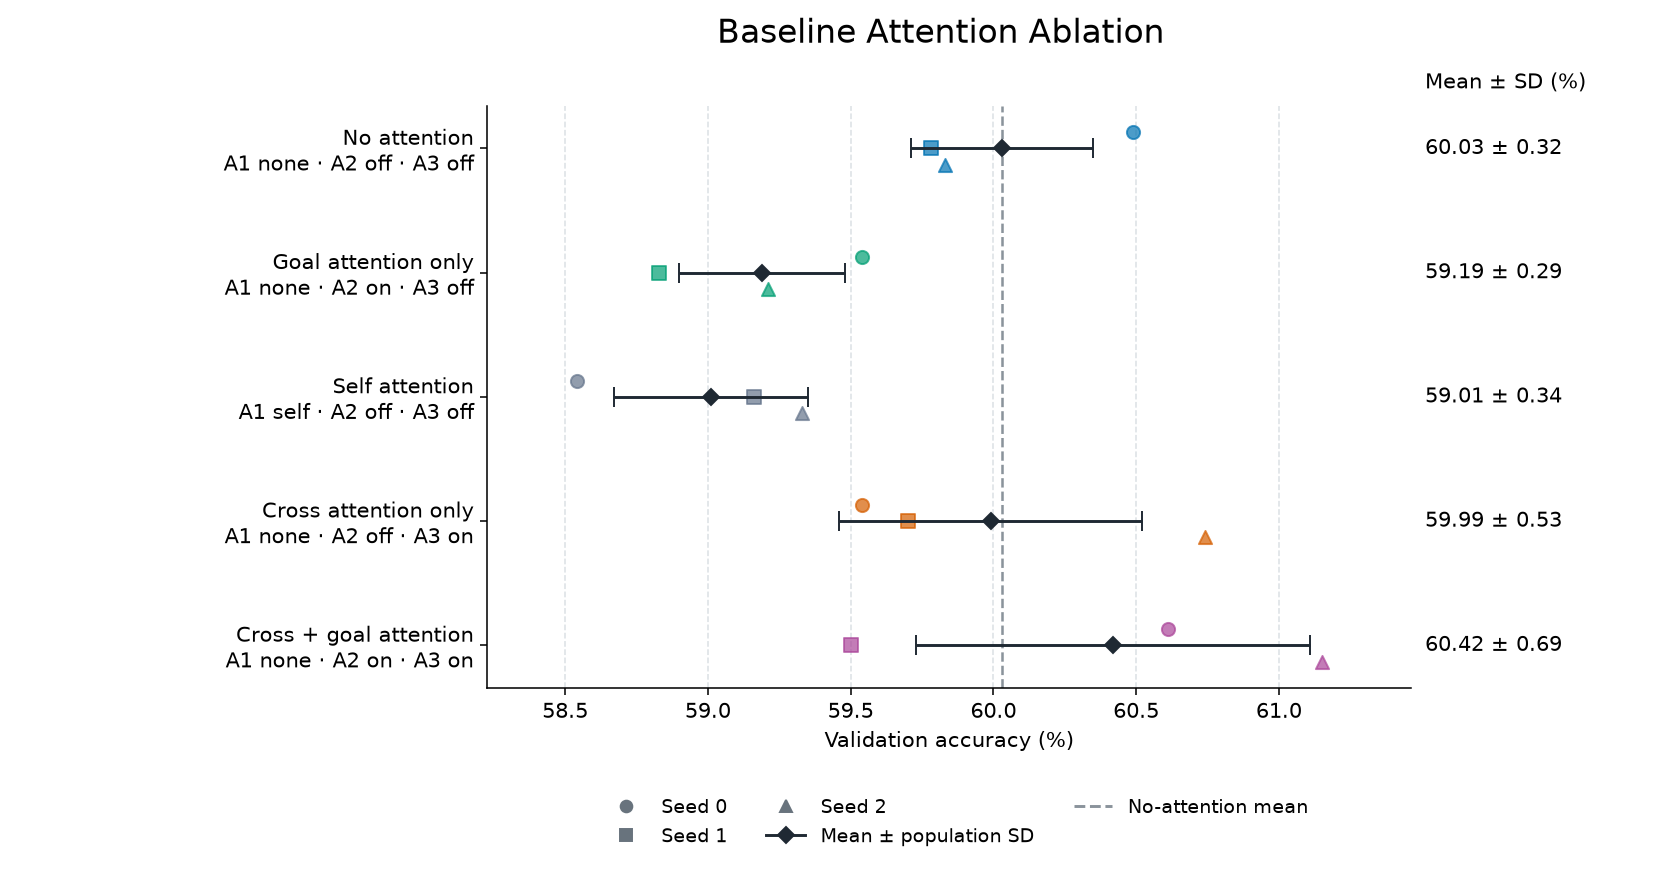

**Figure 1 — Step 13.5.** Diamonds and horizontal error bars show the reported mean ± population SD; small markers show seeds 0, 1 and 2. All cross-attention variants use masked mean + max residual pooling. Self attention here uses a shared learned pooling query, rather than token-to-token Transformer attention.

In [2]:
# @title Step 17.2: Baseline Attention Ablation
with step17_plt.rc_context(STEP17_STYLE):
    step17_baseline_rows = step17_summary[step17_summary.stage == '13.5']
    step17_fig, step17_ax = step17_plt.subplots(figsize=(12, 6.3))
    step17_reference = step17_get_row('13.5', '00').mean_accuracy * 100
    step17_ax.axvline(step17_reference, color='#8A939B', linestyle='--', linewidth=1.3,
                      label=f'No-attention mean: {step17_reference:.2f}%')
    step17_tick_labels = []
    for step17_y, step17_row in enumerate(step17_baseline_rows.itertuples()):
        step17_color = '#64748B' if step17_row.a1 == 'self' else STEP17_SWITCHES[step17_row.switch_id]['color']
        for step17_seed, step17_marker in STEP17_SEED_MARKERS.items():
            step17_ax.scatter(step17_row.seed_accuracies[step17_seed] * 100,
                              step17_y + (step17_seed - 1) * .13, s=46,
                              color=step17_color, marker=step17_marker, alpha=.7, zorder=3)
        step17_ax.errorbar(step17_row.mean_accuracy * 100, step17_y, xerr=step17_row.sd * 100,
                          fmt='D', color='#1F2933', capsize=5, markersize=6, zorder=4)
        step17_ax.text(1.015, step17_y, f'{step17_row.mean_accuracy * 100:.2f} ± {step17_row.sd * 100:.2f}',
                       transform=step17_ax.get_yaxis_transform(), va='center', fontsize=11)
        step17_tick_labels.append(f'{step17_row.short_label}\nA1 {step17_row.a1} · A2 {"on" if step17_row.a2 else "off"} · A3 {"on" if step17_row.a3 else "off"}')
    step17_ax.set_yticks(range(5), step17_tick_labels)
    step17_ax.invert_yaxis()
    step17_ax.set_xlim(*step17_accuracy_limits(step17_baseline_rows))
    step17_ax.set_xlabel('Validation accuracy (%)')
    step17_ax.grid(axis='x', color='#DCE1E5', linestyle='--')
    step17_ax.set_axisbelow(True)
    step17_ax.text(1.015, 1.03, 'Mean ± SD (%)', transform=step17_ax.transAxes, fontsize=11)
    step17_fig.suptitle('Baseline Attention Ablation', fontsize=17, x=.56)
    step17_fig.legend(handles=step17_seed_legend() + [Step17Line2D([], [], color='#8A939B', linestyle='--', label='No-attention mean')],
                      loc='lower center', bbox_to_anchor=(.57, .02), ncol=3, frameon=False)
    step17_fig.subplots_adjust(left=.29, right=.84, bottom=.22, top=.88)
    step17_show_figure('baseline', step17_fig,
        '**Figure 1 — Step 13.5.** Diamonds and horizontal error bars show the reported mean ± population SD; '
        'small markers show seeds 0, 1 and 2. All cross-attention variants use masked mean + max residual pooling. '
        'Self attention here uses a shared learned pooling query, rather than token-to-token Transformer attention.')


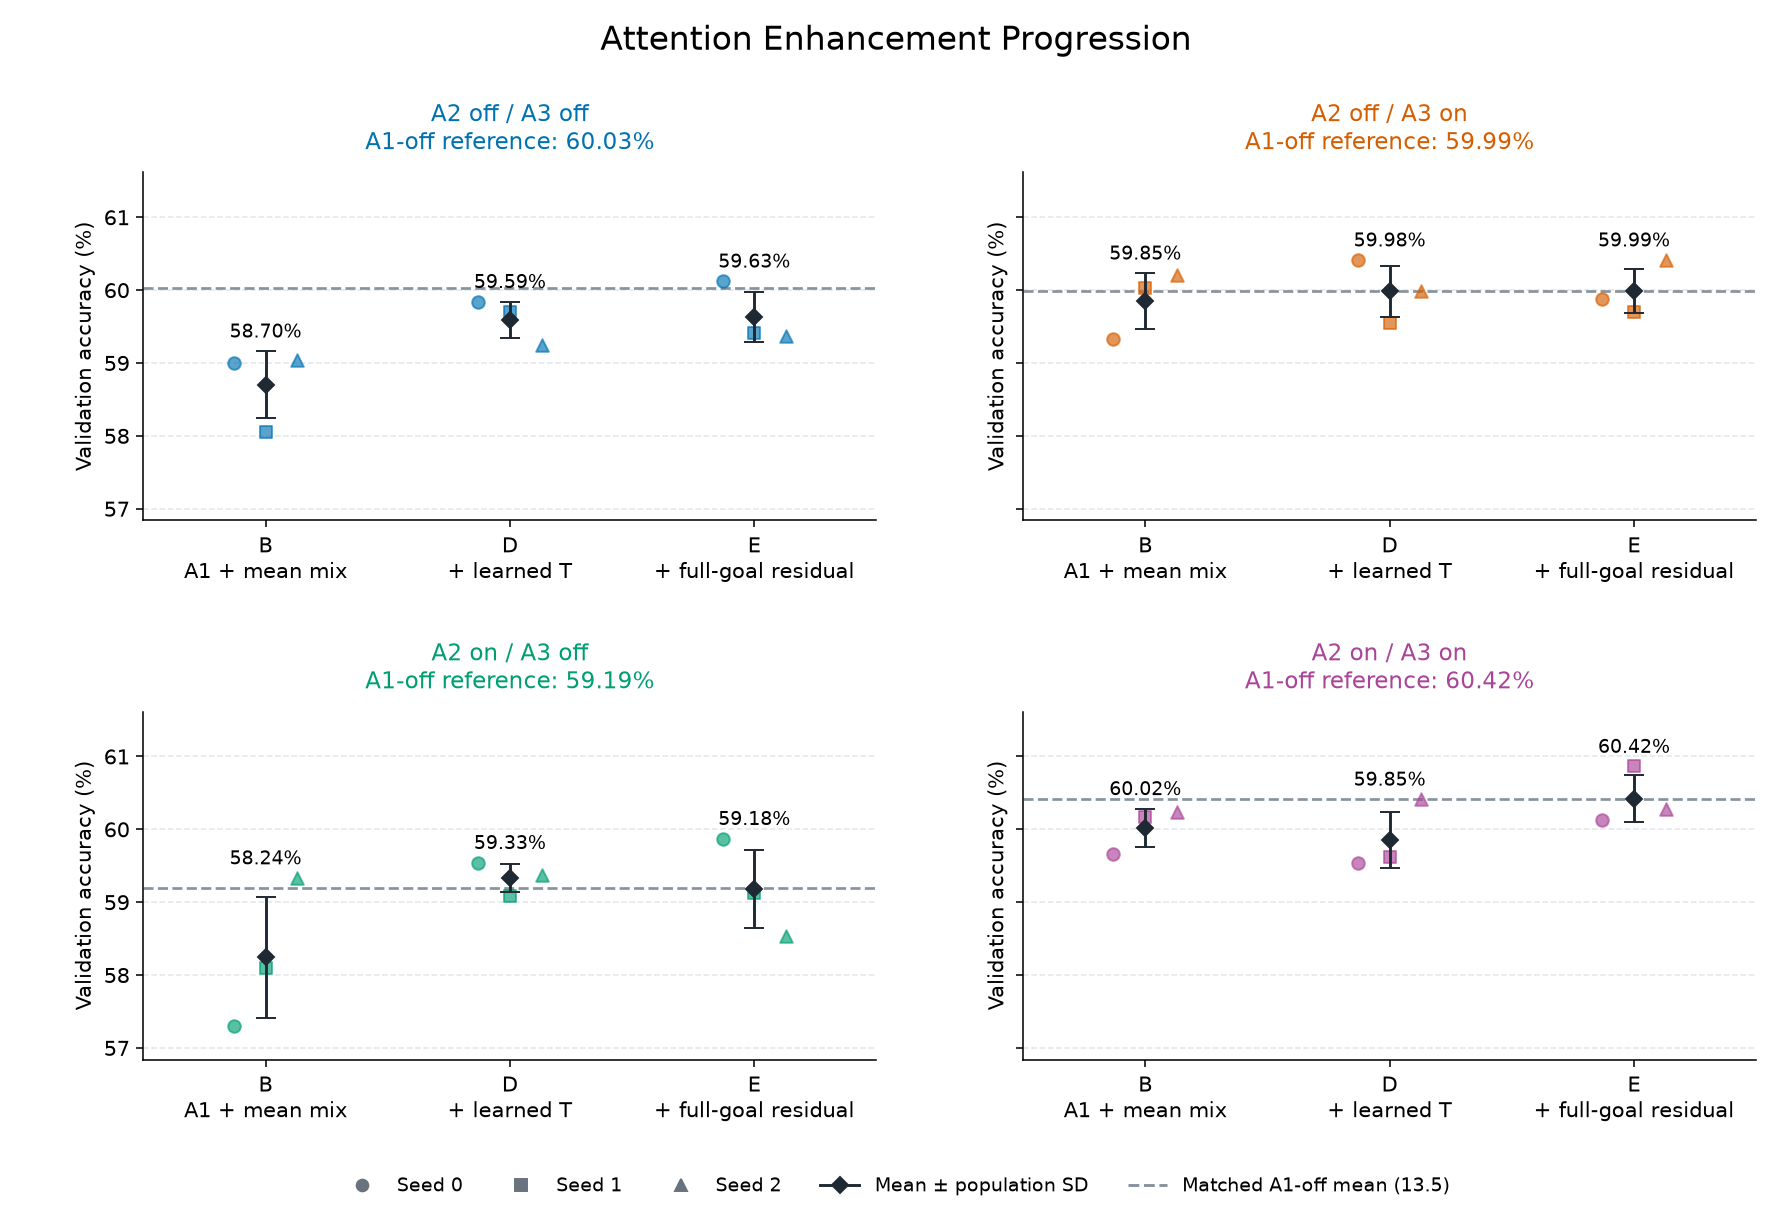

**Figure 2 — Steps 15B, 15D and 15E.** Each panel fixes A2/A3. The dashed line is the Step 13.5 mean with those switches and A1 off. B introduces goal-guided A1 and mean mixing together, so this baseline comparison does not isolate either component. D adds learned temperature; E adds a separate full-goal residual. Identical C counterparts are omitted from this progression to avoid duplicate evidence.

In [3]:
# @title Step 17.3: Attention Enhancement Progression
with step17_plt.rc_context(STEP17_STYLE):
    step17_fig, step17_axes = step17_plt.subplots(2, 2, figsize=(12.8, 8.8), sharey=True)
    step17_progression_data = step17_summary[step17_summary.stage.isin(['13.5', '15B', '15D', '15E'])]
    step17_limits = step17_accuracy_limits(step17_progression_data)
    for step17_ax, (step17_switch, step17_spec) in zip(step17_axes.flat, STEP17_SWITCHES.items()):
        step17_rows = [step17_get_row(stage, step17_switch) for stage in ('15B', '15D', '15E')]
        step17_plot_accuracy(step17_ax, step17_rows, ['B\nA1 + mean mix', 'D\n+ learned T', 'E\n+ full-goal residual'], step17_spec['color'])
        step17_baseline = step17_get_row('13.5', step17_switch)
        step17_ax.axhline(step17_baseline.mean_accuracy * 100, color='#88939D', linestyle='--', linewidth=1.4)
        step17_ax.set_title(f"{step17_spec['label']}\nA1-off reference: {step17_baseline.mean_accuracy * 100:.2f}%", color=step17_spec['color'])
        step17_ax.set_ylim(*step17_limits)
    step17_fig.suptitle('Attention Enhancement Progression', fontsize=17, y=.98)
    step17_fig.legend(handles=step17_seed_legend() + [Step17Line2D([], [], linestyle='--', color='#88939D', label='Matched A1-off mean (13.5)')],
                      loc='lower center', bbox_to_anchor=(.5, .015), ncol=5, frameon=False)
    step17_fig.subplots_adjust(left=.08, right=.98, bottom=.14, top=.86, wspace=.20, hspace=.55)
    step17_show_figure('progression', step17_fig,
        '**Figure 2 — Steps 15B, 15D and 15E.** Each panel fixes A2/A3. The dashed line is the Step 13.5 mean '
        'with those switches and A1 off. B introduces goal-guided A1 and mean mixing together, so this baseline '
        'comparison does not isolate either component. D adds learned temperature; E adds a separate full-goal residual. '
        'Identical C counterparts are omitted from this progression to avoid duplicate evidence.')


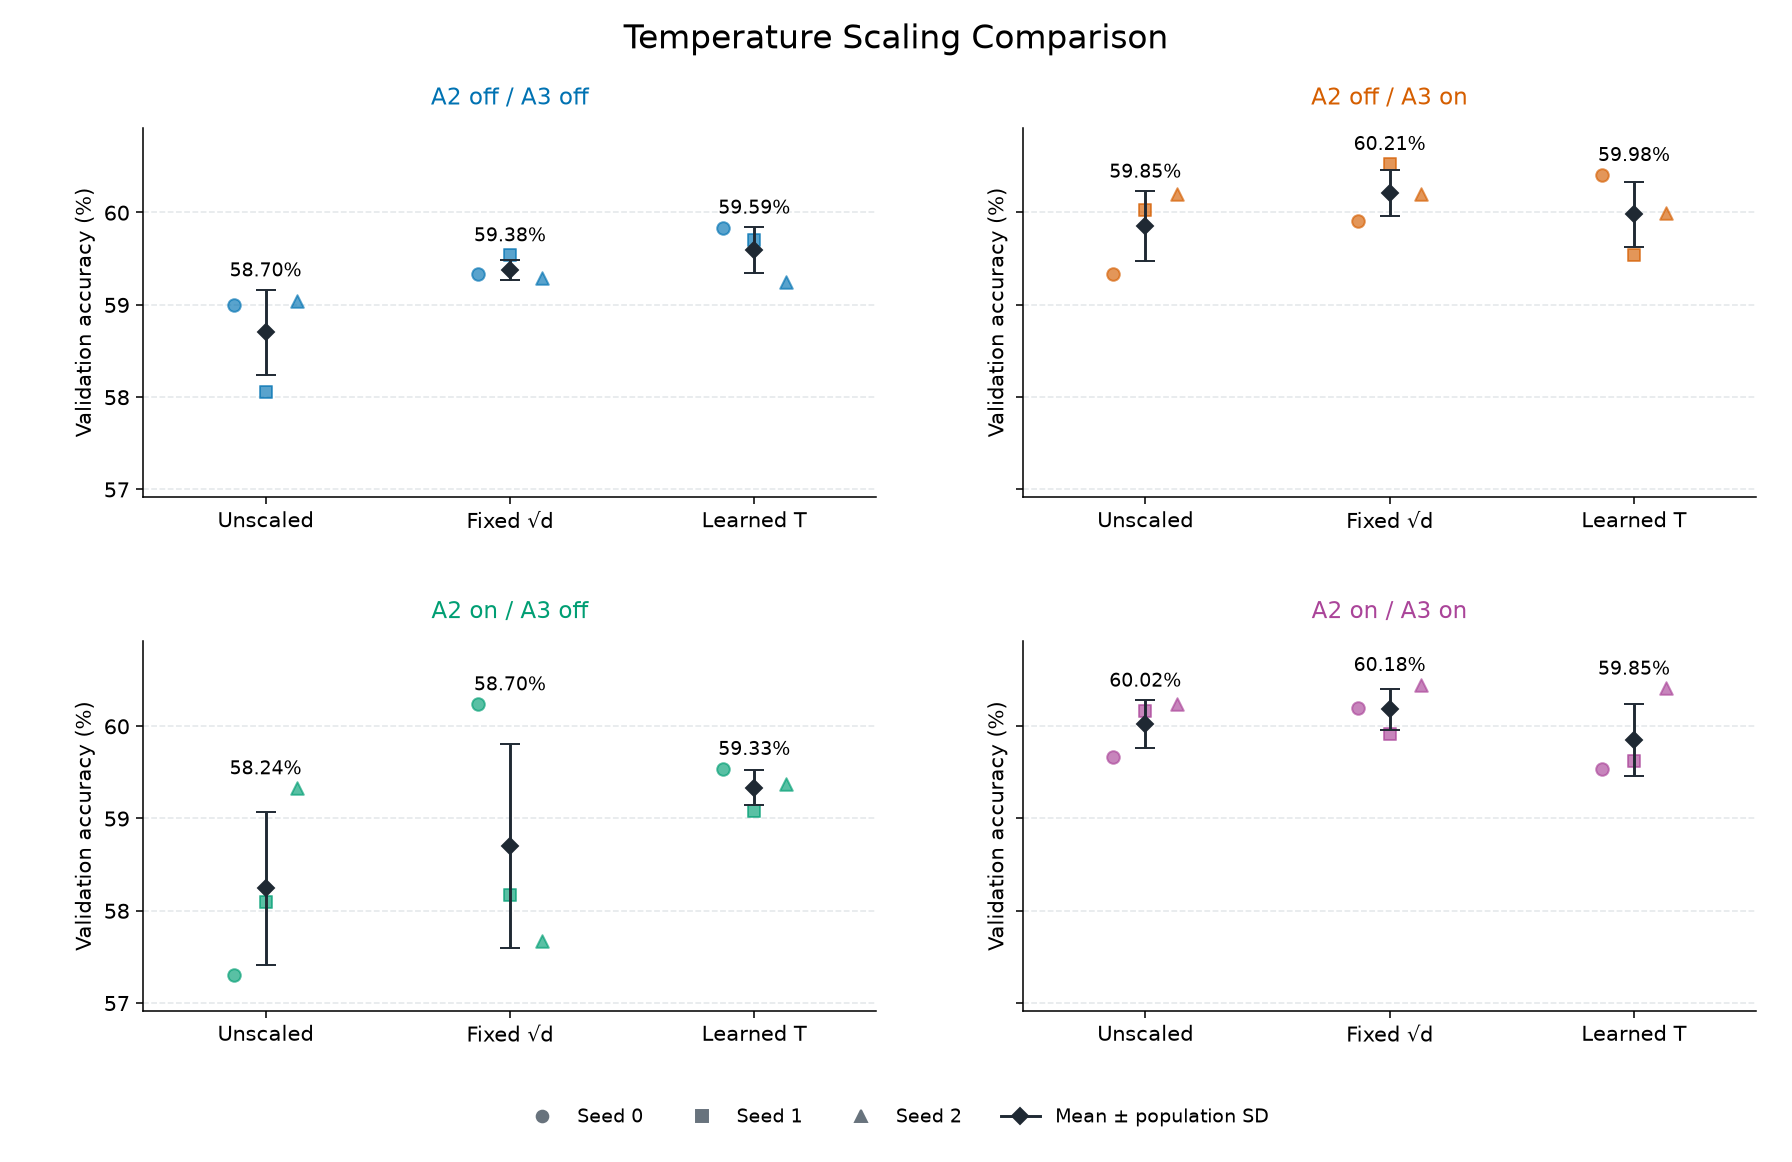

**Figure 3 — Step 15C.** Four A2/A3 combinations × three temperature modes, each with three seeds. Temperature applies only to A1 solution-attention scores. Fixed √d uses T = √200 ≈ 14.1421; the learned temperature starts at √d. Shared axis limits make differences and seed variability comparable.

In [4]:
# @title Step 17.4: Temperature Scaling Comparison
with step17_plt.rc_context(STEP17_STYLE):
    step17_fig, step17_axes = step17_plt.subplots(2, 2, figsize=(12.8, 8.3), sharey=True)
    step17_limits = step17_accuracy_limits(step17_summary[step17_summary.stage == '15C'])
    for step17_ax, (step17_switch, step17_spec) in zip(step17_axes.flat, STEP17_SWITCHES.items()):
        step17_rows = [step17_get_row('15C', step17_switch, mode) for mode in STEP17_MODES]
        step17_plot_accuracy(step17_ax, step17_rows, STEP17_MODE_LABELS, step17_spec['color'])
        step17_ax.set_title(step17_spec['label'], color=step17_spec['color'])
        step17_ax.set_ylim(*step17_limits)
    step17_fig.suptitle('Temperature Scaling Comparison', fontsize=17, y=.98)
    step17_fig.legend(handles=step17_seed_legend(), loc='lower center', bbox_to_anchor=(.5, .015), ncol=4, frameon=False)
    step17_fig.subplots_adjust(left=.08, right=.98, bottom=.13, top=.89, wspace=.20, hspace=.39)
    step17_show_figure('temperature', step17_fig,
        '**Figure 3 — Step 15C.** Four A2/A3 combinations × three temperature modes, each with three seeds. '
        'Temperature applies only to A1 solution-attention scores. Fixed √d uses T = √200 ≈ 14.1421; '
        'the learned temperature starts at √d. Shared axis limits make differences and seed variability comparable.')


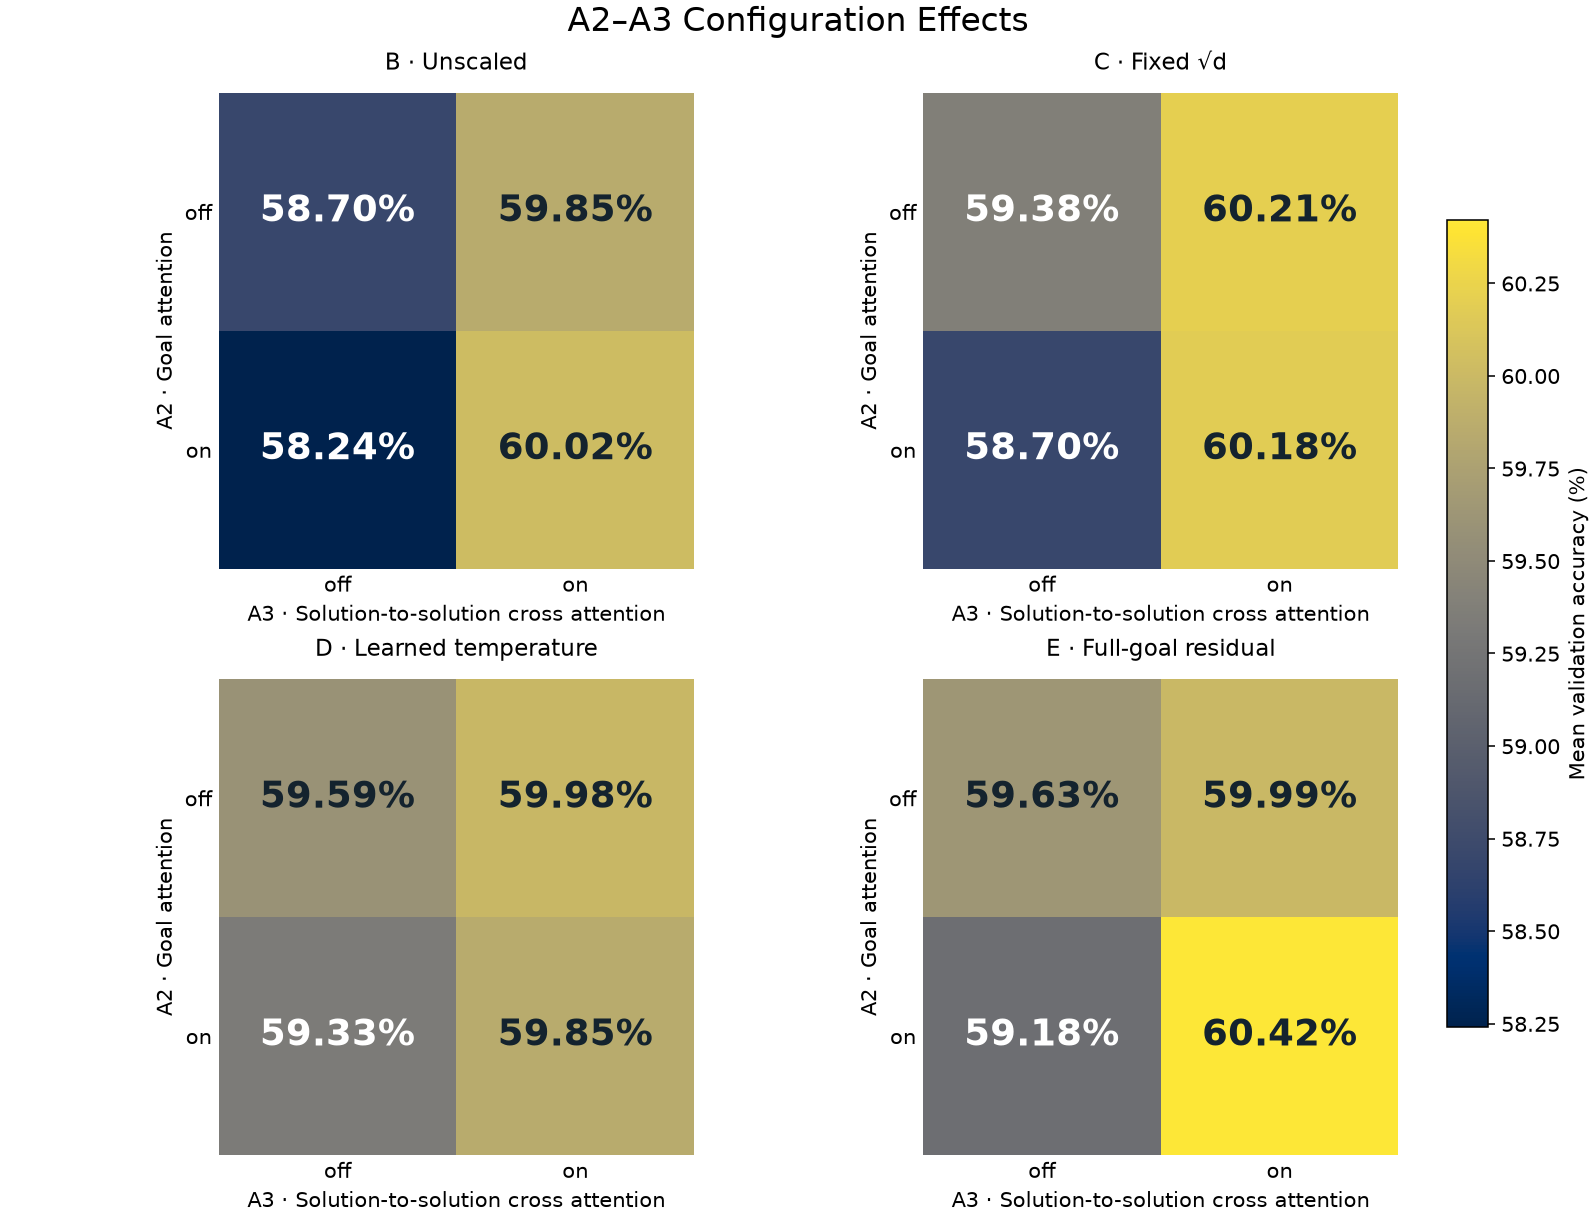

**Figure 4 — Mean accuracy across the A2/A3 switch matrix.** All panels share one color scale. A1 is goal-guided and mean mixing is enabled throughout. E adds a separate full-goal residual in all four cells, including A2 off. These mean-only heatmaps show configuration patterns; Figures 2–3 show seed variability. C/unscaled and C/learned are represented by their B and D design counterparts; consult the provenance table if updated snapshots no longer have matching results.

In [5]:
# @title Step 17.5: A2–A3 Configuration Effects
with step17_plt.rc_context(STEP17_STYLE):
    step17_heatmap_specs = [
        ('15B', None, 'B · Unscaled'),
        ('15C', 'fixed_sqrt_d', 'C · Fixed √d'),
        ('15D', None, 'D · Learned temperature'),
        ('15E', None, 'E · Full-goal residual'),
    ]
    step17_matrices = []
    for step17_stage, step17_mode, _ in step17_heatmap_specs:
        step17_matrices.append(step17_np.array([
            [step17_get_row(step17_stage, f'{a2}{a3}', step17_mode).mean_accuracy * 100 for a3 in (0, 1)]
            for a2 in (0, 1)
        ]))
    step17_vmin = min(matrix.min() for matrix in step17_matrices)
    step17_vmax = max(matrix.max() for matrix in step17_matrices)
    if step17_vmin == step17_vmax:
        step17_vmin, step17_vmax = step17_vmin - .1, step17_vmax + .1
    step17_fig, step17_axes = step17_plt.subplots(2, 2, figsize=(11.4, 8.7), layout='constrained')
    for step17_ax, step17_matrix, (_, _, step17_title) in zip(step17_axes.flat, step17_matrices, step17_heatmap_specs):
        step17_image = step17_ax.imshow(step17_matrix, cmap='cividis', vmin=step17_vmin, vmax=step17_vmax, aspect='equal')
        for step17_a2 in (0, 1):
            for step17_a3 in (0, 1):
                step17_value = step17_matrix[step17_a2, step17_a3]
                step17_text_color = 'white' if (step17_value - step17_vmin) / (step17_vmax - step17_vmin) < .55 else '#14232E'
                step17_ax.text(step17_a3, step17_a2, f'{step17_value:.2f}%', ha='center', va='center',
                               fontsize=19, weight='bold', color=step17_text_color)
        step17_ax.set_xticks([0, 1], ['off', 'on'])
        step17_ax.set_yticks([0, 1], ['off', 'on'])
        step17_ax.set_xlabel('A3 · Solution-to-solution cross attention')
        step17_ax.set_ylabel('A2 · Goal attention')
        step17_ax.set_title(step17_title)
        step17_ax.tick_params(length=0)
        for step17_spine in step17_ax.spines.values():
            step17_spine.set_visible(False)
    step17_fig.suptitle('A2–A3 Configuration Effects', fontsize=17)
    step17_fig.colorbar(step17_image, ax=step17_axes.ravel().tolist(), shrink=.76, pad=.035, label='Mean validation accuracy (%)')
    step17_show_figure('switches', step17_fig,
        '**Figure 4 — Mean accuracy across the A2/A3 switch matrix.** All panels share one color scale. '
        'A1 is goal-guided and mean mixing is enabled throughout. E adds a separate full-goal residual in all four cells, '
        'including A2 off. These mean-only heatmaps show configuration patterns; Figures 2–3 show seed variability. '
        'C/unscaled and C/learned are represented by their B and D design counterparts; consult the provenance table '
        'if updated snapshots no longer have matching results.')


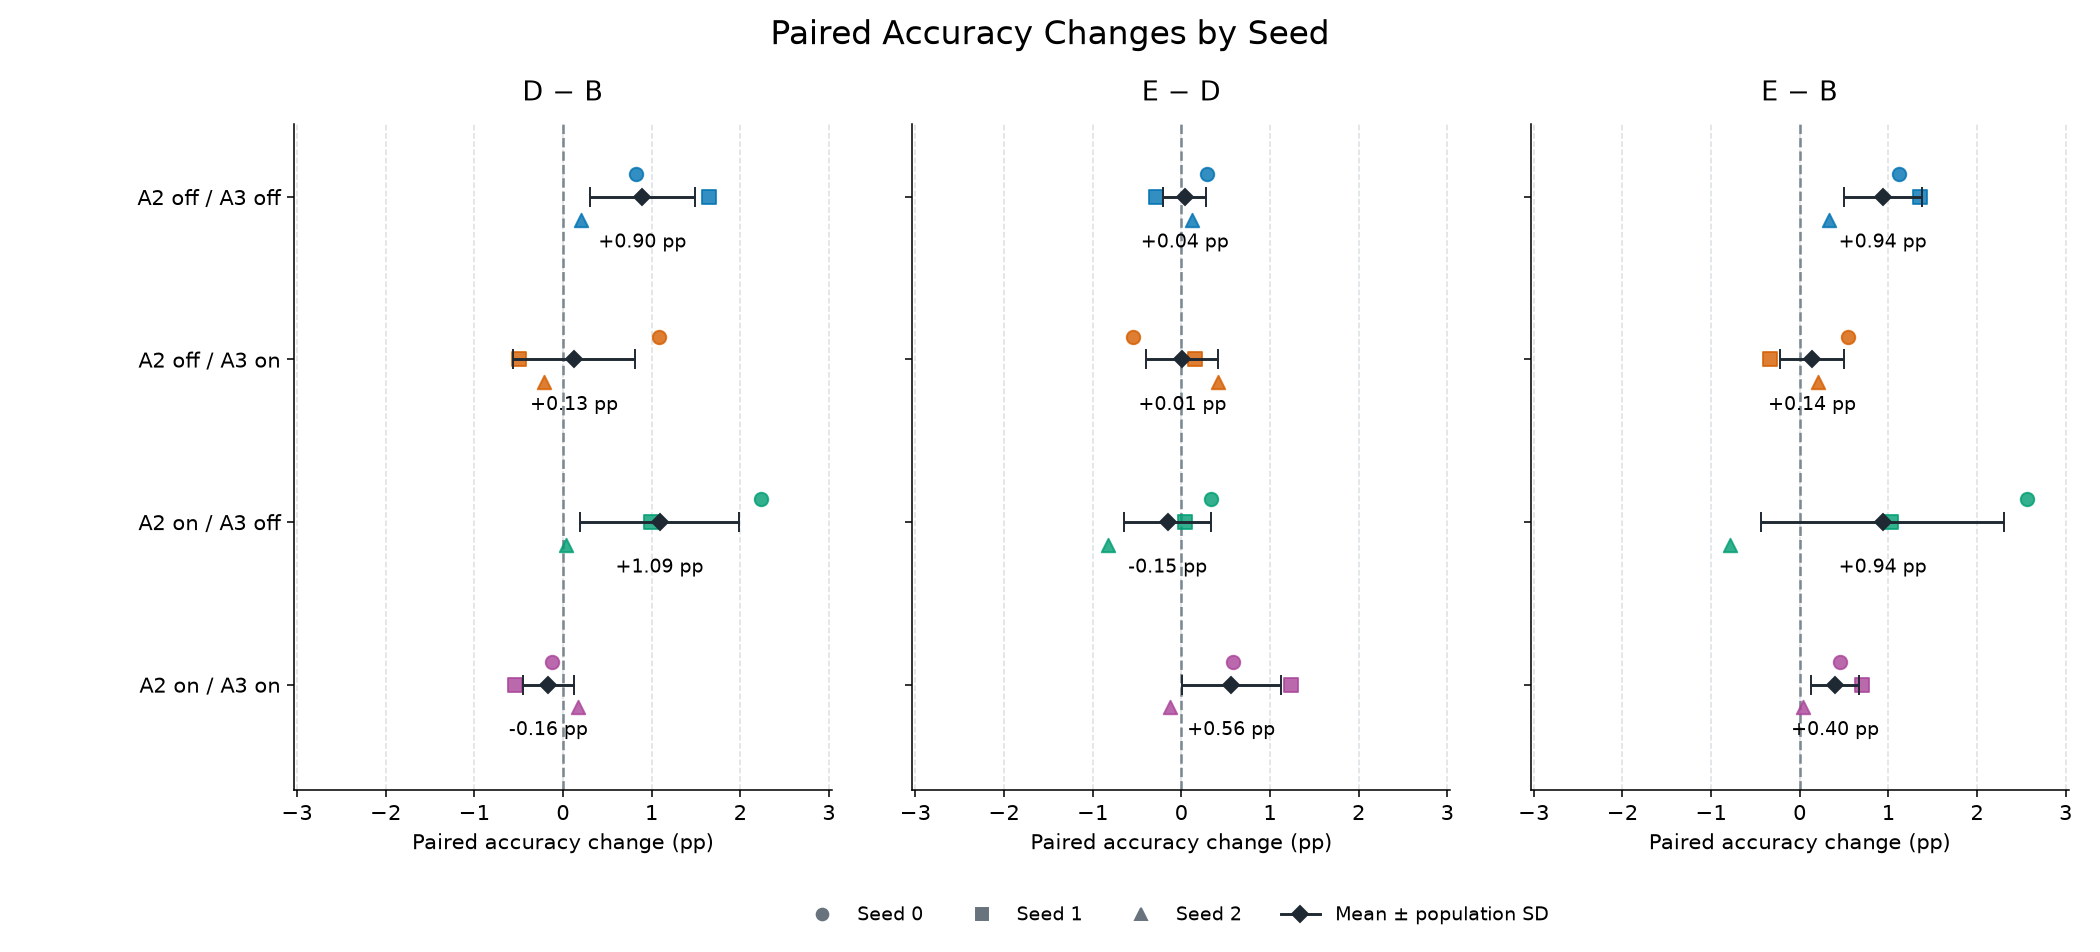

**Figure 5 — Within-seed comparisons.** Each point is later-stage accuracy minus earlier-stage accuracy for the same A2/A3 configuration and seed. Error bars are the population SD of the three paired deltas, not a combination of the two stages’ SDs. Positive values favor the later stage. Changes are approximate because the source seed accuracies were printed to four decimal places; they can differ slightly from differences between the reported rounded means. n = 3; no significance claim is made.

In [6]:
# @title Step 17.6: Paired Accuracy Changes by Seed
step17_pairs = {label: step17_paired_deltas(step17_seeds, later, earlier)
                for label, later, earlier in [('D − B', '15D', '15B'), ('E − D', '15E', '15D'), ('E − B', '15E', '15B')]}
with step17_plt.rc_context(STEP17_STYLE):
    step17_fig, step17_axes = step17_plt.subplots(1, 3, figsize=(15, 6.8), sharey=True, sharex=True)
    step17_bound = max(abs(value) for pair in step17_pairs.values() for value in pair.delta_pp)
    for step17_pair in step17_pairs.values():
        for _, step17_group in step17_pair.groupby('switch_id'):
            step17_bound = max(step17_bound, abs(step17_group.delta_pp.mean()) + step17_group.delta_pp.std(ddof=0))
    step17_bound = max(.2, step17_bound * 1.18)
    for step17_ax, (step17_label, step17_pair) in zip(step17_axes, step17_pairs.items()):
        step17_ax.axvline(0, color='#7B8791', linestyle='--', linewidth=1.3)
        for step17_y, (step17_switch, step17_spec) in enumerate(STEP17_SWITCHES.items()):
            step17_values = step17_pair[step17_pair.switch_id == step17_switch].set_index('seed').delta_pp
            for step17_seed, step17_marker in STEP17_SEED_MARKERS.items():
                step17_ax.scatter(step17_values.loc[step17_seed], step17_y + (step17_seed - 1) * .14,
                                  marker=step17_marker, color=step17_spec['color'], s=48, alpha=.8, zorder=3)
            step17_mean, step17_sd = step17_values.mean(), step17_values.std(ddof=0)
            step17_ax.errorbar(step17_mean, step17_y, xerr=step17_sd, fmt='D', color='#1F2933', capsize=5, markersize=6, zorder=4)
            step17_ax.annotate(f'{step17_mean:+.2f} pp', (step17_mean, step17_y), xytext=(0, -26),
                               textcoords='offset points', ha='center', fontsize=10)
        step17_ax.set_title(step17_label, fontsize=14)
        step17_ax.set_yticks(range(4), [spec['label'] for spec in STEP17_SWITCHES.values()])
        step17_ax.set_ylim(3.65, -.45)
        step17_ax.set_xlim(-step17_bound, step17_bound)
        step17_ax.set_xlabel('Paired accuracy change (pp)')
        step17_ax.grid(axis='x', color='#DCE1E5', linestyle='--')
        step17_ax.set_axisbelow(True)
    step17_fig.suptitle('Paired Accuracy Changes by Seed', fontsize=17, y=.98)
    step17_fig.legend(handles=step17_seed_legend(), loc='lower center', bbox_to_anchor=(.56, .01), ncol=4, frameon=False)
    step17_fig.subplots_adjust(left=.14, right=.985, top=.87, bottom=.17, wspace=.15)
    step17_show_figure('paired', step17_fig,
        '**Figure 5 — Within-seed comparisons.** Each point is later-stage accuracy minus earlier-stage accuracy '
        'for the same A2/A3 configuration and seed. Error bars are the population SD of the three paired deltas, '
        'not a combination of the two stages’ SDs. Positive values favor the later stage. '
        'Changes are approximate because the source seed accuracies were printed to four decimal places; '
        'they can differ slightly from differences between the reported rounded means. n = 3; no significance claim is made.')


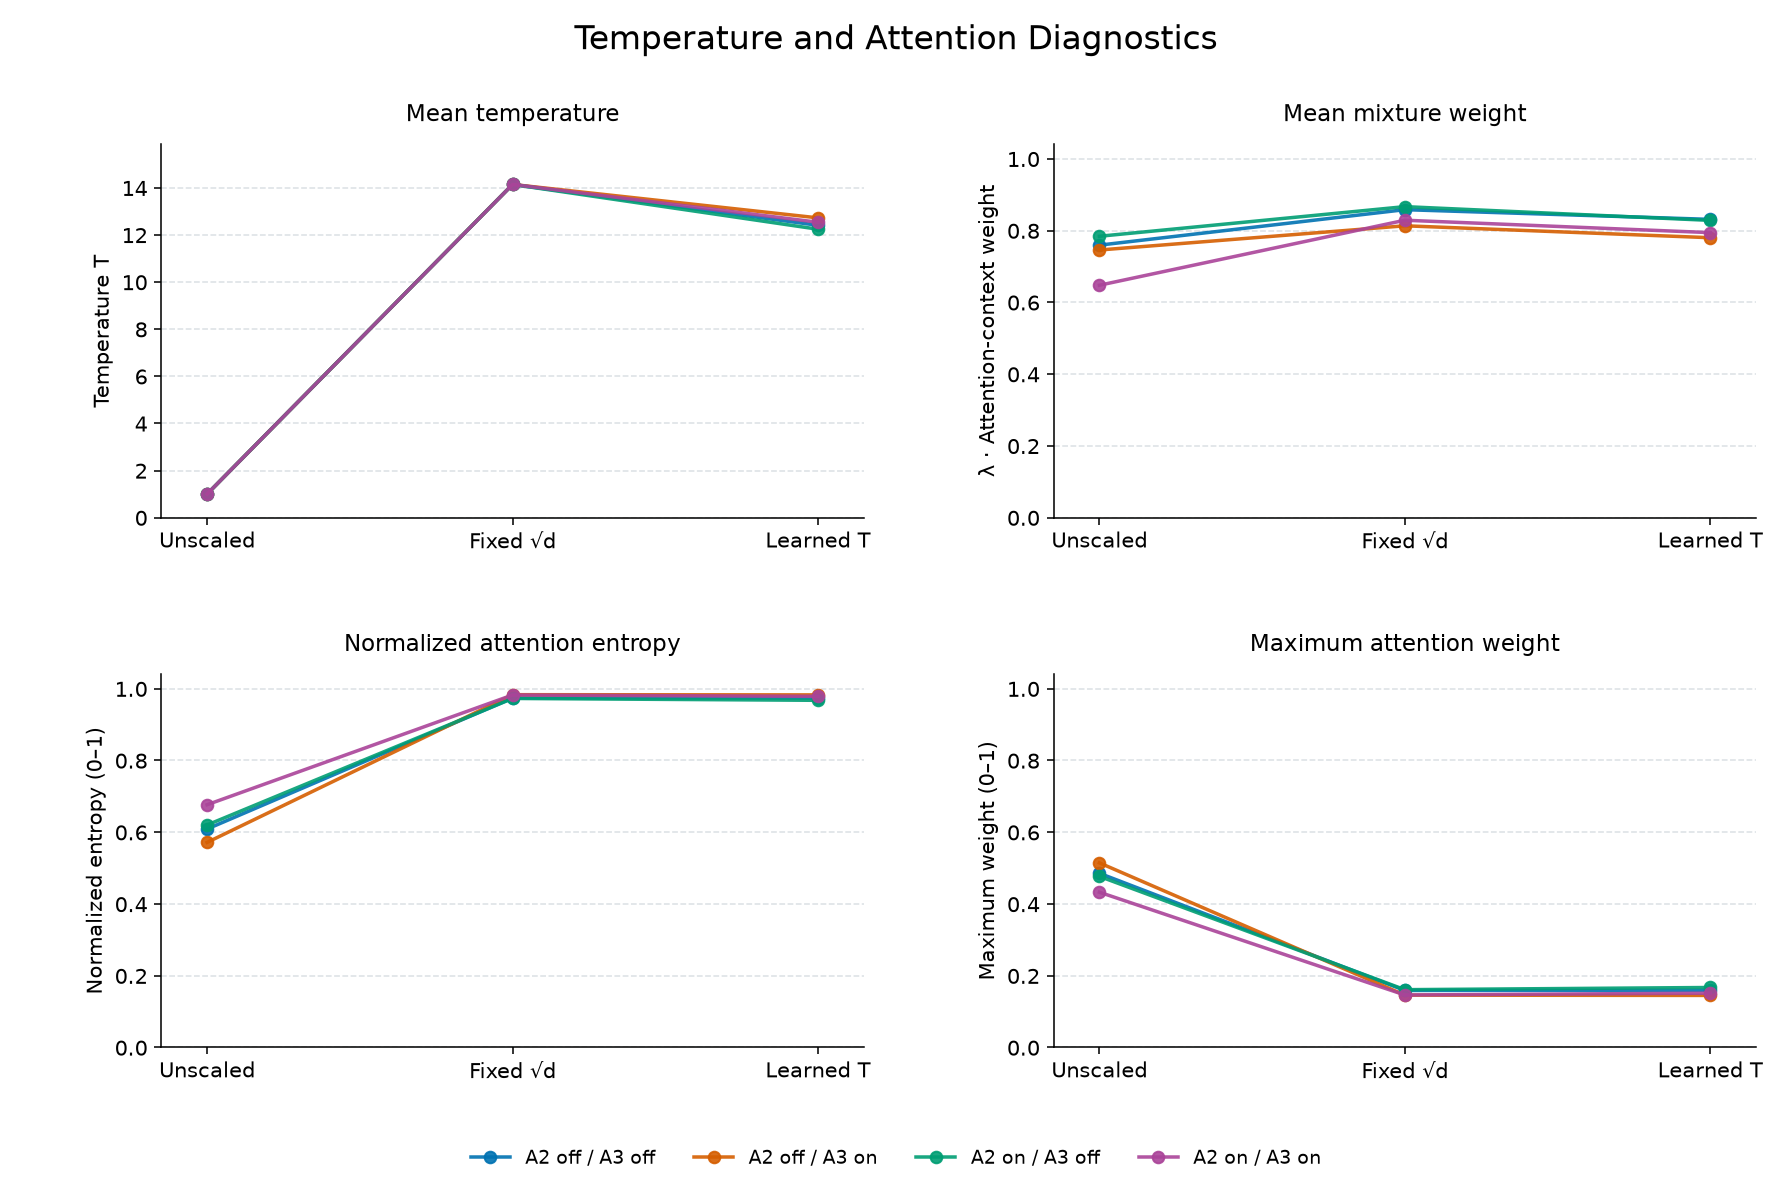

**Figure 6 — Step 15C aggregate diagnostics.** Entropy and maximum weight describe A1’s raw solution-attention distribution before mean mixing, computed per sequence over valid tokens and then averaged over sequences, both solution branches and seeds as in the source diagnostics. Padding is excluded. Higher normalized entropy and lower maximum weight indicate more diffuse attention. λ weights the attention context in the context mixture; it is not a percentage of the model’s causal reliance on attention. Lines connect categorical temperature settings for readability. Seed-level diagnostic SDs and E diagnostic values are unavailable in these summary outputs, so none are invented.

In [7]:
# @title Step 17.7: Temperature and Attention Diagnostics
with step17_plt.rc_context(STEP17_STYLE):
    step17_fig, step17_axes = step17_plt.subplots(2, 2, figsize=(12.8, 8.6))
    step17_metric_specs = [
        ('mean_temperature', 'Mean temperature', 'Temperature T'),
        ('mean_lambda', 'Mean mixture weight', 'λ · Attention-context weight'),
        ('overall_normalized_entropy', 'Normalized attention entropy', 'Normalized entropy (0–1)'),
        ('overall_maximum_attention_weight', 'Maximum attention weight', 'Maximum weight (0–1)'),
    ]
    for step17_ax, (step17_metric, step17_title, step17_ylabel) in zip(step17_axes.flat, step17_metric_specs):
        for step17_switch, step17_spec in STEP17_SWITCHES.items():
            step17_values = step17_diagnostics[step17_diagnostics.switch_id == step17_switch].set_index('temperature_mode').loc[list(STEP17_MODES), step17_metric]
            step17_ax.plot(range(3), step17_values, marker='o', markersize=6, linewidth=1.8,
                           color=step17_spec['color'], label=step17_spec['label'], alpha=.9)
        step17_ax.set_xticks(range(3), STEP17_MODE_LABELS)
        step17_ax.set_ylabel(step17_ylabel)
        step17_ax.set_title(step17_title)
        step17_ax.set_xlim(-.15, 2.15)
        if step17_metric == 'mean_temperature':
            step17_ax.set_ylim(0, step17_diagnostics[step17_metric].max() * 1.12)
        else:
            step17_ax.set_ylim(0, 1.04)
        step17_ax.grid(axis='y', color='#DCE1E5', linestyle='--')
        step17_ax.set_axisbelow(True)
    step17_fig.suptitle('Temperature and Attention Diagnostics', fontsize=17, y=.98)
    step17_fig.legend(*step17_axes[0, 0].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(.5, .015), ncol=4, frameon=False)
    step17_fig.subplots_adjust(left=.09, right=.98, bottom=.13, top=.88, wspace=.27, hspace=.42)
    step17_show_figure('diagnostics', step17_fig,
        '**Figure 6 — Step 15C aggregate diagnostics.** Entropy and maximum weight describe A1’s raw solution-attention '
        'distribution before mean mixing, computed per sequence over valid tokens and then averaged over sequences, '
        'both solution branches and seeds as in the source diagnostics. Padding is excluded. Higher normalized entropy and lower maximum weight indicate '
        'more diffuse attention. λ weights the attention context in the context mixture; it is not a percentage of '
        'the model’s causal reliance on attention. Lines connect categorical temperature settings for readability. '
        'Seed-level diagnostic SDs and E diagnostic values are unavailable in these summary outputs, so none are invented.')


In [8]:
# @title Step 17.8: Results summary and interpretation
# Requires only Step 17.1; conclusions are regenerated from the embedded snapshots.
step17_report_rows = []
step17_report_pairs = {label: step17_paired_deltas(step17_seeds, later, earlier)
                      for label, later, earlier in [('D − B', '15D', '15B'), ('E − D', '15E', '15D'), ('E − B', '15E', '15B')]}
for step17_switch, step17_spec in STEP17_SWITCHES.items():
    step17_values = [step17_get_row(stage, step17_switch, mode).mean_accuracy * 100
                     for stage, mode in [('15B', None), ('15C', 'fixed_sqrt_d'), ('15D', None), ('15E', None)]]
    step17_delta = step17_report_pairs['E − D'].query('switch_id == @step17_switch').delta_pp
    step17_report_rows.append([step17_spec['label'], *[f'{v:.2f}' for v in step17_values],
                              f'{step17_delta.mean():+.2f} ± {step17_delta.std(ddof=0):.2f}'])
step17_display(Step17Markdown('### Results summary\nAccuracy columns are reported means (%). E − D is the paired mean ± population SD (percentage points).'))
step17_table(['Configuration', 'B (%)', 'C fixed (%)', 'D (%)', 'E (%)', 'E − D (pp)'], step17_report_rows, right=(1, 2, 3, 4, 5))

step17_c_improvements, step17_c_non_improvements = [], []
step17_temperature_winners = []
for step17_switch, step17_spec in STEP17_SWITCHES.items():
    step17_u = step17_get_row('15C', step17_switch, 'unscaled')
    step17_f = step17_get_row('15C', step17_switch, 'fixed_sqrt_d')
    step17_l = step17_get_row('15C', step17_switch, 'learned_temperature')
    step17_difference = 100 * (step17_l.mean_accuracy - step17_u.mean_accuracy)
    (step17_c_improvements if step17_difference > 0 else step17_c_non_improvements).append(
        f"{step17_spec['label']} ({step17_difference:+.2f} pp)")
    step17_winner = 'Learned T' if step17_l.mean_accuracy > step17_f.mean_accuracy else ('Fixed √d' if step17_l.mean_accuracy < step17_f.mean_accuracy else 'Tie at displayed precision')
    step17_temperature_winners.append([step17_spec['label'], step17_winner, f'{100 * (step17_l.mean_accuracy - step17_f.mean_accuracy):+.2f}'])
step17_table(['Configuration', 'Higher mean: learned vs fixed', 'Learned − fixed (pp)'], step17_temperature_winners, right=(2,))
step17_display(Step17Markdown(
    f'**Temperature is configuration-dependent.** Learned temperature exceeds unscaled in '
    f'{len(step17_c_improvements)}/4 configurations. Improvements: {"; ".join(step17_c_improvements) or "none"}. '
    f'Non-improvements: {"; ".join(step17_c_non_improvements) or "none"}. '
    'The table above compares learned and fixed scaling within each configuration. '
    'A trainable temperature is therefore an additional modeling choice whose benefit must be checked against fixed scaling.'
))

step17_component_rows = []
for step17_label, step17_pair in step17_report_pairs.items():
    for step17_switch, step17_spec in STEP17_SWITCHES.items():
        step17_values = step17_pair[step17_pair.switch_id == step17_switch].sort_values('seed').delta_pp
        step17_component_rows.append([step17_label, step17_spec['label'],
                                     '[' + ', '.join(f'{v:+.2f}' for v in step17_values) + ']',
                                     f'{step17_values.mean():+.2f}', f'{step17_values.std(ddof=0):.2f}'])
step17_table(['Comparison', 'Configuration', 'Seed 0, 1, 2 changes (pp)', 'Mean (pp)', 'SD (pp)'],
             step17_component_rows, right=(3, 4))
step17_e_d = step17_report_pairs['E − D'].groupby('switch_id').delta_pp.mean()
step17_best_residual = step17_e_d.idxmax()
step17_declines = [STEP17_SWITCHES[key]['label'] for key, value in step17_e_d.items() if value < 0]
step17_display(Step17Markdown(
    '**Separate the added components.** D − B describes adding learned temperature to the B design. '
    'E − D describes adding the full-goal residual to D; E − B combines both changes. '
    f'The largest E − D paired mean is {step17_e_d.loc[step17_best_residual]:+.2f} pp for '
    f'{STEP17_SWITCHES[step17_best_residual]["label"]}. '
    f'Configurations with a negative E − D paired mean: {"; ".join(step17_declines) or "none"}. '
    'The residual can supply token-level goal context to the A1 branch, but these results do not establish a uniform advantage.'
))

step17_best_e = step17_summary[step17_summary.stage == '15E'].sort_values('mean_accuracy', ascending=False).iloc[0]
step17_best_base = step17_summary[step17_summary.stage == '13.5'].sort_values('mean_accuracy', ascending=False).iloc[0]
step17_best_gap = 100 * (step17_best_e.mean_accuracy - step17_best_base.mean_accuracy)
step17_comparison_text = ('They tie at the displayed precision.' if abs(step17_best_gap) < 1e-9
                          else f'The difference between those displayed means is {step17_best_gap:+.2f} pp.')
step17_display(Step17Markdown(
    f'**Compare with the original baselines.** Best E mean: {step17_best_e.mean_accuracy * 100:.2f}% '
    f'({step17_best_e.short_label}); best Step 13.5 mean: {step17_best_base.mean_accuracy * 100:.2f}% '
    f'({step17_best_base.short_label}). {step17_comparison_text} '
    'Selecting the best validation result among many configurations is descriptive model selection, not evidence of a test-set gain. '
    'Figures 1 and 2 retain the original baselines so additional attention components are judged against those controls.'
))

step17_switch_effects = []
for step17_stage, step17_mode, step17_label in [('15B', None, 'B'), ('15C', 'fixed_sqrt_d', 'C fixed'), ('15D', None, 'D'), ('15E', None, 'E')]:
    for step17_a2 in (0, 1):
        step17_off = step17_get_row(step17_stage, f'{step17_a2}0', step17_mode)
        step17_on = step17_get_row(step17_stage, f'{step17_a2}1', step17_mode)
        step17_switch_effects.append((step17_label, step17_a2, 100 * (step17_on.mean_accuracy - step17_off.mean_accuracy)))
step17_positive_cross = sum(value > 0 for _, _, value in step17_switch_effects)
step17_display(Step17Markdown(
    f'**Read A2 and A3 jointly.** In the four panels of Figure 4, turning A3 on increases the reported mean '
    f'in {step17_positive_cross}/8 stage × A2 comparisons. The changes range from '
    f'{min(v for _, _, v in step17_switch_effects):+.2f} to {max(v for _, _, v in step17_switch_effects):+.2f} pp. '
    'A2-on and A2-off results should be compared separately at each A3 setting: the usefulness of goal pooling '
    'can depend on the other attention branches. These are descriptive switch comparisons, not a factorial significance test.'
))

step17_diag_u = step17_diagnostics[step17_diagnostics.temperature_mode == 'unscaled']
step17_diag_scaled = step17_diagnostics[step17_diagnostics.temperature_mode != 'unscaled']
step17_display(Step17Markdown(
    '**Attention patterns and behavior.** Across configurations, unscaled A1 has normalized entropy '
    f'{step17_diag_u.overall_normalized_entropy.min():.3f}–{step17_diag_u.overall_normalized_entropy.max():.3f} '
    f'and maximum weight {step17_diag_u.overall_maximum_attention_weight.min():.3f}–{step17_diag_u.overall_maximum_attention_weight.max():.3f}. '
    'With fixed or learned scaling, these ranges become '
    f'{step17_diag_scaled.overall_normalized_entropy.min():.3f}–{step17_diag_scaled.overall_normalized_entropy.max():.3f} '
    'and '
    f'{step17_diag_scaled.overall_maximum_attention_weight.min():.3f}–{step17_diag_scaled.overall_maximum_attention_weight.max():.3f}, respectively. '
    'The scaled models spread attention more broadly across solution tokens. This is consistent with less concentrated pooling, '
    'but the mixed accuracy outcomes show that diffuse attention alone does not imply better decisions. '
    'These weights precede λ mean mixing and summarize both correct and incorrect cases together. '
    'They neither identify which words matter in an individual prediction nor establish a causal explanation.'
))
step17_display(Step17Markdown('''**Limits of the evidence.** All results use the validation split and three seeds per configuration.
Population SD describes seed variability; it is not a confidence interval. Paired changes computed from displayed
seed values are approximate. Matching C/B or C/D results are never counted as extra replication. No statistical
significance or test-set improvement is claimed. Successful and failed predictions, input texts and token-level
attention were not retained in these summary outputs; the qualitative case analysis remains pending in Step 18.
'''))


### Results summary
Accuracy columns are reported means (%). E − D is the paired mean ± population SD (percentage points).

| Configuration | B (%) | C fixed (%) | D (%) | E (%) | E − D (pp) |
|:---|---:|---:|---:|---:|---:|
| A2 off / A3 off | 58.70 | 59.38 | 59.59 | 59.63 | +0.04 ± 0.24 |
| A2 off / A3 on | 59.85 | 60.21 | 59.98 | 59.99 | +0.01 ± 0.41 |
| A2 on / A3 off | 58.24 | 58.70 | 59.33 | 59.18 | -0.15 ± 0.49 |
| A2 on / A3 on | 60.02 | 60.18 | 59.85 | 60.42 | +0.56 ± 0.56 |

| Configuration | Higher mean: learned vs fixed | Learned − fixed (pp) |
|:---|:---|---:|
| A2 off / A3 off | Learned T | +0.21 |
| A2 off / A3 on | Fixed √d | -0.23 |
| A2 on / A3 off | Learned T | +0.63 |
| A2 on / A3 on | Fixed √d | -0.33 |

**Temperature is configuration-dependent.** Learned temperature exceeds unscaled in 3/4 configurations. Improvements: A2 off / A3 off (+0.89 pp); A2 off / A3 on (+0.13 pp); A2 on / A3 off (+1.09 pp). Non-improvements: A2 on / A3 on (-0.17 pp). The table above compares learned and fixed scaling within each configuration. A trainable temperature is therefore an additional modeling choice whose benefit must be checked against fixed scaling.

| Comparison | Configuration | Seed 0, 1, 2 changes (pp) | Mean (pp) | SD (pp) |
|:---|:---|:---|---:|---:|
| D − B | A2 off / A3 off | [+0.83, +1.65, +0.21] | +0.90 | 0.59 |
| D − B | A2 off / A3 on | [+1.08, -0.49, -0.21] | +0.13 | 0.68 |
| D − B | A2 on / A3 off | [+2.24, +0.99, +0.04] | +1.09 | 0.90 |
| D − B | A2 on / A3 on | [-0.12, -0.54, +0.17] | -0.16 | 0.29 |
| E − D | A2 off / A3 off | [+0.29, -0.29, +0.12] | +0.04 | 0.24 |
| E − D | A2 off / A3 on | [-0.54, +0.16, +0.42] | +0.01 | 0.41 |
| E − D | A2 on / A3 off | [+0.33, +0.04, -0.83] | -0.15 | 0.49 |
| E − D | A2 on / A3 on | [+0.58, +1.24, -0.13] | +0.56 | 0.56 |
| E − B | A2 off / A3 off | [+1.12, +1.36, +0.33] | +0.94 | 0.44 |
| E − B | A2 off / A3 on | [+0.54, -0.33, +0.21] | +0.14 | 0.36 |
| E − B | A2 on / A3 off | [+2.57, +1.03, -0.79] | +0.94 | 1.37 |
| E − B | A2 on / A3 on | [+0.46, +0.70, +0.04] | +0.40 | 0.27 |

**Separate the added components.** D − B describes adding learned temperature to the B design. E − D describes adding the full-goal residual to D; E − B combines both changes. The largest E − D paired mean is +0.56 pp for A2 on / A3 on. Configurations with a negative E − D paired mean: A2 on / A3 off. The residual can supply token-level goal context to the A1 branch, but these results do not establish a uniform advantage.

**Compare with the original baselines.** Best E mean: 60.42% (A2 on / A3 on); best Step 13.5 mean: 60.42% (Cross + goal attention). They tie at the displayed precision. Selecting the best validation result among many configurations is descriptive model selection, not evidence of a test-set gain. Figures 1 and 2 retain the original baselines so additional attention components are judged against those controls.

**Read A2 and A3 jointly.** In the four panels of Figure 4, turning A3 on increases the reported mean in 8/8 stage × A2 comparisons. The changes range from +0.36 to +1.78 pp. A2-on and A2-off results should be compared separately at each A3 setting: the usefulness of goal pooling can depend on the other attention branches. These are descriptive switch comparisons, not a factorial significance test.

**Attention patterns and behavior.** Across configurations, unscaled A1 has normalized entropy 0.572–0.677 and maximum weight 0.433–0.515. With fixed or learned scaling, these ranges become 0.968–0.983 and 0.145–0.167, respectively. The scaled models spread attention more broadly across solution tokens. This is consistent with less concentrated pooling, but the mixed accuracy outcomes show that diffuse attention alone does not imply better decisions. These weights precede λ mean mixing and summarize both correct and incorrect cases together. They neither identify which words matter in an individual prediction nor establish a causal explanation.

**Limits of the evidence.** All results use the validation split and three seeds per configuration.
Population SD describes seed variability; it is not a confidence interval. Paired changes computed from displayed
seed values are approximate. Matching C/B or C/D results are never counted as extra replication. No statistical
significance or test-set improvement is claimed. Successful and failed predictions, input texts and token-level
attention were not retained in these summary outputs; the qualitative case analysis remains pending in Step 18.


In [9]:
# @title Step 18: Qualitative attention case input (real data required)
# Independent of Step 17 and all training cells. This is an input interface,
# not an inference or training cell, and not a substitute for actual case data.
import numpy as step18_np
from IPython.display import Markdown as Step18Markdown, display as step18_display

ATTENTION_CASE_OUTPUT_SNAPSHOT = []  # Paste actual retained case records here.

# Each record must contain:
# sample_id, split='validation', stage ('15B'/'15C'/'15D'/'15E'),
# configuration (the original full configuration name), seed (0/1/2),
# goal, solution1, solution2 (original input strings),
# gold_label, predicted_label (0 = solution 1, 1 = solution 2),
# tokens = {'goal': [...], 'solution1': [...], 'solution2': [...]},
# valid_mask = {'goal': [...], 'solution1': [...], 'solution2': [...]},
# attention = {'sol1_alpha': [...], 'sol2_alpha': [...], ...}.
# Token order and masks must match the actual model input, including truncation.
# valid_mask entries are booleans or 0/1; False marks padding.
# Optional attention branches and their axis order:
# goal_alpha: goal tokens (A2).
# sol1_align / sol2_align: solution1 × solution2 / solution2 × solution1 (A3).
# sol1_goal_cross_alpha / sol2_goal_cross_alpha: solution1/2 × goal (E residual).
# Optional metadata: probabilities, temperature, lambda, beta, switch settings.
# Keep real successes AND real failures; do not synthesize weights from accuracy.


def step18_validate_cases(records):
    if not isinstance(records, list):
        raise ValueError('Case snapshot must be a list of real case dictionaries.')
    required = {'sample_id', 'split', 'stage', 'configuration', 'seed', 'goal', 'solution1', 'solution2',
                'gold_label', 'predicted_label', 'tokens', 'valid_mask', 'attention'}
    seen = set()
    for index, case in enumerate(records):
        if not isinstance(case, dict) or not required.issubset(case):
            raise ValueError(f'Case {index}: required fields are missing; see the input schema above.')
        if case['split'] != 'validation' or case['stage'] not in {'15B', '15C', '15D', '15E'}:
            raise ValueError(f'Case {index}: specify the validation split and a supported model stage.')
        if case['seed'] not in (0, 1, 2) or case['gold_label'] not in (0, 1) or case['predicted_label'] not in (0, 1):
            raise ValueError(f'Case {index}: invalid seed or label; labels use 0 = solution 1, 1 = solution 2.')
        if not all(isinstance(case[key], str) and case[key].strip() for key in ('sample_id', 'configuration', 'goal', 'solution1', 'solution2')):
            raise ValueError(f'Case {index}: original inputs and identifiers must be nonempty strings.')
        identity = tuple(case[key] for key in ('sample_id', 'stage', 'configuration', 'seed'))
        if identity in seen:
            raise ValueError(f'Case {index}: duplicate model/sample/seed identity.')
        seen.add(identity)
        if not all(isinstance(case[key], dict) for key in ('tokens', 'valid_mask', 'attention')):
            raise ValueError(f'Case {index}: tokens, valid_mask and attention must be dictionaries.')
        masks = {}
        for field in ('goal', 'solution1', 'solution2'):
            tokens = case['tokens'].get(field)
            if not isinstance(tokens, list) or not tokens or not all(isinstance(token, str) for token in tokens):
                raise ValueError(f'Case {index}: missing token sequence for {field}.')
            mask = step18_np.asarray(case['valid_mask'].get(field, []))
            if mask.shape != (len(tokens),) or not step18_np.isin(mask, [0, 1]).all() or not mask.any():
                raise ValueError(f'Case {index}: {field} needs an aligned valid-token mask.')
            masks[field] = mask.astype(bool)
        branches = {
            'sol1_alpha': (None, 'solution1'), 'sol2_alpha': (None, 'solution2'),
            'goal_alpha': (None, 'goal'),
            'sol1_align': ('solution1', 'solution2'), 'sol2_align': ('solution2', 'solution1'),
            'sol1_goal_cross_alpha': ('solution1', 'goal'), 'sol2_goal_cross_alpha': ('solution2', 'goal'),
        }
        if not {'sol1_alpha', 'sol2_alpha'}.issubset(case['attention']):
            raise ValueError(f'Case {index}: actual A1 weights for both solutions are required.')
        for branch, raw in case['attention'].items():
            if branch not in branches:
                raise ValueError(f'Case {index}: unsupported attention branch {branch!r}.')
            query, key = branches[branch]
            values = step18_np.asarray(raw, dtype=float)
            shape = (len(masks[key]),) if query is None else (len(masks[query]), len(masks[key]))
            if values.shape != shape or not step18_np.isfinite(values).all() or (values < 0).any():
                raise ValueError(f'Case {index}: {branch} has invalid dimensions or weights.')
            valid_rows = values if query is None else values[masks[query]]
            if not step18_np.allclose(valid_rows[..., ~masks[key]], 0, atol=1e-6):
                raise ValueError(f'Case {index}: {branch} assigns attention to padding keys.')
            if not step18_np.allclose(valid_rows[..., masks[key]].sum(axis=-1), 1, atol=1e-4):
                raise ValueError(f'Case {index}: {branch} must sum to one over valid keys.')
    return records


step18_cases = step18_validate_cases(ATTENTION_CASE_OUTPUT_SNAPSHOT)
if not step18_cases:
    step18_display(Step18Markdown('''### Qualitative attention analysis — pending real case outputs
No token-level attention/prediction outputs are available in this snapshot. Aggregate accuracy, entropy and λ
cannot reconstruct the original inputs, gold answers, predictions or attention maps. **No case heatmaps have been generated.**

To complete the qualitative analysis, retain real correct and incorrect validation cases using the documented
record schema above. Each future case figure should show the original goal and both candidate solutions,
the gold answer, the prediction and correctly masked token labels alongside the attention map.
Compare relevant branches on the same sample where possible. Describe observed word alignments and failure patterns,
while treating attention weights as a description of computation rather than proof of why a prediction was made.

This cell only validates embedded case data. It performs no training, inference or file loading.
'''))
else:
    step18_successes = sum(case['gold_label'] == case['predicted_label'] for case in step18_cases)
    step18_failures = len(step18_cases) - step18_successes
    step18_display(Step18Markdown(
        f'Validated {len(step18_cases)} real case records: {step18_successes} correct and {step18_failures} incorrect. '
        'The case-rendering and qualitative interpretation stage is pending; this cell provides the input interface only. '
        + ('Include both successful and failed predictions before drawing comparative conclusions.'
           if not step18_successes or not step18_failures else '')
    ))


### Qualitative attention analysis — pending real case outputs
No token-level attention/prediction outputs are available in this snapshot. Aggregate accuracy, entropy and λ
cannot reconstruct the original inputs, gold answers, predictions or attention maps. **No case heatmaps have been generated.**

To complete the qualitative analysis, retain real correct and incorrect validation cases using the documented
record schema above. Each future case figure should show the original goal and both candidate solutions,
the gold answer, the prediction and correctly masked token labels alongside the attention map.
Compare relevant branches on the same sample where possible. Describe observed word alignments and failure patterns,
while treating attention weights as a description of computation rather than proof of why a prediction was made.

This cell only validates embedded case data. It performs no training, inference or file loading.
